In [6]:
'''qdrant_client.delete_collection(collection_name=STUDY_COLLECTION)
qdrant_client.delete_collection(collection_name=SAMPLE_COLLECTION)

print("Old collections deleted.")'''

'qdrant_client.delete_collection(collection_name=STUDY_COLLECTION)\nqdrant_client.delete_collection(collection_name=SAMPLE_COLLECTION)\n\nprint("Old collections deleted.")'

In [1]:

import sys
print(sys.executable)

d:\GEO-LLM\venv\Scripts\python.exe


In [2]:
# ============================================================
# Cell 1 — Imports, Connections, and Model Initialization
# ============================================================
# This cell sets up everything needed across the whole notebook:
# - All library imports
# - Qdrant connection
# - Dense embedder (PubMedBERT)
# - Sparse embedder (SPLADE via FastEmbed)
# - Cross-encoder for reranking
# - Groq LLM client
# ============================================================

import os
import re
import json
import math
import uuid
import sqlite3
import requests
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple, Annotated
from collections import defaultdict
from datetime import datetime
from dotenv import load_dotenv

# ── LangGraph / LangChain ──────────────────────────────────
from typing import TypedDict
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages

# ── Qdrant ─────────────────────────────────────────────────
from qdrant_client import QdrantClient
from qdrant_client.models import (
    VectorParams,
    SparseVectorParams,
    SparseIndexParams,
    Distance,
    PointStruct,
    SparseVector,
    Filter,
    FieldCondition,
    MatchValue,
    MatchAny,
    PayloadSchemaType,
    TextIndexParams,
    TokenizerType,
)

# ── Embedding Models ───────────────────────────────────────
from sentence_transformers import SentenceTransformer, CrossEncoder
from fastembed import SparseTextEmbedding

# ── Groq LLM ───────────────────────────────────────────────
from groq import Groq

# ── tqdm for progress bars ─────────────────────────────────
from tqdm import tqdm


# ============================================================
# Environment Variables
# ============================================================

load_dotenv()

groq_api_key = os.getenv("GROQ_API_KEY")
if not groq_api_key:
    raise ValueError("GROQ_API_KEY not found in .env file")

groq_client = Groq(api_key=groq_api_key)
print("Groq client initialized.")


# ============================================================
# Qdrant Connection
# ============================================================

QDRANT_URL = "http://localhost:6333"

qdrant_client = QdrantClient(url=QDRANT_URL)
print("Connected to Qdrant.")
print(qdrant_client.get_collections())


# ============================================================
# Collection Names
# ============================================================

STUDY_COLLECTION  = "geo_study_collection"
SAMPLE_COLLECTION = "geo_sample_collection"


# ============================================================
# Dense Embedder — PubMedBERT (768 dimensions)
# ============================================================

DENSE_EMBED_MODEL = "neuml/pubmedbert-base-embeddings"

dense_embedder = SentenceTransformer(DENSE_EMBED_MODEL)
print(f"Dense embedder loaded: {DENSE_EMBED_MODEL}")


# ============================================================
# Sparse Embedder — SPLADE via FastEmbed
# Used for keyword-aware sparse retrieval inside Qdrant.
# Replaces the previous in-memory BM25 index.
# ============================================================

SPARSE_EMBED_MODEL = "prithivida/Splade_PP_en_v1"

sparse_embedder = SparseTextEmbedding(model_name=SPARSE_EMBED_MODEL)
print(f"Sparse embedder loaded: {SPARSE_EMBED_MODEL}")


# ============================================================
# Cross-Encoder — For Reranking Child Chunks
# Scores (query, chunk_text) pairs to rerank retrieved chunks.
# Runs on CPU, processes up to 512 tokens per pair.
# ============================================================

CROSS_ENCODER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

cross_encoder = CrossEncoder(CROSS_ENCODER_MODEL, max_length=512)
print(f"Cross-encoder loaded: {CROSS_ENCODER_MODEL}")


# ============================================================
# Quick Sanity Check
# ============================================================

print("\n=== Initialization Complete ===")
print(f"Qdrant collections: {[c.name for c in qdrant_client.get_collections().collections]}")

d:\GEO-LLM\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Groq client initialized.
Connected to Qdrant.
collections=[CollectionDescription(name='geo_sample_collection'), CollectionDescription(name='geo_study_collection')]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 553.06it/s, Materializing param=pooler.dense.weight]                               


Dense embedder loaded: neuml/pubmedbert-base-embeddings
Sparse embedder loaded: prithivida/Splade_PP_en_v1


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 641.99it/s, Materializing param=classifier.weight]                                    
BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Cross-encoder loaded: cross-encoder/ms-marco-MiniLM-L-6-v2

=== Initialization Complete ===
Qdrant collections: ['geo_sample_collection', 'geo_study_collection']


In [24]:
# ============================================================
# Cell 2 — Configuration Constants
# ============================================================
# Central place for all tunable parameters used across the
# pipeline. Change values here and they apply everywhere.
# ============================================================


# ============================================================
# Directory Paths
# ============================================================

STUDY_DIR    = "data/studies"     # folder containing study JSON files
SAMPLE_DIR   = "data/samples"     # folder containing sample JSON files
REGISTRY_DIR = "registry"         # folder for tracking indexed documents
CACHE_DIR    = "cache"            # folder for SQLite ontology cache

# Create directories if they don't exist
os.makedirs(REGISTRY_DIR, exist_ok=True)
os.makedirs(CACHE_DIR,    exist_ok=True)


# ============================================================
# Registry File Paths
# ============================================================

STUDY_REGISTRY_PATH  = os.path.join(REGISTRY_DIR, "indexed_studies.json")
SAMPLE_REGISTRY_PATH = os.path.join(REGISTRY_DIR, "indexed_samples.json")


# ============================================================
# Ontology Cache
# ============================================================

# SQLite database file for caching resolved biomedical concepts.
# After first API lookup, all results are stored here locally.
# This avoids repeated API calls for the same terms.
ONTOLOGY_CACHE_DB = os.path.join(CACHE_DIR, "ontology_cache.db")


# ============================================================
# Chunking Parameters (Parent-Child)
# ============================================================

# Number of tokens per child chunk (study text only)
CHUNK_SIZE_TOKENS = 256

# Number of overlapping tokens between consecutive child chunks
# Overlap preserves context at chunk boundaries (~20% of chunk size)
CHUNK_OVERLAP_TOKENS = 50

# Neighbor window for context enrichment after reranking.
# Value of 1 means fetch 1 chunk before and 1 chunk after
# the retrieved child chunk to preserve surrounding context.
NEIGHBOR_WINDOW = 1


# ============================================================
# Retrieval Parameters
# ============================================================

# Number of study chunks to retrieve before reranking.
# Retrieve large, rerank to smaller final set.
TOP_K_STUDY_RETRIEVAL = 250

# Number of sample chunks to retrieve
TOP_K_SAMPLE_RETRIEVAL = 50

# Number of top child chunks to keep after cross-encoder reranking
TOP_K_AFTER_RERANK = 30

TOP_K_SAMPLE_AFTER_RERANK = 10   

# Minimum vector similarity score for a chunk to pass into results.
# Chunks below this threshold are dropped before reranking.
SIM_THRESHOLD = 0.20


# ============================================================
# Hybrid Search Weights
# ============================================================

# Weight for dense vector score (semantic similarity)
ALPHA_DENSE  = 0.65

# Weight for sparse vector score (keyword matching via SPLADE)
ALPHA_SPARSE = 0.35


# ============================================================
# Metadata Boost Values
# ============================================================

# Score bonus added when a chunk's payload exactly matches
# a resolved canonical term from ontology resolution.
# Example: query organism "human" resolves to "Homo sapiens"
# and the chunk payload organism field is "Homo sapiens"
# → this boost is added to its final score.
EXACT_PAYLOAD_MATCH_BOOST = 0.15

# Score bonus added when a chunk's field (e.g. "overall_design")
# matches one of the semantic focus fields identified by the LLM.
# Example: query about experimental design → focus on "overall_design"
# → chunks from that field get this bonus.
FIELD_FOCUS_BOOST = 0.15

FIELD_MATCH_BOOST = 0.10  

# ============================================================
# LLM Models
# ============================================================

# Model used for query understanding (intent + filters + concepts)
# meta-llama/llama-4-scout-17b-16e-instruct # openai/gpt-oss-120b # qwen/qwen3-32b
# llama-3.1-8b-instant
GROQ_QUERY_MODEL = "openai/gpt-oss-120b"

# Model used for final answer generation
GROQ_ANSWER_MODEL = "openai/gpt-oss-120b"


# ============================================================
# Print Config Summary
# ============================================================

print("=== GeoLLM Configuration ===")
print(f"Study dir        : {STUDY_DIR}")
print(f"Sample dir       : {SAMPLE_DIR}")
print(f"Chunk size       : {CHUNK_SIZE_TOKENS} tokens")
print(f"Chunk overlap    : {CHUNK_OVERLAP_TOKENS} tokens")
print(f"Neighbor window  : {NEIGHBOR_WINDOW}")
print(f"Top-K retrieval  : {TOP_K_STUDY_RETRIEVAL} study / {TOP_K_SAMPLE_RETRIEVAL} sample")
print(f"Top-K rerank     : {TOP_K_AFTER_RERANK}")
print(f"Sim threshold    : {SIM_THRESHOLD}")
print(f"Dense weight     : {ALPHA_DENSE}")
print(f"Sparse weight    : {ALPHA_SPARSE}")
print(f"Payload boost    : {EXACT_PAYLOAD_MATCH_BOOST}")
print(f"Field boost      : {FIELD_FOCUS_BOOST}")
print(f"Query model      : {GROQ_QUERY_MODEL}")
print(f"Answer model     : {GROQ_ANSWER_MODEL}")

=== GeoLLM Configuration ===
Study dir        : data/studies
Sample dir       : data/samples
Chunk size       : 256 tokens
Chunk overlap    : 50 tokens
Neighbor window  : 1
Top-K retrieval  : 250 study / 50 sample
Top-K rerank     : 30
Sim threshold    : 0.2
Dense weight     : 0.65
Sparse weight    : 0.35
Payload boost    : 0.15
Field boost      : 0.15
Query model      : openai/gpt-oss-120b
Answer model     : openai/gpt-oss-120b


In [4]:
# ============================================================
# Cell 3 — GeoState (LangGraph State Definition)
# ============================================================
# Defines the shared state object that flows through the
# entire pipeline. Every function reads from and writes
# to this state dictionary.
# ============================================================

from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages


class GeoState(TypedDict):

    # ── Conversation Messages ──────────────────────────────
    # Full list of chat messages (human + assistant turns).
    # add_messages ensures new messages are appended, not replaced.
    messages: Annotated[list[BaseMessage], add_messages]

    # ── Query Understanding Output ─────────────────────────
    # Stores the structured output from the LLM query parser.
    # Contains: intent, operations, filters, concepts,
    #           semantic_focus_fields, query_type,
    #           logical_operator, resolved_organism,
    #           strategy, confidence
    query_info: dict

    # ── Raw Retrieval Results ──────────────────────────────
    # Child chunks returned from hybrid search (dense + sparse)
    # before cross-encoder reranking. Each item is a dict
    # with text, scores, gse_id, field, parent_id, etc.
    retrieved_context: list

    # ── Reranked Results ───────────────────────────────────
    # Study child chunks after cross-encoder reranking,
    # aggregated by gse_id with best chunk per field selected.
    # This is the study-level evidence passed to the answer
    # generator.
    reranked_context: list

    # ── Sample-Level Context ───────────────────────────────
    # Independently-retrieved sample (GSM) hits from the
    # sample collection. NOT restricted to top_gse_ids — this
    # collection is queried on its own so a study with weak
    # study-level text but strong sample-level metadata match
    # can still surface evidence. Passed to the answer generator
    # as a separate "Sample-Level Evidence" section.
    sample_context: list

    # ── Top GSE IDs ────────────────────────────────────────
    # Ordered list of top GSE study IDs after study-side
    # reranking. Used for aggregation display purposes —
    # no longer gates sample retrieval (see sample_context).
    top_gse_ids: list

    # ── Dropped Filters ─────────────────────────────────────
    # Filters extracted by query understanding (Cell 16) that
    # were pruned before retrieval because they matched 0 points
    # in the collection (e.g. a disease not present in any
    # indexed study). Each entry: {field: value}. Passed to
    # generate_answer() so the model can honestly acknowledge
    # unmatched constraints instead of silently presenting the
    # closest available result as a full match.
    dropped_filters: dict

    # ── Session Memory ─────────────────────────────────────
    # Stores summary of previous conversation turns.
    # Used later for follow-up query handling.
    # Each entry: {"query": str, "intent": str,
    #              "top_gse_ids": list, "answer_summary": str}
    # Implemented in the final session memory cell.
    session_memory: list


# ============================================================
# Print confirmation
# ============================================================

print("GeoState defined with fields:")
print("  - messages          (conversation history)")
print("  - query_info        (LLM query understanding output)")
print("  - retrieved_context (raw hybrid search results)")
print("  - reranked_context  (cross-encoder reranked study results)")
print("  - sample_context    (independently retrieved sample results)")
print("  - top_gse_ids       (top study IDs after reranking)")
print("  - dropped_filters   (filters pruned due to 0 matches)")
print("  - session_memory    (conversation memory - used later)")

GeoState defined with fields:
  - messages          (conversation history)
  - query_info        (LLM query understanding output)
  - retrieved_context (raw hybrid search results)
  - reranked_context  (cross-encoder reranked study results)
  - sample_context    (independently retrieved sample results)
  - top_gse_ids       (top study IDs after reranking)
  - dropped_filters   (filters pruned due to 0 matches)
  - session_memory    (conversation memory - used later)


In [5]:
# ============================================================
# Cell 4 — Collection Setup
# ============================================================
# Creates Qdrant collections for study and sample documents.
#
# Each collection stores THREE things per point:
#   1. Dense vector  — semantic meaning (PubMedBERT, 768 dims)
#   2. Sparse vector — keyword matching (SPLADE via FastEmbed)
#   3. Payload       — metadata (gse_id, field, organism, etc.)
# ============================================================

from qdrant_client.models import (
    VectorParams,
    SparseVectorParams,
    SparseIndexParams,
    Distance,
    PayloadSchemaType,
    TextIndexParams,
    TokenizerType,
)


def ensure_collection(
    client            : QdrantClient,
    collection_name   : str,
    dense_vector_size : int = 768
):
    """
    Create a Qdrant collection with both dense and sparse vectors
    if it does not already exist.

    Collection schema:
        vectors:
            "dense"  : VectorParams (768 dims, cosine)
        sparse_vectors:
            "sparse" : SparseVectorParams (SPLADE output)

    Identity payload indexes (KEYWORD / INTEGER):
        gse_id, gsm_id, parent_id, child_index, level, field,
        is_superseries, is_subseries, parent_series_id

    Content payload indexes (TEXT + lowercase tokenizer):
        organism, tissue, disease, assay_type, library_strategy,
        library_source, library_selection, molecule, genotype,
        cell_line, cell_type, specimen, title, status,
        instrument_model, platform_id, strain, source_name

    Args:
        client            : QdrantClient instance
        collection_name   : Name of the collection to create
        dense_vector_size : Dimension of dense embeddings
                            (768 for PubMedBERT)
    """

    # ── Check if collection already exists ─────────────────
    existing_collections = [
        collection.name
        for collection in client.get_collections().collections
    ]

    if collection_name in existing_collections:
        print(f"Collection already exists  : {collection_name}")
        return

    print(f"Creating collection        : {collection_name}")

    # ── Create collection with named dense and sparse vectors
    client.create_collection(
        collection_name = collection_name,
        vectors_config  = {
            # Dense vector from PubMedBERT embeddings
            "dense": VectorParams(
                size     = dense_vector_size,
                distance = Distance.COSINE
            )
        },
        sparse_vectors_config = {
            # Sparse vector from SPLADE (FastEmbed)
            "sparse": SparseVectorParams(
                index = SparseIndexParams(
                    on_disk = False  # keep in memory for fast retrieval
                )
            )
        }
    )

    print(f"Collection created         : {collection_name}")

    # ── Identity / structural fields → KEYWORD or INTEGER ──
    # These are system-generated values with predictable exact
    # casing. Keyword/integer indexes support exact match only.
    # Boolean series relationship flags stored as KEYWORD
    # because Qdrant has no native boolean index type —
    # values will be stored as "true"/"false" strings.

    identity_fields = [
        ("gse_id",           PayloadSchemaType.KEYWORD),
        ("gsm_id",           PayloadSchemaType.KEYWORD),
        ("parent_id",        PayloadSchemaType.KEYWORD),
        ("child_index",      PayloadSchemaType.INTEGER),
        ("level",            PayloadSchemaType.KEYWORD),
        ("field",            PayloadSchemaType.KEYWORD),
        # Series relationship identity fields (new)
        ("is_superseries",   PayloadSchemaType.KEYWORD),
        ("is_subseries",     PayloadSchemaType.KEYWORD),
        ("parent_series_id", PayloadSchemaType.KEYWORD),
        ("subseries_ids",    PayloadSchemaType.KEYWORD),
    ]

    # ── Content / biological fields → TEXT + lowercase ─────
    # These come from GEO metadata and user queries — casing
    # is inconsistent across datasets. TEXT index with word
    # tokenizer and lowercase=True enables case-insensitive
    # token-level matching regardless of how the value was
    # stored or queried.

    content_fields = [
        # Organism and taxonomy
        "organism",
        "strain",           # new — sample biological_metadata
        # Tissue and sample source
        "tissue",
        "source_name",      # new — top-level sample field
        "specimen",
        # Disease and condition
        "disease",
        # Cell identity
        "cell_line",
        "cell_type",
        "genotype",
        # Sequencing and assay
        "assay_type",
        "library_strategy",
        "library_source",
        "library_selection",
        "molecule",
        "instrument_model",
        "platform_id",
        # Study metadata
        "title",
        "status",
    ]

    # ── Create identity indexes ─────────────────────────────
    for field_name, field_type in identity_fields:
        client.create_payload_index(
            collection_name = collection_name,
            field_name      = field_name,
            field_schema    = field_type
        )
        print(f"  Keyword/int index created : {field_name}")

    # ── Create content indexes ──────────────────────────────
    for field_name in content_fields:
        client.create_payload_index(
            collection_name = collection_name,
            field_name      = field_name,
            field_schema    = TextIndexParams(
                type      = "text",
                tokenizer = TokenizerType.WORD,
                lowercase = True,
            )
        )
        print(f"  Text index created        : {field_name}")

    print(f"Collection setup complete  : {collection_name}\n")


# ============================================================
# Initialize Both Collections
# ============================================================
# Uncomment these two lines ONLY if you need to rebuild
# collections from scratch (deletes all existing data):
# qdrant_client.delete_collection(STUDY_COLLECTION)
# qdrant_client.delete_collection(SAMPLE_COLLECTION)

ensure_collection(
    client            = qdrant_client,
    collection_name   = STUDY_COLLECTION,
    dense_vector_size = 768
)

ensure_collection(
    client            = qdrant_client,
    collection_name   = SAMPLE_COLLECTION,
    dense_vector_size = 768
)


# ============================================================
# Verify Collections
# ============================================================

def print_collection_info(client: QdrantClient, collection_name: str):
    """Print basic status info for a collection."""

    info = client.get_collection(collection_name)

    print(f"Collection : {collection_name}")
    print(f"  Points   : {info.points_count}")
    print(f"  Status   : {info.status}")


print("\n=== Collection Verification ===")
print_collection_info(qdrant_client, STUDY_COLLECTION)
print_collection_info(qdrant_client, SAMPLE_COLLECTION)

Collection already exists  : geo_study_collection
Collection already exists  : geo_sample_collection

=== Collection Verification ===
Collection : geo_study_collection
  Points   : 42223
  Status   : green
Collection : geo_sample_collection
  Points   : 34409
  Status   : green


In [6]:
# ============================================================
# Cell 4.5 — Migration: Add Missing Payload Indexes
# ============================================================
# Adds new payload indexes to existing collections without
# recreating them or losing any data.
#
# Changes from previous version:
#   New keyword fields added:
#     - is_superseries, is_subseries, parent_series_id
#     - subseries_ids (KEYWORD array — Qdrant indexes each
#       element in the list separately)
#   New text fields added:
#     - strain      (new sample biological_metadata field)
#     - source_name (new top-level sample field)
#
# Usage:
#   Run once after updating Cell 4 schema to sync existing
#   collections. Safe to run multiple times — already-existing
#   indexes are silently skipped, not duplicated.
# ============================================================

from qdrant_client.models import (
    PayloadSchemaType,
    TextIndexParams,
    TokenizerType,
)


def add_missing_payload_indexes(
    client          : QdrantClient,
    collection_name : str,
    keyword_fields  : list,
    text_fields     : list
):
    """
    Add new payload indexes to an existing collection
    without recreating it or touching existing data.

    Already-existing indexes are caught and silently skipped
    so this function is safe to run multiple times.

    Args:
        client          : QdrantClient instance
        collection_name : Name of the existing collection
        keyword_fields  : List of (field_name, PayloadSchemaType)
                          tuples for keyword/integer indexes
        text_fields     : List of field_name strings for
                          text indexes (word tokenizer, lowercase)
    """

    print(f"Checking indexes for: {collection_name}")

    # ── Keyword / Integer fields ────────────────────────────
    for field_name, field_type in keyword_fields:
        try:
            client.create_payload_index(
                collection_name = collection_name,
                field_name      = field_name,
                field_schema    = field_type
            )
            print(f"  [added]  {field_name} (keyword/integer)")
        except Exception as error:
            # Index already exists — skip silently
            print(f"  [skip]   {field_name} — {error}")

    # ── Text / lowercase fields ─────────────────────────────
    for field_name in text_fields:
        try:
            client.create_payload_index(
                collection_name = collection_name,
                field_name      = field_name,
                field_schema    = TextIndexParams(
                    type      = "text",
                    tokenizer = TokenizerType.WORD,
                    lowercase = True,
                )
            )
            print(f"  [added]  {field_name} (text/lowercase)")
        except Exception as error:
            print(f"  [skip]   {field_name} — {error}")

    print(f"Migration complete: {collection_name}\n")


# ============================================================
# New Fields Added in This Schema Update
# ============================================================
# Run this block once to sync existing collections with the
# new Cell 4 index schema.
#
# Since you are deleting and re-embedding everything anyway,
# this block is here for future use — when you add new fields
# later and do NOT want to re-embed everything again.

NEW_KEYWORD_FIELDS = [
    ("is_superseries",   PayloadSchemaType.KEYWORD),
    ("is_subseries",     PayloadSchemaType.KEYWORD),
    ("parent_series_id", PayloadSchemaType.KEYWORD),
    ("subseries_ids",    PayloadSchemaType.KEYWORD),  # indexes each list element
]

NEW_TEXT_FIELDS = [
    "strain",       # new — sample biological_metadata
    "source_name",  # new — top-level sample field
]

# Apply to both collections
for collection in [STUDY_COLLECTION, SAMPLE_COLLECTION]:
    add_missing_payload_indexes(
        client          = qdrant_client,
        collection_name = collection,
        keyword_fields  = NEW_KEYWORD_FIELDS,
        text_fields     = NEW_TEXT_FIELDS
    )


# ============================================================
# How to Use in Future When Adding New Fields
# ============================================================
# Just call add_missing_payload_indexes() with the new fields:
#
# add_missing_payload_indexes(
#     client          = qdrant_client,
#     collection_name = STUDY_COLLECTION,
#     keyword_fields  = [("new_id_field", PayloadSchemaType.KEYWORD)],
#     text_fields     = ["new_content_field"]
# )

Checking indexes for: geo_study_collection
  [added]  is_superseries (keyword/integer)
  [added]  is_subseries (keyword/integer)
  [added]  parent_series_id (keyword/integer)
  [added]  subseries_ids (keyword/integer)
  [added]  strain (text/lowercase)
  [added]  source_name (text/lowercase)
Migration complete: geo_study_collection

Checking indexes for: geo_sample_collection
  [added]  is_superseries (keyword/integer)
  [added]  is_subseries (keyword/integer)
  [added]  parent_series_id (keyword/integer)
  [added]  subseries_ids (keyword/integer)
  [added]  strain (text/lowercase)
  [added]  source_name (text/lowercase)
Migration complete: geo_sample_collection



## Chunking and Ingestion starts

In [7]:
# ============================================================
# Cell 5 — Token-Based Text Chunker
# ============================================================
# Splits long text into overlapping child chunks based on
# actual token count rather than word count.
#
# Why token-based instead of word-based:
#   - PubMedBERT has a 512 token maximum input limit
#   - Biomedical words are often multi-token
#     e.g. "CRISPR/Cas9" = 5 tokens, "RNA-seq" = 3 tokens
#   - Word-based splitting can produce chunks far exceeding
#     512 tokens, causing silent truncation during embedding
#   - Token-based splitting guarantees chunks fit within
#     the model's context window
#
# Chunk structure:
#   Parent (one full field text e.g. overall_design)
#       ├── Child 0  : tokens 0   → 255  (256 tokens)
#       ├── Child 1  : tokens 206 → 461  (256 tokens, 50 overlap)
#       ├── Child 2  : tokens 412 → 512  (last chunk, may be shorter)
#       └── ...
#
# Each child chunk remembers:
#   - parent_id   : which parent it came from
#   - child_index : its position among siblings
# This enables neighbor retrieval after reranking.
# ============================================================

from transformers import AutoTokenizer


# ============================================================
# Load PubMedBERT Tokenizer
# ============================================================
# We use the same model's tokenizer so token counts match
# exactly what the embedder sees during encoding.

TOKENIZER_MODEL = "neuml/pubmedbert-base-embeddings"

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_MODEL)

print(f"Tokenizer loaded: {TOKENIZER_MODEL}")
print(f"Vocab size      : {tokenizer.vocab_size}")


# ============================================================
# Token-Based Chunker
# ============================================================

def split_text_into_token_chunks(
    text         : str,
    parent_id    : str,
    chunk_size   : int = CHUNK_SIZE_TOKENS,
    overlap_size : int = CHUNK_OVERLAP_TOKENS
) -> list[dict]:
    """
    Split a long text into overlapping token-based child chunks.

    Process:
        1. Tokenize the full text into token IDs
        2. Slide a window of chunk_size tokens with overlap_size step
        3. Decode each window back into readable text
        4. Return list of child chunk dicts with metadata

    Args:
        text        : The full text to split (one field's content)
        parent_id   : Identifier for the parent document
                      Format: "{gse_id}_{field_name}"
                      e.g.  : "GSE254430_overall_design"
        chunk_size  : Number of tokens per child chunk (default 256)
        overlap_size: Number of overlapping tokens between chunks (default 50)

    Returns:
        List of child chunk dicts. Each dict contains:
            {
                "text"        : decoded chunk text,
                "parent_id"   : parent document identifier,
                "child_index" : position of this chunk (0, 1, 2 ...)
            }

    Example:
        chunks = split_text_into_token_chunks(
            text      = "Long biomedical text...",
            parent_id = "GSE254430_overall_design"
        )
    """

    # Handle empty or whitespace-only text
    if not text or not text.strip():
        return []

    # Step 1: Tokenize full text into token IDs
    # add_special_tokens=False because we handle chunking manually
    # Special tokens ([CLS], [SEP]) will be added during encoding
    token_ids = tokenizer.encode(
        text,
        add_special_tokens = False
    )

    # If text is short enough to fit in one chunk, return as-is
    if len(token_ids) <= chunk_size:
        return [{
            "text"        : text.strip(),
            "parent_id"   : parent_id,
            "child_index" : 0
        }]

    # Step 2: Slide window over token IDs
    child_chunks = []
    child_index  = 0
    step_size    = chunk_size - overlap_size  # how far to advance each step

    start_position = 0

    while start_position < len(token_ids):

        end_position = start_position + chunk_size

        # Extract this window of token IDs
        chunk_token_ids = token_ids[start_position:end_position]

        # Step 3: Decode token IDs back to readable text
        chunk_text = tokenizer.decode(
            chunk_token_ids,
            skip_special_tokens    = True,
            clean_up_tokenization_spaces = True
        )

        # Only keep non-empty chunks
        if chunk_text.strip():
            child_chunks.append({
                "text"        : chunk_text.strip(),
                "parent_id"   : parent_id,
                "child_index" : child_index
            })
            child_index += 1

        # Move window forward by step size
        start_position += step_size

        # Stop if remaining tokens are too few to be meaningful
        # (less than 20% of chunk size)
        remaining_tokens = len(token_ids) - start_position
        if remaining_tokens < int(chunk_size * 0.2):
            break

    return child_chunks


# ============================================================
# Quick Test
# ============================================================

print("\n--- Chunker Test ---")

# Use a sample text similar to what appears in study JSONs
sample_text = """
Total RNA was extracted using Trizol reagent following the manufacturer
procedure. The total RNA quantity and purity were analyzed using Bioanalyzer
2100 and RNA 6000 Nano LabChip Kit. High-quality RNA samples with RIN number
greater than 7.0 were used to construct sequencing library. mRNA was purified
from total RNA using Dynabeads Oligo with two rounds of purification.
Following purification, the mRNA was fragmented into short fragments using
divalent cations under elevated temperature. The cleaved RNA fragments were
reverse-transcribed to create the cDNA by SuperScript II Reverse Transcriptase
which were next used to synthesise U-labeled second-stranded DNAs with E. coli
DNA polymerase. An A-base was then added to the blunt ends of each strand
preparing them for ligation to the indexed adapters. Each adapter contained a
T-base overhang for ligating the adapter to the A-tailed fragmented DNA.
Dual-index adapters were ligated to the fragments and size selection was
performed with AMPureXP beads. After the heat-labile UDG enzyme treatment
of the U-labeled second-stranded DNAs the ligated products were amplified
with PCR. The average insert size for the final cDNA libraries were 300 bp.
At last we performed the paired-end sequencing on an Illumina NovaSeq 6000
following the vendor recommended protocol for high throughput sequencing.
"""

test_chunks = split_text_into_token_chunks(
    text      = sample_text,
    parent_id = "GSE254430_extraction_protocol"
)

print(f"Input text length : {len(sample_text.split())} words")
print(f"Total chunks      : {len(test_chunks)}")

for chunk in test_chunks:
    token_count = len(tokenizer.encode(chunk["text"], add_special_tokens=False))
    print(f"\n  Child {chunk['child_index']}:")
    print(f"    parent_id   : {chunk['parent_id']}")
    print(f"    token count : {token_count}")
    print(f"    preview     : {chunk['text'][:80]}...")

Tokenizer loaded: neuml/pubmedbert-base-embeddings
Vocab size      : 30522

--- Chunker Test ---
Input text length : 202 words
Total chunks      : 1

  Child 0:
    parent_id   : GSE254430_extraction_protocol
    token count : 256
    preview     : Total RNA was extracted using Trizol reagent following the manufacturer
procedur...


In [8]:
# ============================================================
# Cell 6 — Parse Study JSON (Parent-Child Structure)
# ============================================================
# Reads a GEO study JSON file and converts it into a list
# of child chunk documents ready for embedding and upload.
#
# Parent-Child Structure:
#   One GSE study = multiple field sections (parents)
#   Each field section = one or more child chunks
#
#   GSE254430  (study)
#       ├── Parent: GSE254430_title
#       │     └── Child 0: title text (usually 1 chunk)
#       │
#       ├── Parent: GSE254430_study_summary
#       │     ├── Child 0: summary text chunk 1
#       │     └── Child 1: summary text chunk 2
#       │
#       ├── Parent: GSE254430_overall_design
#       │     └── Child 0: overall design text
#       │
#       ├── Parent: GSE254430_protocol_extraction_protocol
#       │     ├── Child 0: protocol chunk 1
#       │     └── Child 1: protocol chunk 2
#       │
#       └── Parent: GSE254430_data_processing
#             ├── Child 0: data processing chunk 1
#             └── Child 1: data processing chunk 2
#
# Each child chunk document contains:
#   - text        : the actual chunk text for embedding
#   - parent_id   : "{gse_id}_{field_name}"
#   - child_index : position of chunk within its parent
#   - gse_id      : study accession number
#   - field       : which section this chunk came from
#   - level       : "study"
#   - All metadata: organism, tissue, assay_type, etc.
#
#   1. series_relationships — new embedding section.
#      SuperSeries and SubSeries relationship info is embedded
#      as a natural language text chunk so semantic retrieval
#      can find studies by their series relationships.
#      The same info is also stored in shared_metadata as
#      structured payload fields for exact filtering.
#
#   2. bioproject_url construction — bioproject field in new
#      JSON batches contains only the accession ID (e.g.
#      "PRJNA312918") instead of the full URL. Both formats
#      are handled — if it already starts with "http" it is
#      used as-is, otherwise the full URL is constructed.
#
#   3. is_superseries, is_subseries, parent_series_id,
#      subseries_ids added to shared_metadata for payload
#      filtering and frontend display.
# ============================================================


def parse_study_json(file_path: str) -> list[dict]:
    """
    Parse a GEO study JSON file into child chunk documents.

    Each document is ready for embedding and upload to Qdrant.
    Metadata is attached to every child chunk so each chunk
    is independently searchable and filterable.

    Args:
        file_path: Full path to the study JSON file.

    Returns:
        List of child chunk documents. Each document is a dict:
        {
            "text"     : str,   # chunk text for embedding
            "metadata" : dict   # all metadata fields
        }
    """

    # ── Load JSON file ─────────────────────────────────────
    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)


    # ── Top-level study identifiers ────────────────────────
    gse_id   = data.get("gse_id",   "")
    organism = data.get("organism", "")


    # ── Experimental design ────────────────────────────────
    # All fields under experimental_design are optional.
    # Safe .get() with empty string default on every field.
    experimental_design = data.get("experimental_design", {})
    overall_design      = experimental_design.get("overall_design",     "")
    assay_type          = experimental_design.get("experimental_type",  "")
    tissue              = experimental_design.get("tissue",             "")
    model_system        = experimental_design.get("model_system",       "")


    # ── Sequencing technology ──────────────────────────────
    # All fields optional — some studies (e.g. microarray)
    # may not have library_strategy or instrument_model.
    sequencing_technology = data.get("sequencing_technology", {})
    platform_id           = sequencing_technology.get("platform_id",        "")
    instrument_model      = sequencing_technology.get("instrument_model",   "")
    library_strategy      = sequencing_technology.get("library_strategy",   "")
    library_source        = sequencing_technology.get("library_source",     "")
    library_selection     = sequencing_technology.get("library_selection",  "")
    molecule              = sequencing_technology.get("molecule",            "")


    # ── Study metadata ─────────────────────────────────────
    study_metadata   = data.get("study_metadata", {})
    submission_date  = study_metadata.get("submission_date",  "")
    last_update_date = study_metadata.get("last_update_date", "")
    status           = study_metadata.get("status",           "")

    # bioproject field — handle both old URL format and new
    # accession-only format (e.g. "PRJNA312918" vs full URL)
    bioproject_raw = study_metadata.get("bioproject", "")
    if bioproject_raw:
        if bioproject_raw.startswith("http"):
            # Old format — already a full URL
            bioproject_url = bioproject_raw
        else:
            # New format — accession ID only, construct URL
            bioproject_url = (
                f"https://www.ncbi.nlm.nih.gov/bioproject/{bioproject_raw}"
            )
    else:
        bioproject_url = ""


    # ── Series relationships ───────────────────────────────
    # New section in updated JSON schema.
    # Safely handle studies that have no series_relationships
    # field — returns empty dict, all .get() calls return safe
    # defaults, no crash.
    series_rel       = data.get("series_relationships", {})
    is_superseries   = series_rel.get("is_superseries",   False)
    is_subseries     = series_rel.get("is_subseries",     False)
    parent_series_id = series_rel.get("parent_series_id", "")
    subseries_ids    = series_rel.get("subseries_ids",    [])

    # Ensure subseries_ids is always a list even if JSON has null
    if not isinstance(subseries_ids, list):
        subseries_ids = []


    # ── Shared metadata ────────────────────────────────────
    # Attached to every child chunk of this study so each
    # chunk is independently filterable without a join.
    shared_metadata = {
        "level"            : "study",
        "gse_id"           : gse_id,
        "organism"         : organism,
        "assay_type"       : assay_type,
        "tissue"           : tissue,
        "platform_id"      : platform_id,
        "instrument_model" : instrument_model,
        "library_strategy" : library_strategy,
        "library_source"   : library_source,
        "library_selection": library_selection,
        "molecule"         : molecule,
        "bioproject_url"   : bioproject_url,
        "submission_date"  : submission_date,
        "last_update_date" : last_update_date,
        "status"           : status,
        # Series relationship fields — stored as native types
        # for correct payload filtering in Qdrant
        "is_superseries"   : str(is_superseries).lower(),  # "true"/"false"
        "is_subseries"     : str(is_subseries).lower(),    # "true"/"false"
        "parent_series_id" : parent_series_id,
        "subseries_ids"    : subseries_ids,                # native list
    }


    # ── Document list ──────────────────────────────────────
    all_documents = []


    # ── Helper: chunk one field and create documents ───────
    def create_chunks_for_field(field_name: str, field_text: str):
        """
        Tokenize and chunk a single field's text, then create
        one child document per chunk.

        Skips the field entirely if text is empty or whitespace.

        Args:
            field_name : Field identifier (e.g. "overall_design")
            field_text : Full text content of the field
        """

        if not field_text or not field_text.strip():
            return

        parent_id = f"{gse_id}_{field_name}"

        child_chunks = split_text_into_token_chunks(
            text         = field_text,
            parent_id    = parent_id,
            chunk_size   = CHUNK_SIZE_TOKENS,
            overlap_size = CHUNK_OVERLAP_TOKENS
        )

        for chunk in child_chunks:
            document = {
                "text"     : chunk["text"],
                "metadata" : {
                    **shared_metadata,
                    "field"       : field_name,
                    "parent_id"   : chunk["parent_id"],
                    "child_index" : chunk["child_index"],
                }
            }
            all_documents.append(document)


    # ============================================================
    # Section 1 — Core Study Text Fields
    # ============================================================

    create_chunks_for_field(
        field_name = "title",
        field_text = data.get("title", "")
    )

    create_chunks_for_field(
        field_name = "study_summary",
        field_text = data.get("study_summary", "")
    )

    create_chunks_for_field(
        field_name = "overall_design",
        field_text = overall_design
    )


    # ============================================================
    # Section 2 — Experimental Protocols
    # ============================================================
    # Protocols dict can have any keys — growth_protocol,
    # treatment_protocol, extraction_protocol, etc.
    # Each key becomes its own parent field for chunking.
    # Protocol content can be a string or list of strings.

    experimental_protocols = data.get("experimental_protocols", {})

    for protocol_name, protocol_content in experimental_protocols.items():

        # Normalize list of paragraphs to single string
        if isinstance(protocol_content, list):
            protocol_content = " ".join(
                str(item) for item in protocol_content if item
            )
        elif not isinstance(protocol_content, str):
            protocol_content = str(protocol_content) if protocol_content else ""

        create_chunks_for_field(
            field_name = f"protocol_{protocol_name}",
            field_text = protocol_content
        )


    # ============================================================
    # Section 3 — Data Processing
    # ============================================================
    # Stored as a list of steps — join into one text block.

    data_processing_steps = data.get("data_processing", [])

    if isinstance(data_processing_steps, list):
        data_processing_text = " ".join(
            str(step) for step in data_processing_steps if step
        )
    elif data_processing_steps:
        data_processing_text = str(data_processing_steps)
    else:
        data_processing_text = ""

    create_chunks_for_field(
        field_name = "data_processing",
        field_text = data_processing_text
    )


    # ============================================================
    # Section 4 — Series Relationships (NEW)
    # ============================================================
    # Embed series relationship info as natural language text
    # so semantic retrieval can find studies by relationship.
    # Only creates a chunk when meaningful content exists —
    # studies with no series relationships produce nothing here.

    relationship_text_parts = []

    if is_superseries and subseries_ids:
        relationship_text_parts.append(
            f"This is a SuperSeries composed of the following "
            f"subseries: {', '.join(subseries_ids)}."
        )

    if is_subseries and parent_series_id:
        relationship_text_parts.append(
            f"This is a SubSeries belonging to parent series "
            f"{parent_series_id}."
        )

    if relationship_text_parts:
        create_chunks_for_field(
            field_name = "series_relationships",
            field_text = " ".join(relationship_text_parts)
        )


    return all_documents


# ============================================================
# Quick Test
# ============================================================

print("--- parse_study_json() Test ---\n")

test_study_path = "data/studies/GSE57699.study.json"

test_study_documents = parse_study_json(test_study_path)

print(f"Total child chunks produced : {len(test_study_documents)}")
print(f"\nChunk breakdown by field:")

field_counts = {}
for doc in test_study_documents:
    field = doc["metadata"]["field"]
    field_counts[field] = field_counts.get(field, 0) + 1

for field_name, count in sorted(field_counts.items()):
    print(f"  {field_name:<45} : {count} chunk(s)")

print(f"\nSample chunk (first document):")
first_doc = test_study_documents[0]
print(f"  gse_id           : {first_doc['metadata']['gse_id']}")
print(f"  field            : {first_doc['metadata']['field']}")
print(f"  parent_id        : {first_doc['metadata']['parent_id']}")
print(f"  child_index      : {first_doc['metadata']['child_index']}")
print(f"  organism         : {first_doc['metadata']['organism']}")
print(f"  tissue           : {first_doc['metadata']['tissue']}")
print(f"  is_superseries   : {first_doc['metadata']['is_superseries']}")
print(f"  is_subseries     : {first_doc['metadata']['is_subseries']}")
print(f"  parent_series_id : {first_doc['metadata']['parent_series_id']}")
print(f"  subseries_ids    : {first_doc['metadata']['subseries_ids']}")
print(f"  bioproject_url   : {first_doc['metadata']['bioproject_url']}")
print(f"  text preview     : {first_doc['text'][:100]}...")

# ── Test with a superseries file if available ──────────────
print(f"\n--- SuperSeries Test ---")

superseries_test_path = "data/studies/GSE80687.study.json"
import os
if os.path.exists(superseries_test_path):
    superseries_docs = parse_study_json(superseries_test_path)
    field_counts_super = {}
    for doc in superseries_docs:
        field = doc["metadata"]["field"]
        field_counts_super[field] = field_counts_super.get(field, 0) + 1
    print(f"Total chunks: {len(superseries_docs)}")
    for field_name, count in sorted(field_counts_super.items()):
        print(f"  {field_name:<45} : {count} chunk(s)")
    # Check series_relationships chunk was created
    rel_docs = [d for d in superseries_docs
                if d["metadata"]["field"] == "series_relationships"]
    if rel_docs:
        print(f"\n  series_relationships text:")
        print(f"  {rel_docs[0]['text']}")
else:
    print(f"  SuperSeries test file not found at {superseries_test_path}")
    print(f"  Skipping — test with a superseries JSON when available")

--- parse_study_json() Test ---

Total child chunks produced : 5

Chunk breakdown by field:
  data_processing                               : 1 chunk(s)
  overall_design                                : 1 chunk(s)
  protocol_extraction_protocol                  : 1 chunk(s)
  study_summary                                 : 1 chunk(s)
  title                                         : 1 chunk(s)

Sample chunk (first document):
  gse_id           : GSE57699
  field            : title
  parent_id        : GSE57699_title
  child_index      : 0
  organism         : Mus musculus
  tissue           : liver
  is_superseries   : false
  is_subseries     : false
  parent_series_id : 
  subseries_ids    : []
  bioproject_url   : https://www.ncbi.nlm.nih.gov/bioproject/PRJNA247761
  text preview     : Gene expression analysis of liver and heart from wildtype and ABCB5 mutant mice...

--- SuperSeries Test ---
Total chunks: 8
  data_processing                               : 1 chunk(s)
  overall_desi

In [9]:
# ============================================================
# Cell 7 — Parse Sample JSON (One Chunk Per GSM)
# ============================================================
# Reads a GEO sample JSON file and converts each sample
# into a single document ready for embedding and upload.
#
# Design decision — One GSM = One chunk:
#   Sample metadata is typically short (50-150 tokens).
#   Fields like tissue, disease, genotype, cell_line are
#   brief descriptors — no splitting needed.
#   One chunk per GSM keeps sample retrieval simple and clean.
#
# Text building improvement:
#   Only fields that have actual content are included in the
#   sample text. Empty fields are skipped entirely.
#   Benefits:
#     - Cleaner embedding — no noise from empty field labels
#     - Shorter text — more meaningful content per token
#     - Sparse vector gets cleaner keyword signal
#     - Dense vector focuses on actual biological content
#
# Sample document structure:
#   GSE254513_samples.json
#       ├── GSM8045347  → one document (one chunk)
#       ├── GSM8045348  → one document (one chunk)
#       ├── GSM8045349  → one document (one chunk)
#       └── ...
#
# Each sample document contains:
#   - text        : structured text with only populated fields
#   - parent_id   : same as gsm_id (no children, self-contained)
#   - child_index : always 0 (single chunk)
#   - gse_id      : parent study accession
#   - gsm_id      : sample accession
#   - level       : "sample"
#   - All biological and technical metadata
# ============================================================


# ============================================================
# Helper — normalize a field that may be list or string
# ============================================================

def list_or_str_to_text(value) -> str:
    """
    Convert a value that may be a list or string into plain text.

    Args:
        value: A string, list of strings, or None.

    Returns:
        A single space-joined string. Empty string if None.
    """

    if isinstance(value, list):
        return " ".join(str(item) for item in value if item is not None)

    if value is None:
        return ""

    return str(value)


# ============================================================
# Helper — flatten a dict with unpredictable keys into text
# ============================================================

def flatten_dict_to_text(data_dict: dict) -> str:
    """
    Flatten a dict of unpredictable keys into readable text.

    Keys are converted to title case for readability.
    Empty or non-dict input returns empty string.

    Args:
        data_dict: A dict with string keys and any values.

    Returns:
        Semicolon-separated "Key: value" string.

    Example:
        {"treatment": "light exposure", "age": "10 weeks"}
        → "Treatment: light exposure; Age: 10 weeks"
    """

    if not isinstance(data_dict, dict) or not data_dict:
        return ""

    text_parts = []

    for key, value in data_dict.items():
        if value is None:
            continue
        readable_key = key.replace("_", " ").strip().title()
        text_parts.append(f"{readable_key}: {value}")

    return "; ".join(text_parts)


# ============================================================
# Helper — fix protocol-relative accession URLs
# ============================================================

def normalize_url(url: str) -> str:
    """
    Fix protocol-relative URLs by prepending https.

    GEO stores accession URLs as "//www.ncbi.nlm.nih.gov/..."
    which breaks when used outside a browser page context.

    Args:
        url: URL string that may start with "//".

    Returns:
        Full URL with "https:" prepended if needed.
        Returns empty string if input is empty or None.
    """

    if not url:
        return ""

    if url.startswith("//"):
        return "https:" + url

    return url


# ============================================================
# Main Parser
# ============================================================

def parse_sample_json(file_path: str) -> list[dict]:
    """
    Parse a GEO sample JSON file into one document per sample.

    Each sample becomes a single self-contained document.
    Only fields with actual content are included in the
    embedded text — empty fields are skipped entirely.
    No inheritance from study-level metadata.

    Args:
        file_path: Full path to the sample JSON file.

    Returns:
        List of sample documents. Each document is a dict:
        {
            "text"     : str,   # structured sample text
            "metadata" : dict   # all metadata fields
        }
    """

    # ── Load JSON file ─────────────────────────────────────
    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    # ── Get parent study ID ────────────────────────────────
    gse_id = data.get("gse_id", "")

    # ── Collect all sample documents ───────────────────────
    all_documents = []

    for sample in data.get("samples", []):

        # ── Sample identifiers ─────────────────────────────
        gsm_id      = sample.get("gsm_id", "")
        sample_title = sample.get("title",  "")

        # ── source_name — new top-level field ──────────────
        # Describes the biological source material.
        # e.g. "Subcutaneous tumor", "gastrocnemius muscle"
        source_name = sample.get("source_name", "")


        # ── Biological metadata ────────────────────────────
        # All fields optional — safe .get() with empty default.
        # Parent dict itself may be missing — "or {}" handles.
        biological_metadata = sample.get("biological_metadata") or {}

        organism  = biological_metadata.get("organism",  "")
        strain    = biological_metadata.get("strain",    "")
        tissue    = biological_metadata.get("tissue",    "")
        specimen  = biological_metadata.get("specimen",  "")
        disease   = biological_metadata.get("disease",   "")
        genotype  = biological_metadata.get("genotype",  "")
        cell_line = biological_metadata.get("cell_line", "")
        cell_type = biological_metadata.get("cell_type", "")


        # ── Experimental conditions ────────────────────────
        # Dynamic keys — treatment, age, stage, dose, etc.
        # flatten_dict_to_text() captures all keys generically.
        experimental_conditions = (
            sample.get("experimental_conditions") or {}
        )
        experimental_conditions_text = flatten_dict_to_text(
            experimental_conditions
        )


        # ── Free-text descriptions ─────────────────────────
        descriptions      = sample.get("descriptions", [])
        descriptions_text = list_or_str_to_text(descriptions)


        # ── Raw extra metadata ─────────────────────────────
        # Schema-free — sex, patient_id, radiation_response,
        # chip_antibody, disease_state, etc. vary per dataset.
        raw_extra_metadata = sample.get("raw_extra_metadata") or {}
        raw_extra_metadata_text = flatten_dict_to_text(raw_extra_metadata)


        # ── Technical metadata ─────────────────────────────
        # All fields optional — some samples only have
        # platform_id, others have full sequencing details.
        technical_metadata = sample.get("technical_metadata") or {}

        library_strategy   = technical_metadata.get("library_strategy",  "")
        instrument_model   = technical_metadata.get("instrument_model",  "")
        platform_id        = technical_metadata.get("platform_id",       "")

        # Data processing steps at sample level
        sample_data_processing = technical_metadata.get("data_processing", [])
        sample_data_processing_text = list_or_str_to_text(
            sample_data_processing
        )


        # ── Accession URLs ─────────────────────────────────
        # accessions is optional in new schema — some samples
        # have no accessions field at all.
        accessions    = sample.get("accessions") or {}
        biosample_url = normalize_url(
            accessions.get("biosample",      "")
        )
        sra_url = normalize_url(
            accessions.get("sra_experiment", "")
        )


        # ── Build structured sample text ───────────────────
        # Only fields with actual content are added.
        # Empty fields are skipped — no noise tokens.

        text_lines = []

        # Identity — always present
        text_lines.append(f"Study: {gse_id}")
        text_lines.append(f"Sample: {gsm_id}")

        # Optional fields — added only if non-empty
        if sample_title:                  text_lines.append(f"Title: {sample_title}")
        if source_name:                   text_lines.append(f"Source: {source_name}")
        if organism:                      text_lines.append(f"Organism: {organism}")
        if strain:                        text_lines.append(f"Strain: {strain}")
        if tissue:                        text_lines.append(f"Tissue: {tissue}")
        if specimen:                      text_lines.append(f"Specimen: {specimen}")
        if disease:                       text_lines.append(f"Disease: {disease}")
        if genotype:                      text_lines.append(f"Genotype: {genotype}")
        if cell_line:                     text_lines.append(f"Cell Line: {cell_line}")
        if cell_type:                     text_lines.append(f"Cell Type: {cell_type}")
        if library_strategy:              text_lines.append(f"Library Strategy: {library_strategy}")
        if instrument_model:              text_lines.append(f"Instrument: {instrument_model}")
        if platform_id:                   text_lines.append(f"Platform: {platform_id}")
        if experimental_conditions_text:  text_lines.append(f"Experimental Conditions: {experimental_conditions_text}")
        if descriptions_text:             text_lines.append(f"Description: {descriptions_text}")
        if raw_extra_metadata_text:       text_lines.append(f"Additional Metadata: {raw_extra_metadata_text}")
        if sample_data_processing_text:   text_lines.append(f"Data Processing: {sample_data_processing_text}")

        sample_text = "\n".join(text_lines)


        # ── Build sample document ──────────────────────────
        document = {
            "text"     : sample_text,
            "metadata" : {

                # Identity
                "level"       : "sample",
                "gse_id"      : gse_id,
                "gsm_id"      : gsm_id,
                "parent_id"   : gsm_id,  # self-referential, no children
                "child_index" : 0,        # always 0, single chunk

                # Biological metadata — directly from sample
                "organism"    : organism,
                "strain"      : strain,
                "source_name" : source_name,
                "title"       : sample_title,
                "tissue"      : tissue,
                "specimen"    : specimen,
                "disease"     : disease,
                "genotype"    : genotype,
                "cell_line"   : cell_line,
                "cell_type"   : cell_type,

                # Technical metadata — now at sample level
                "library_strategy"  : library_strategy,
                "instrument_model"  : instrument_model,
                "platform_id"       : platform_id,

                # Schema-free fields as JSON strings
                # Qdrant payload requires flat scalar values
                # so dynamic dicts are serialized to strings
                "experimental_conditions_json" : (
                    json.dumps(experimental_conditions)
                    if experimental_conditions else ""
                ),
                "raw_extra_metadata_json" : (
                    json.dumps(raw_extra_metadata)
                    if raw_extra_metadata else ""
                ),

                # Accession URLs (normalized to https://)
                "biosample_url" : biosample_url,
                "sra_url"       : sra_url,
            }
        }

        all_documents.append(document)

    return all_documents


# ============================================================
# Quick Test
# ============================================================

print("--- parse_sample_json() Test ---\n")

test_sample_path = "data/samples/GSE57699.sample.json"

test_sample_documents = parse_sample_json(
    file_path = test_sample_path
)

print(f"Total sample documents  : {len(test_sample_documents)}")

# ── Show first sample ──────────────────────────────────────
first_sample = test_sample_documents[0]
print(f"\nFirst sample metadata:")
print(f"  gse_id         : {first_sample['metadata']['gse_id']}")
print(f"  gsm_id         : {first_sample['metadata']['gsm_id']}")
print(f"  organism       : {first_sample['metadata']['organism']}")
print(f"  strain         : {first_sample['metadata']['strain']}")
print(f"  source_name    : {first_sample['metadata']['source_name']}")
print(f"  title          : {first_sample['metadata']['title']}")
print(f"  specimen       : {first_sample['metadata']['specimen']}")
print(f"  genotype       : {first_sample['metadata']['genotype']}")
print(f"  cell_line      : {first_sample['metadata']['cell_line']}")
print(f"  cell_type      : {first_sample['metadata']['cell_type']}")
print(f"  library_strategy: {first_sample['metadata']['library_strategy']}")
print(f"  tissue         : {first_sample['metadata']['tissue']}")
print(f"  disease        : {first_sample['metadata']['disease']}")
print(f"  instrument_model: {first_sample['metadata']['instrument_model']}")
print(f"  platform_id    : {first_sample['metadata']['platform_id']}")

print(f"\nFirst sample text:\n")
print(first_sample["text"])




--- parse_sample_json() Test ---

Total sample documents  : 15

First sample metadata:
  gse_id         : GSE57699
  gsm_id         : GSM1386953
  organism       : Mus musculus
  strain         : C57BL/6J-Tyr
  source_name    : liver_wildtype
  title          : liver_wildtype_rep1
  specimen       : 
  genotype       : wild type
  cell_line      : 
  cell_type      : 
  library_strategy: 
  tissue         : liver
  disease        : 
  instrument_model: 
  platform_id    : GPL6885

First sample text:

Study: GSE57699
Sample: GSM1386953
Title: liver_wildtype_rep1
Source: liver_wildtype
Organism: Mus musculus
Strain: C57BL/6J-Tyr
Tissue: liver
Genotype: wild type
Platform: GPL6885
Experimental Conditions: Age: 17 weeks
Description: replicate 1
Additional Metadata: Mouse Id: 30204715; Sex: male


In [10]:
# ============================================================
# Cell 8 — Sparse Vector Generation (SPLADE via FastEmbed)
# ============================================================
# Generates sparse vectors for text using SPLADE model.
#
# What is a sparse vector?
#   Unlike dense vectors (768 floats for every dimension),
#   sparse vectors have values only for relevant dimensions.
#   Most dimensions are zero — only important token positions
#   have non-zero weights.
#
#   Dense  : [0.12, 0.87, 0.34, 0.01, 0.92, ...]  768 values
#   Sparse : {412: 1.23, 891: 0.87, 2341: 0.45}   only non-zero
#
# Why SPLADE instead of BM25?
#   BM25 (old approach):
#     - Built in Python memory — heavy for large collections
#     - Exact keyword match only — "PBMC" won't match "mononuclear"
#     - Separate from Qdrant — requires union merge step
#
#   SPLADE (new approach):
#     - Stored inside Qdrant — no separate index needed
#     - Learned sparse weights — understands related terms
#     - Scales to millions of documents without memory issues
#     - Native Qdrant hybrid search — cleaner pipeline
#
# Output format for Qdrant:
#   SparseVector(
#       indices = [412, 891, 2341],   # which dimensions are active
#       values  = [1.23, 0.87, 0.45]  # weight of each active dimension
#   )
# ============================================================

from qdrant_client.models import SparseVector


def generate_sparse_vector(text: str) -> SparseVector:
    """
    Generate a SPLADE sparse vector for a given text.

    Uses the FastEmbed SparseTextEmbedding model initialized
    in Cell 1 (sparse_embedder).

    The sparse vector captures keyword-level signals that
    complement the dense semantic vector during hybrid search.

    Args:
        text: The text to generate a sparse vector for.
              Should be the same text used for dense embedding.

    Returns:
        SparseVector with indices and values for Qdrant upload.

    Example:
        sparse_vec = generate_sparse_vector("RNA-seq human blood")
        # Returns SparseVector(indices=[...], values=[...])
    """

    # FastEmbed returns a generator — we take the first result
    # embed() accepts a list and returns one result per input
    sparse_embedding_result = list(
        sparse_embedder.embed([text])
    )[0]

    # FastEmbed SparseEmbedding has .indices and .values attributes
    sparse_indices = sparse_embedding_result.indices.tolist()
    sparse_values  = sparse_embedding_result.values.tolist()

    return SparseVector(
        indices = sparse_indices,
        values  = sparse_values
    )


# ============================================================
# Quick Test
# ============================================================

print("--- generate_sparse_vector() Test ---\n")

test_texts = [
    "RNA-seq human peripheral blood single-cell",
    "mouse retinal pigment epithelium CRISPR knockout",
    "Type 2 Diabetes pancreatic islet gene expression",
]

for text in test_texts:

    sparse_vec = generate_sparse_vector(text)

    print(f"Text    : {text}")
    print(f"  Non-zero dimensions : {len(sparse_vec.indices)}")
    print(f"  Top-5 indices       : {sparse_vec.indices[:5]}")
    print(f"  Top-5 values        : {[round(v, 4) for v in sparse_vec.values[:5]]}")
    print()

--- generate_sparse_vector() Test ---

Text    : RNA-seq human peripheral blood single-cell
  Non-zero dimensions : 17
  Top-5 indices       : [1011, 2155, 2309, 2430, 2529]
  Top-5 values        : [0.827, 0.1716, 1.706, 0.5082, 1.1286]

Text    : mouse retinal pigment epithelium CRISPR knockout
  Non-zero dimensions : 19
  Top-5 indices       : [2099, 2128, 2156, 3239, 3609]
  Top-5 values        : [0.1018, 0.5283, 0.0836, 0.9064, 0.0738]

Text    : Type 2 Diabetes pancreatic islet gene expression
  Non-zero dimensions : 18
  Top-5 indices       : [1016, 2462, 2479, 2828, 3231]
  Top-5 values        : [1.7051, 0.7808, 1.0592, 1.3626, 0.1148]



In [11]:
# ============================================================
# Cell 9 — Upload Documents to Qdrant
# ============================================================
# Takes parsed documents (from parse_study_json or
# parse_sample_json) and uploads them to Qdrant with
# both dense and sparse vectors.
#
# Upload process per document:
#   1. Generate dense vector  — semantic meaning (PubMedBERT)
#   2. Generate sparse vector — keyword signals (SPLADE)
#   3. Build PointStruct      — vectors + payload
#   4. Batch upsert to Qdrant — efficient bulk upload
#
# PointStruct structure:
#   PointStruct(
#       id     = unique UUID string,
#       vector = {
#           "dense"  : [0.12, 0.87, ...],          # 768 floats
#           "sparse" : SparseVector(indices, values) # SPLADE output
#       },
#       payload = {
#           "text"        : "chunk text...",
#           "gse_id"      : "GSE254430",
#           "field"       : "overall_design",
#           "parent_id"   : "GSE254430_overall_design",
#           "child_index" : 0,
#           "organism"    : "Mus musculus",
#           ... all other metadata fields
#       }
#   )
#
# Batching:
#   Documents are uploaded in batches of 32 to avoid
#   overwhelming Qdrant with too many points at once.
#   Batch size is smaller than before (was 64) because
#   each point now carries two vectors instead of one.
# ============================================================

from qdrant_client.models import PointStruct, SparseVector
import uuid


def make_point_id(parent_id: str, child_index: int) -> str:
    """
    Generate a deterministic UUID from parent_id + child_index.

    Same content identity → same UUID every time.
    Re-uploading the same chunk overwrites instead of duplicating.
    """
    key = f"{parent_id}_{child_index}"
    return str(uuid.uuid5(uuid.NAMESPACE_DNS, key))



def upload_documents(
    collection_name : str,
    documents       : list[dict],
    batch_size      : int = 32
):
    """
    Embed and upload documents to Qdrant in batches.
    Dense + sparse vectors are generated per-batch
    (32 texts at once), not one document at a time.
    """

    if not documents:
        print("  No documents to upload.")
        return 0

    total_uploaded = 0

    for batch_start in range(0, len(documents), batch_size):

        batch_documents = documents[batch_start : batch_start + batch_size]

        batch_texts    = [doc["text"] for doc in batch_documents]
        batch_metadata = [doc["metadata"] for doc in batch_documents]

        # ── Step 1: Batch dense embedding ──────────────────
        
        dense_vectors = dense_embedder.encode(
            batch_texts,
            normalize_embeddings = True
        ).tolist()

        # ── Step 2: Batch sparse embedding ─────────────────
        sparse_results = list(sparse_embedder.embed(batch_texts))

        # ── Step 3: Build points for this batch ────────────
        current_batch = []

        for text, metadata, dense_vector, sparse_result in zip(
            batch_texts, batch_metadata, dense_vectors, sparse_results
        ):
            sparse_vector = SparseVector(
                indices = sparse_result.indices.tolist(),
                values  = sparse_result.values.tolist()
            )

            point = PointStruct(
                id = make_point_id(
                    parent_id   = metadata.get("parent_id", ""),
                    child_index = metadata.get("child_index", 0)
                ),
                vector = {
                    "dense"  : dense_vector,
                    "sparse" : sparse_vector
                },
                payload = {
                    "text": text,
                    **metadata
                }
            )

            current_batch.append(point)

        # ── Step 4: Upload this batch ───────────────────────
        qdrant_client.upsert(
            collection_name = collection_name,
            points          = current_batch
        )

        total_uploaded += len(current_batch)

    return total_uploaded


# ============================================================
# Quick Test — Upload One Study
# ============================================================

print("--- upload_documents() Test ---\n")
print("Parsing test study...")

test_documents = parse_study_json(
    "data/studies/GSE57699.study.json"
)

print(f"Documents parsed  : {len(test_documents)}")
print(f"Uploading to      : {STUDY_COLLECTION}")
print()

uploaded_count = upload_documents(
    collection_name = STUDY_COLLECTION,
    documents       = test_documents,
    batch_size      = 32
)

print(f"\nUploaded points   : {uploaded_count}")

# ── Verify upload in Qdrant ────────────────────────────────
collection_info = qdrant_client.get_collection(STUDY_COLLECTION)
print(f"Collection points : {collection_info.points_count}")

# ── Check one point to verify structure ───────────────────
print("\nVerifying point structure...")

sample_points = qdrant_client.scroll(
    collection_name = STUDY_COLLECTION,
    limit           = 1,
    with_payload    = True,
    with_vectors    = True
)

if sample_points[0]:
    point   = sample_points[0][0]
    payload = point.payload
    vectors = point.vector

    print(f"\nPoint ID          : {point.id}")
    print(f"Dense vector dims : {len(vectors['dense'])}")
    print(f"Sparse non-zeros  : {len(vectors['sparse'].indices)}")
    print(f"\nPayload fields:")
    print(f"  gse_id          : {payload.get('gse_id')}")
    print(f"  field           : {payload.get('field')}")
    print(f"  parent_id       : {payload.get('parent_id')}")
    print(f"  child_index     : {payload.get('child_index')}")
    print(f"  level           : {payload.get('level')}")
    print(f"  organism        : {payload.get('organism')}")
    print(f"  tissue          : {payload.get('tissue')}")
    print(f"  text preview    : {payload.get('text', '')[:80]}...")

--- upload_documents() Test ---

Parsing test study...
Documents parsed  : 5
Uploading to      : geo_study_collection


Uploaded points   : 5
Collection points : 42223

Verifying point structure...

Point ID          : 00017966-eb0e-5057-a104-5cb0d816285a
Dense vector dims : 768
Sparse non-zeros  : 123

Payload fields:
  gse_id          : GSE308556
  field           : data_processing
  parent_id       : GSE308556_data_processing
  child_index     : 0
  level           : study
  organism        : Mus musculus
  tissue          : 
  text preview    : Reads were mapped to Mus musculus genome build mm10 with Star files from two seq...


In [12]:
# ============================================================
# Cell 10 — Registry (Track Indexed Documents)
# ============================================================
# Keeps track of which studies and samples have already
# been uploaded to Qdrant.
#
# Why we need a registry:
#   - Ingestion can be interrupted (network, memory, crash)
#   - New data files may be added later
#   - Without registry, re-running Cell 11 would re-upload
#     everything and create duplicate points in Qdrant
#
# Registry files:
#   registry/indexed_studies.json  → list of indexed GSE IDs
#   registry/indexed_samples.json  → list of indexed GSM IDs
#
# Flow in Cell 11 (indexing loop):
#   Load registry
#       ↓
#   For each file:
#       Already in registry? → Skip
#       Not in registry?     → Parse → Upload → Add to registry
#       ↓
#   Save registry after each file
#   (saves after each file so progress is not lost on crash)
# ============================================================


def load_registry(registry_file_path: str) -> set:
    """
    Load the registry of already-indexed document IDs.

    Reads a JSON file containing a list of IDs (GSE or GSM)
    and returns them as a set for fast membership checking.

    Args:
        registry_file_path: Full path to the registry JSON file.

    Returns:
        Set of already-indexed IDs.
        Returns empty set if file does not exist yet.
    """

    if not os.path.exists(registry_file_path):
        return set()

    with open(registry_file_path, "r", encoding="utf-8") as file:
        id_list = json.load(file)

    return set(id_list)


def save_registry(registry_file_path: str, indexed_ids: set):
    """
    Save the current set of indexed IDs to the registry file.

    Saves as a sorted JSON list for human readability.
    Called after every successful upload so progress is
    preserved even if the indexing loop is interrupted.

    Args:
        registry_file_path: Full path to the registry JSON file.
        indexed_ids        : Current set of indexed IDs to save.
    """

    with open(registry_file_path, "w", encoding="utf-8") as file:
        json.dump(
            sorted(list(indexed_ids)),
            file,
            indent = 2
        )


def print_registry_status(
    indexed_studies : set,
    indexed_samples : set
):
    """
    Print a summary of the current registry state.

    Args:
        indexed_studies: Set of indexed GSE IDs.
        indexed_samples: Set of indexed GSM IDs.
    """

    print("=== Registry Status ===")
    print(f"Indexed studies : {len(indexed_studies)}")
    print(f"Indexed samples : {len(indexed_samples)}")

    if indexed_studies:
        print(f"\nIndexed GSE IDs:")
        for gse_id in sorted(indexed_studies):
            print(f"  {gse_id}")


# ============================================================
# Load Registries
# ============================================================

indexed_studies = load_registry(STUDY_REGISTRY_PATH)
indexed_samples = load_registry(SAMPLE_REGISTRY_PATH)

print_registry_status(indexed_studies, indexed_samples)

=== Registry Status ===
Indexed studies : 6049
Indexed samples : 34409

Indexed GSE IDs:
  GSE102205
  GSE102207
  GSE102458
  GSE102464
  GSE102485
  GSE102503
  GSE104588
  GSE104593
  GSE104620
  GSE104884
  GSE105048
  GSE106298
  GSE110019
  GSE110623
  GSE111782
  GSE111794
  GSE113472
  GSE113686
  GSE113917
  GSE114413
  GSE114896
  GSE115819
  GSE116106
  GSE116426
  GSE117546
  GSE117956
  GSE117959
  GSE118011
  GSE118128
  GSE118542
  GSE119246
  GSE120338
  GSE120794
  GSE121820
  GSE122680
  GSE122970
  GSE123064
  GSE123758
  GSE123945
  GSE124168
  GSE124252
  GSE124323
  GSE124324
  GSE124568
  GSE125524
  GSE125564
  GSE126178
  GSE126437
  GSE126438
  GSE126796
  GSE126838
  GSE127352
  GSE127761
  GSE127934
  GSE128134
  GSE128140
  GSE128141
  GSE128142
  GSE128143
  GSE128144
  GSE128442
  GSE128504
  GSE129355
  GSE129443
  GSE129964
  GSE130392
  GSE130610
  GSE131534
  GSE131877
  GSE132229
  GSE132731
  GSE132828
  GSE132945
  GSE133247
  GSE133492
  GSE134311

In [13]:
# ============================================================
# Cell 11 — Full Indexing Loop
# ============================================================
# Ingests all study and sample JSON files into Qdrant.
# Skips files that are already indexed (tracked via registry).
#
# Process:
#
#   Phase 1 — Index Studies
#       For each study JSON file:
#           1. Check registry — skip if already indexed
#           2. Parse into child chunks (parse_study_json)
#           3. Upload chunks to Qdrant (upload_documents)
#           4. Mark as indexed in registry
#           5. Save registry immediately (crash safety)
#
#   Phase 2 — Index Samples
#       For each sample JSON file:
#           1. Parse into one doc per GSM (parse_sample_json)
#           2. Filter out already-indexed GSM IDs
#           3. Upload new docs to Qdrant (upload_documents)
#           4. Mark new GSM IDs as indexed in registry
#           5. Save registry immediately (crash safety)
#
# ============================================================

import os
import json
from tqdm import tqdm


# ============================================================
# Phase 1 — Index Studies
# ============================================================

print("=" * 55)
print("Phase 1 — Indexing Studies")
print("=" * 55)

study_files = [
    file for file in os.listdir(STUDY_DIR)
    if file.endswith(".json")
]

print(f"Study files found: {len(study_files)}\n")

total_study_chunks_uploaded = 0
studies_skipped             = 0
studies_indexed             = 0

for study_file in tqdm(study_files, desc="Indexing studies"):

    study_file_path = os.path.join(STUDY_DIR, study_file)

    # Read GSE ID without fully parsing the whole file
    with open(study_file_path, "r", encoding="utf-8") as file:
        study_gse_id = json.load(file).get("gse_id", "")

    # Skip if already indexed
    if study_gse_id in indexed_studies:
        tqdm.write(f"  [skip]   {study_gse_id} already indexed")
        studies_skipped += 1
        continue

    tqdm.write(f"  [index]  {study_gse_id}")

    # Parse study into parent-child chunk documents
    study_documents = parse_study_json(study_file_path)

    tqdm.write(f"           {len(study_documents)} chunks produced")

    # Upload all child chunks to Qdrant
    uploaded = upload_documents(
        collection_name = STUDY_COLLECTION,
        documents       = study_documents,
        batch_size      = 32
    )

    tqdm.write(f"           {uploaded} chunks uploaded")

    # Mark as indexed and save registry immediately
    # Saving after every file means a crash mid-loop does
    # not lose progress — re-run picks up from here
    indexed_studies.add(study_gse_id)
    save_registry(STUDY_REGISTRY_PATH, indexed_studies)

    total_study_chunks_uploaded += uploaded
    studies_indexed             += 1


print(f"\nStudy indexing complete.")
print(f"  Studies indexed  : {studies_indexed}")
print(f"  Studies skipped  : {studies_skipped}")
print(f"  Total chunks     : {total_study_chunks_uploaded}\n")


# ============================================================
# Phase 2 — Index Samples
# ============================================================

print("=" * 55)
print("Phase 2 — Indexing Samples")
print("=" * 55)

sample_files = [
    file for file in os.listdir(SAMPLE_DIR)
    if file.endswith(".json")
]

print(f"Sample files found: {len(sample_files)}\n")

total_sample_docs_uploaded = 0
samples_skipped            = 0
samples_indexed            = 0

for sample_file in tqdm(sample_files, desc="Indexing samples"):

    sample_file_path = os.path.join(SAMPLE_DIR, sample_file)

    tqdm.write(f"  [file]   {sample_file}")

    # Parse sample file into one document per GSM.
    # No study_metadata_map needed — each sample carries
    # its own organism and technical metadata directly.
    sample_documents = parse_sample_json(
        file_path = sample_file_path
    )

    # Filter out already-indexed GSM IDs
    new_sample_documents = []

    for sample_doc in sample_documents:

        gsm_id = sample_doc["metadata"].get("gsm_id", "")

        if gsm_id in indexed_samples:
            samples_skipped += 1
            continue

        new_sample_documents.append(sample_doc)

    if not new_sample_documents:
        tqdm.write(f"           all samples already indexed — skipping")
        continue

    tqdm.write(f"           {len(new_sample_documents)} new samples to upload")

    # Upload new sample documents to Qdrant
    uploaded = upload_documents(
        collection_name = SAMPLE_COLLECTION,
        documents       = new_sample_documents,
        batch_size      = 32
    )

    tqdm.write(f"           {uploaded} samples uploaded")

    # Mark each new GSM ID as indexed
    for sample_doc in new_sample_documents:
        gsm_id = sample_doc["metadata"].get("gsm_id", "")
        indexed_samples.add(gsm_id)

    # Save registry after each file (crash safety)
    save_registry(SAMPLE_REGISTRY_PATH, indexed_samples)

    total_sample_docs_uploaded += uploaded
    samples_indexed            += uploaded


print(f"\nSample indexing complete.")
print(f"  Samples indexed  : {samples_indexed}")
print(f"  Samples skipped  : {samples_skipped}")
print(f"  Total uploaded   : {total_sample_docs_uploaded}\n")


# ============================================================
# Final Registry Status
# ============================================================

print("=" * 55)
print("Final Registry Status")
print("=" * 55)

print_registry_status(indexed_studies, indexed_samples)

Phase 1 — Indexing Studies
Study files found: 6049



Indexing studies:   0%|          | 0/6049 [00:00<?, ?it/s]

Indexing studies:   0%|          | 7/6049 [00:00<01:35, 63.24it/s]

  [skip]   GSE102205 already indexed
  [skip]   GSE102207 already indexed
  [skip]   GSE102458 already indexed
  [skip]   GSE102464 already indexed
  [skip]   GSE102485 already indexed
  [skip]   GSE102503 already indexed
  [skip]   GSE104588 already indexed
  [skip]   GSE104593 already indexed
  [skip]   GSE104620 already indexed
  [skip]   GSE104884 already indexed
  [skip]   GSE105048 already indexed


Indexing studies:   0%|          | 7/6049 [00:00<01:35, 63.24it/s]

...

Indexing samples:  99%|█████████▉| 1351/1365 [15:02<00:00, 36.75it/s]

  [file]   GSE319657.sample.json
           all samples already indexed — skipping
  [file]   GSE319658.sample.json
           all samples already indexed — skipping
  [file]   GSE319822.sample.json
           all samples already indexed — skipping
  [file]   GSE319824.sample.json
           all samples already indexed — skipping
  [file]   GSE319827.sample.json
           all samples already indexed — skipping
  [file]   GSE319960.sample.json
           all samples already indexed — skipping
  [file]   GSE331109.sample.json
           all samples already indexed — skipping
  [file]   GSE331198.sample.json
           all samples already indexed — skipping
  [file]   GSE331464.sample.json
           all samples already indexed — skipping
  [file]   GSE332621.sample.json


Indexing samples: 100%|██████████| 1365/1365 [15:02<00:00,  1.51it/s]

           all samples already indexed — skipping
  [file]   GSE332948.sample.json
           all samples already indexed — skipping
  [file]   GSE333449.sample.json
           all samples already indexed — skipping
  [file]   GSE334496.sample.json
           all samples already indexed — skipping
  [file]   GSE334500.sample.json
           all samples already indexed — skipping
  [file]   GSE335331.sample.json
           all samples already indexed — skipping
  [file]   GSE335334.sample.json
           all samples already indexed — skipping
  [file]   GSE336907.sample.json
           all samples already indexed — skipping
  [file]   GSE336951.sample.json
           all samples already indexed — skipping
  [file]   GSE337180.sample.json
           all samples already indexed — skipping
  [file]   GSE42419.sample.json
           all samples already indexed — skipping
  [file]   GSE57699.sample.json
           all samples already indexed — skipping

Sample indexing complete.
  Samples in

  GSE310812
  GSE310825
  GSE310848
  GSE310849
  GSE310852
  GSE310853
  GSE310854
  GSE310855
  GSE310857
  GSE310887
  GSE310890
  GSE310891
  GSE310894
  GSE310895
  GSE310896
  GSE310913
  GSE310923
  GSE310926
  GSE310927
  GSE310928
  GSE310929
  GSE310930
  GSE310931
  GSE310932
  GSE310933
  GSE310934
  GSE310935
  GSE310939
  GSE310940
  GSE310953
  GSE310958
  GSE310959
  GSE310976
  GSE310995
  GSE311009
  GSE311012
  GSE311022
  GSE311025
  GSE311046
  GSE311047
  GSE311051
  GSE311052
  GSE311057
  GSE311060
  GSE311064
  GSE311068
  GSE311076
  GSE311091
  GSE311093
  GSE311096
  GSE311097
  GSE311098
  GSE311112
  GSE311114
  GSE311122
  GSE311135
  GSE311152
  GSE311154
  GSE311156
  GSE311167
  GSE311168
  GSE311205
  GSE311208
  GSE311209
  GSE311219
  GSE311223
  GSE311241
  GSE311253
  GSE311274
  GSE311289
  GSE311307
  GSE311308
  GSE311309
  GSE311312
  GSE311314
  GSE311320
  GSE311334
  GSE311349
  GSE311351
  GSE311352
  GSE311369
  GSE311370
  GSE311373
  GS

In [14]:
from qdrant_client.http.models import Filter

def collection_stats(collection):
    
    info = qdrant_client.get_collection(collection)
    
    print(f"\nCollection: {collection}")
    print("Vectors count:", info.points_count)

collection_stats(STUDY_COLLECTION)
collection_stats(SAMPLE_COLLECTION)


Collection: geo_study_collection
Vectors count: 42223

Collection: geo_sample_collection
Vectors count: 37763


In [15]:
# ============================================================
# Cell 12 — Collection Stats (Sanity Check After Ingestion)
# ============================================================
# Verifies that both collections have the expected number of
# points after full ingestion. Also inspects one random point
# from each collection to confirm payload and vector structure.
# ============================================================


def print_collection_stats(
    client          : QdrantClient,
    collection_name : str
):
    """
    Print detailed stats for a Qdrant collection.

    Shows:
        - Total point count
        - Collection status
        - Vector config (dense + sparse)
        - One sample point with payload preview

    Args:
        client          : QdrantClient instance
        collection_name : Name of the collection to inspect
    """

    # ── Basic collection info ──────────────────────────────
    info = client.get_collection(collection_name)

    print(f"Collection      : {collection_name}")
    print(f"  Status        : {info.status}")
    print(f"  Total points  : {info.points_count}")

    # ── Sample one point to verify structure ───────────────
    sample_result = client.scroll(
        collection_name = collection_name,
        limit           = 1,
        with_payload    = True,
        with_vectors    = True
    )

    points = sample_result[0]

    if not points:
        print("  No points found in collection.")
        return

    point   = points[0]
    payload = point.payload
    vectors = point.vector

    print(f"\n  Sample point ID : {point.id}")

    # ── Vector structure verification ──────────────────────
    if isinstance(vectors, dict):
        dense_vector  = vectors.get("dense",  [])
        sparse_vector = vectors.get("sparse", None)

        print(f"  Dense dims      : {len(dense_vector)}")
        print(f"  Sparse non-zeros: {len(sparse_vector.indices) if sparse_vector else 0}")
    else:
        print(f"  Vector type     : {type(vectors)}")

    # ── Payload field verification ─────────────────────────
    print(f"\n  Payload fields:")
    print(f"    level        : {payload.get('level')}")
    print(f"    gse_id       : {payload.get('gse_id')}")
    print(f"    gsm_id       : {payload.get('gsm_id', 'N/A (study chunk)')}")
    print(f"    field        : {payload.get('field',  'N/A (sample)')}")
    print(f"    parent_id    : {payload.get('parent_id')}")
    print(f"    child_index  : {payload.get('child_index')}")
    print(f"    organism     : {payload.get('organism')}")
    print(f"    tissue       : {payload.get('tissue')}")
    print(f"    assay_type   : {payload.get('assay_type')}")
    print(f"    text preview : {payload.get('text', '')[:80]}...")


def print_study_chunk_distribution(client: QdrantClient):
    """
    Show how many chunks exist per GSE study in the
    study collection. Useful to verify all studies were
    indexed and chunked with expected counts.
    """

    print("\n  Chunk distribution by GSE (study collection):")

    # Scroll all points and count by gse_id
    gse_chunk_counts = {}
    offset           = None

    while True:

        results, offset = client.scroll(
            collection_name = STUDY_COLLECTION,
            limit           = 256,
            offset          = offset,
            with_payload    = True,
            with_vectors    = False
        )

        for point in results:
            gse_id = point.payload.get("gse_id", "unknown")
            gse_chunk_counts[gse_id] = gse_chunk_counts.get(gse_id, 0) + 1

        if offset is None:
            break

    # Print sorted by GSE ID
    for gse_id in sorted(gse_chunk_counts.keys()):
        print(f"    {gse_id} : {gse_chunk_counts[gse_id]} chunks")

    print(f"\n  Total unique GSEs : {len(gse_chunk_counts)}")


def print_sample_distribution(client: QdrantClient):
    """
    Show how many sample documents exist per GSE study
    in the sample collection.
    """

    print("\n  Sample distribution by GSE (sample collection):")

    gse_sample_counts = {}
    offset            = None

    while True:

        results, offset = client.scroll(
            collection_name = SAMPLE_COLLECTION,
            limit           = 256,
            offset          = offset,
            with_payload    = True,
            with_vectors    = False
        )

        for point in results:
            gse_id = point.payload.get("gse_id", "unknown")
            gse_sample_counts[gse_id] = gse_sample_counts.get(gse_id, 0) + 1

        if offset is None:
            break

    for gse_id in sorted(gse_sample_counts.keys()):
        print(f"    {gse_id} : {gse_sample_counts[gse_id]} samples")

    print(f"\n  Total unique GSEs : {len(gse_sample_counts)}")
    print(f"  Total samples     : {sum(gse_sample_counts.values())}")


# ============================================================
# Run Stats
# ============================================================

print("=" * 55)
print("Study Collection")
print("=" * 55)
print_collection_stats(qdrant_client, STUDY_COLLECTION)
print_study_chunk_distribution(qdrant_client)

print()
print("=" * 55)
print("Sample Collection")
print("=" * 55)
print_collection_stats(qdrant_client, SAMPLE_COLLECTION)
print_sample_distribution(qdrant_client)

print()
print("=" * 55)
print("Registry Status")
print("=" * 55)
print_registry_status(indexed_studies, indexed_samples)

Study Collection
Collection      : geo_study_collection
  Status        : green
  Total points  : 42223

  Sample point ID : 00017966-eb0e-5057-a104-5cb0d816285a
  Dense dims      : 768
  Sparse non-zeros: 123

  Payload fields:
    level        : study
    gse_id       : GSE308556
    gsm_id       : N/A (study chunk)
    field        : data_processing
    parent_id    : GSE308556_data_processing
    child_index  : 0
    organism     : Mus musculus
    tissue       : 
    assay_type   : Expression profiling by high throughput sequencing
    text preview : Reads were mapped to Mus musculus genome build mm10 with Star files from two seq...

  Chunk distribution by GSE (study collection):
    GSE102205 : 7 chunks
    GSE102207 : 7 chunks
    GSE102458 : 7 chunks
    GSE102464 : 5 chunks
    GSE102485 : 5 chunks
    GSE102503 : 5 chunks
    GSE104588 : 5 chunks
    GSE104593 : 5 chunks
    GSE104620 : 5 chunks
    GSE104884 : 7 chunks
    GSE105048 : 5 chunks
    GSE106298 : 5 chunks
    G

Fetching vectors from: geo_study_collection
Vectors fetched       : (1000, 768)
Unique labels         : 344
Labels found          : ['14 days old seedlings', '14-day-old seedlings', '2-cell embryo', '2D culture', '3D cerebral organoid', '4T1 breast tumor', '6-week old mouse eye', 'Achilles tendon', 'Adipose', 'Adult Retina', 'Aorta', 'Blood', 'Blood plasma', 'Bone', 'Bone Marrow', 'Bone marrow', 'Bone marrow proB cells', 'Brain', 'Breast', 'Breast Tumor', 'Breast, Mammary Gland', 'Brown adipose tissue', 'Buffy coat', 'CD1 mouse fetal kidney', 'CNS', 'Calvaria', 'Caudal Fin', 'Cell Line', 'Cell line', 'Central brain', 'Cerebral tissue', 'Chondrosarcoma', 'Choroid', 'Cochlea - Organ of Corti', 'Colon', 'Corpus callosal axon', 'Cortex', 'DLPFC_BA46', 'Dissociated unguided cerebral organoid', 'Dorsal retina', 'Drosophila third instar larvae eye disc', 'Dt1t24448 [CTCFQuaddel] primary adult APH treated spleen', 'Ear skin', 'Embryo', 'Embryonic retina', 'Endothelial Cells', 'Endothelial cell

d:\GEO-LLM\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Maruf\AppData\Local\Temp\ipykernel_12112\1372194493.py:164: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_codes))
C:\Users\Maruf\AppData\Local\Temp\ipykernel_12112\1372194493.py:188: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


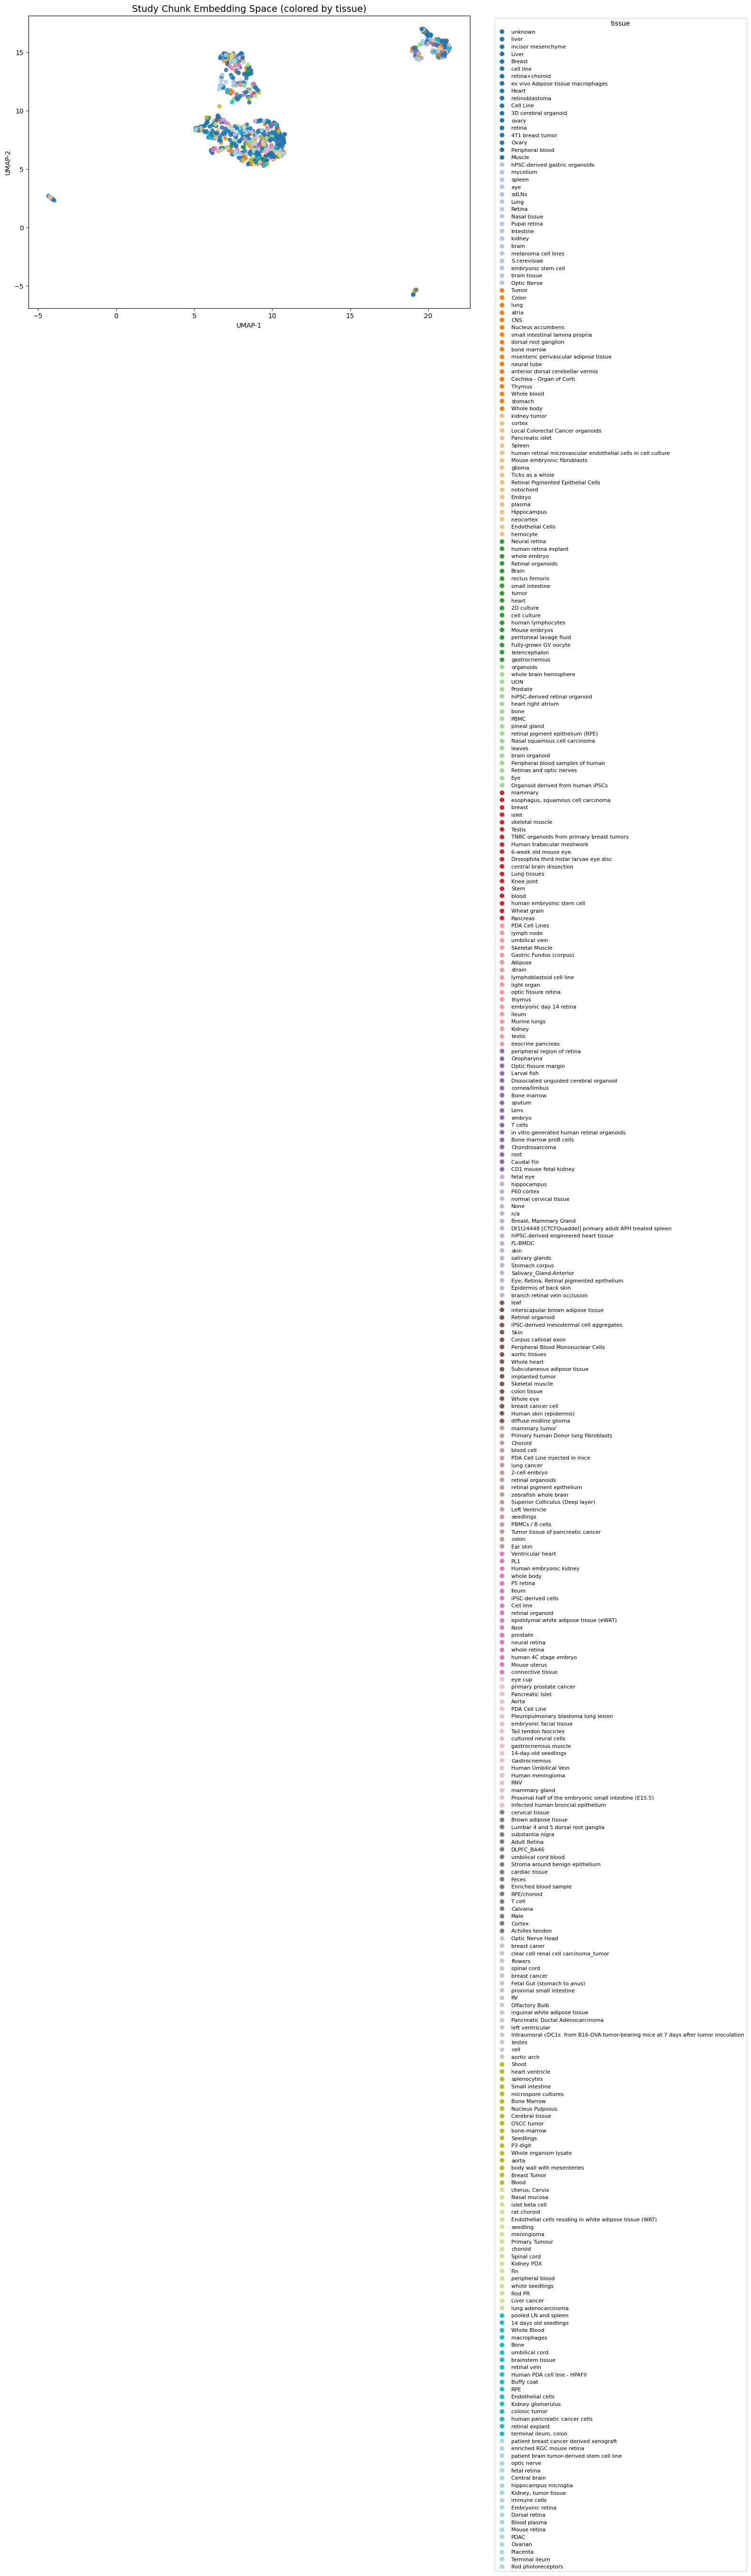

Plot complete: Study Chunk Embedding Space (colored by tissue)

Fetching vectors from: geo_study_collection
Vectors fetched       : (1000, 768)
Unique labels         : 75
Labels found          : ['Ambystoma mexicanum', 'Aquarana catesbeiana', 'Arabidopsis thaliana', 'Arabidopsis thaliana;Brassica napus', 'Aspergillus flavus', 'Axonopus compressus', 'Bacillus massilioanorexius;Bacillus toyonensis;Escherichia coli;Pseudomonas aeruginosa', 'Caenorhabditis elegans', 'Candida albicans', 'Canis lupus familiaris', 'Citrullus lanatus', 'Coccidioides posadasii', 'Coccidioides posadasii;unidentified', 'Danio rerio', 'Danio rerio;Mus musculus', 'Drosophila melanogaster', 'Escherichia coli', 'Escherichia coli K-12', 'Escherichia phage T4;Homo sapiens', 'Euprymna scolopes', 'Fusarium graminearum;Schizosaccharomyces japonicus yFS275', 'Gallus gallus', 'Gallus gallus;Homo sapiens', 'Gallus gallus;Petromyzon marinus', 'Hevea brasiliensis', 'Histoplasma ohiense', 'Homo sapiens', 'Homo sapiens;Macaca fa

d:\GEO-LLM\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Maruf\AppData\Local\Temp\ipykernel_12112\1372194493.py:164: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_codes))


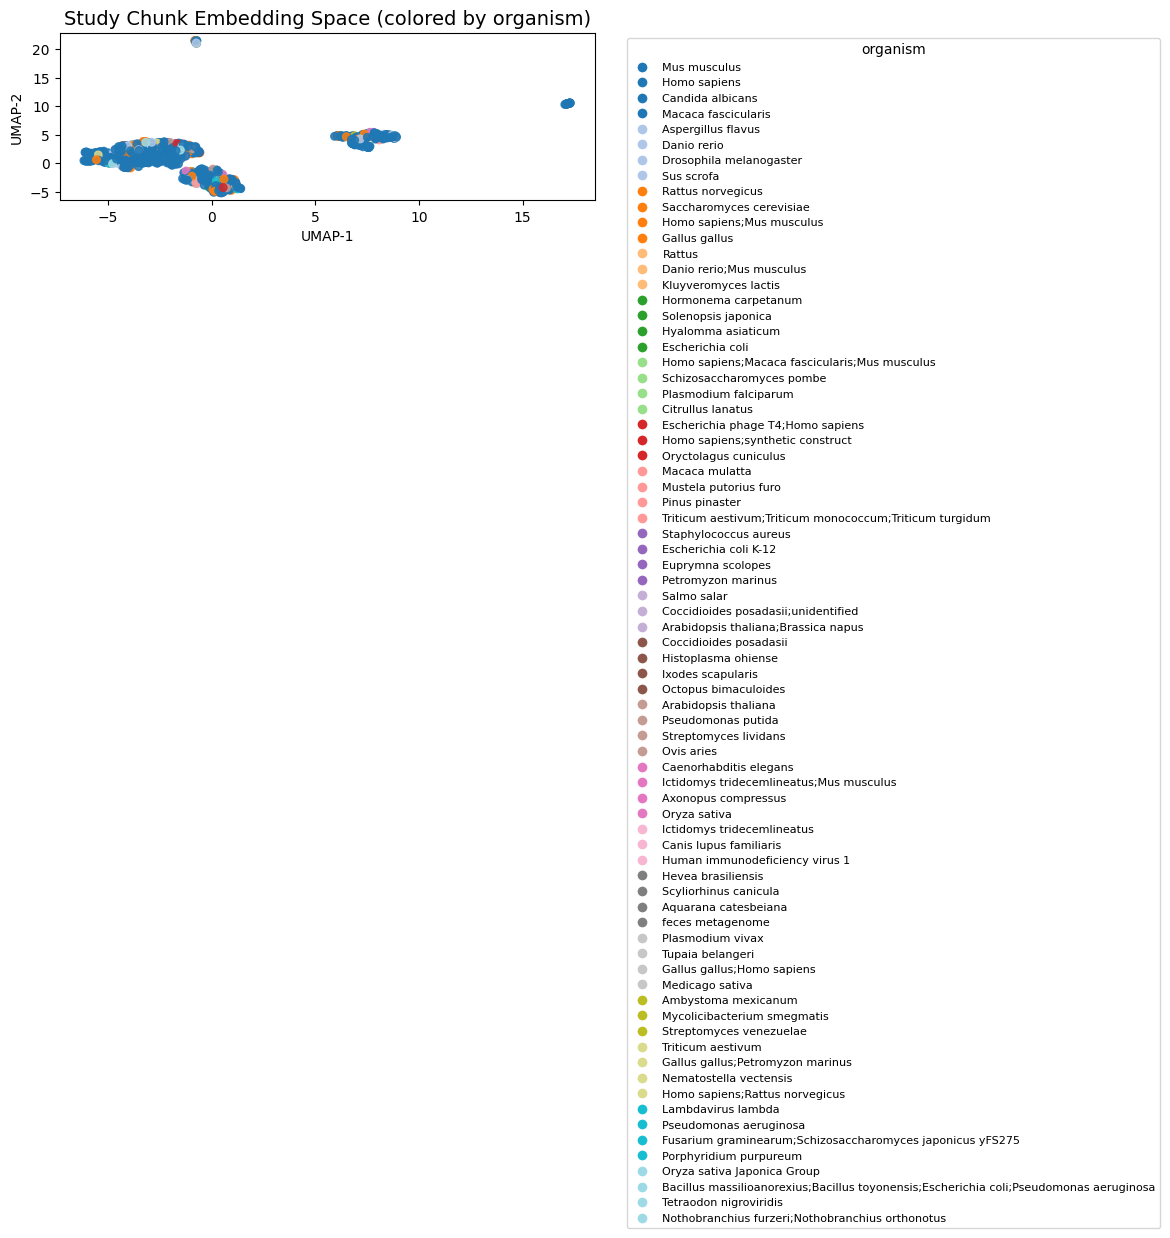

Plot complete: Study Chunk Embedding Space (colored by organism)

Fetching vectors from: geo_sample_collection
Vectors fetched       : (772, 768)
Unique labels         : 176
Labels found          : ['3D cerebral organoid', '6-week old mouse eye', 'Adipose Tissue', 'Adipose tissue', 'Aorta', 'Arm', 'Blood', 'Blood plasma', 'Bone', 'Bone Marrow', 'Brain', 'Breast Adenocarcinoma', 'Breast invasive carcinoma', 'CSF', 'Colon', 'Cortex', 'Dorsal retina', 'E13.5 mouse embryos', 'ES cell-derived gonadal somatic cells', 'Epidermis', 'Eye', 'Eyes', 'Femoral neck', 'Forebrain', 'Gastric', 'Gastric Antrum', 'Gastric Body (corpus)', 'Heart', 'Hepatocellular Carcinoma (HCC)', 'Hippocampus', 'Hippocampus on autopsy', 'Human Lung', 'Human Umbilical Vein Endothelial Cells', 'Human embryonic kidney', 'Ipsi', 'Kidney', 'Leaf', 'Liver', 'Lung', 'Lung BALF', 'Lung; Pleural effusion', 'Male', 'Nasal squamous cell carcinoma', 'Neuroretina', 'Normal mammary tissues', 'Optic Lobes', 'Outer photoreceptor cells'

d:\GEO-LLM\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Maruf\AppData\Local\Temp\ipykernel_12112\1372194493.py:164: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_codes))
C:\Users\Maruf\AppData\Local\Temp\ipykernel_12112\1372194493.py:188: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


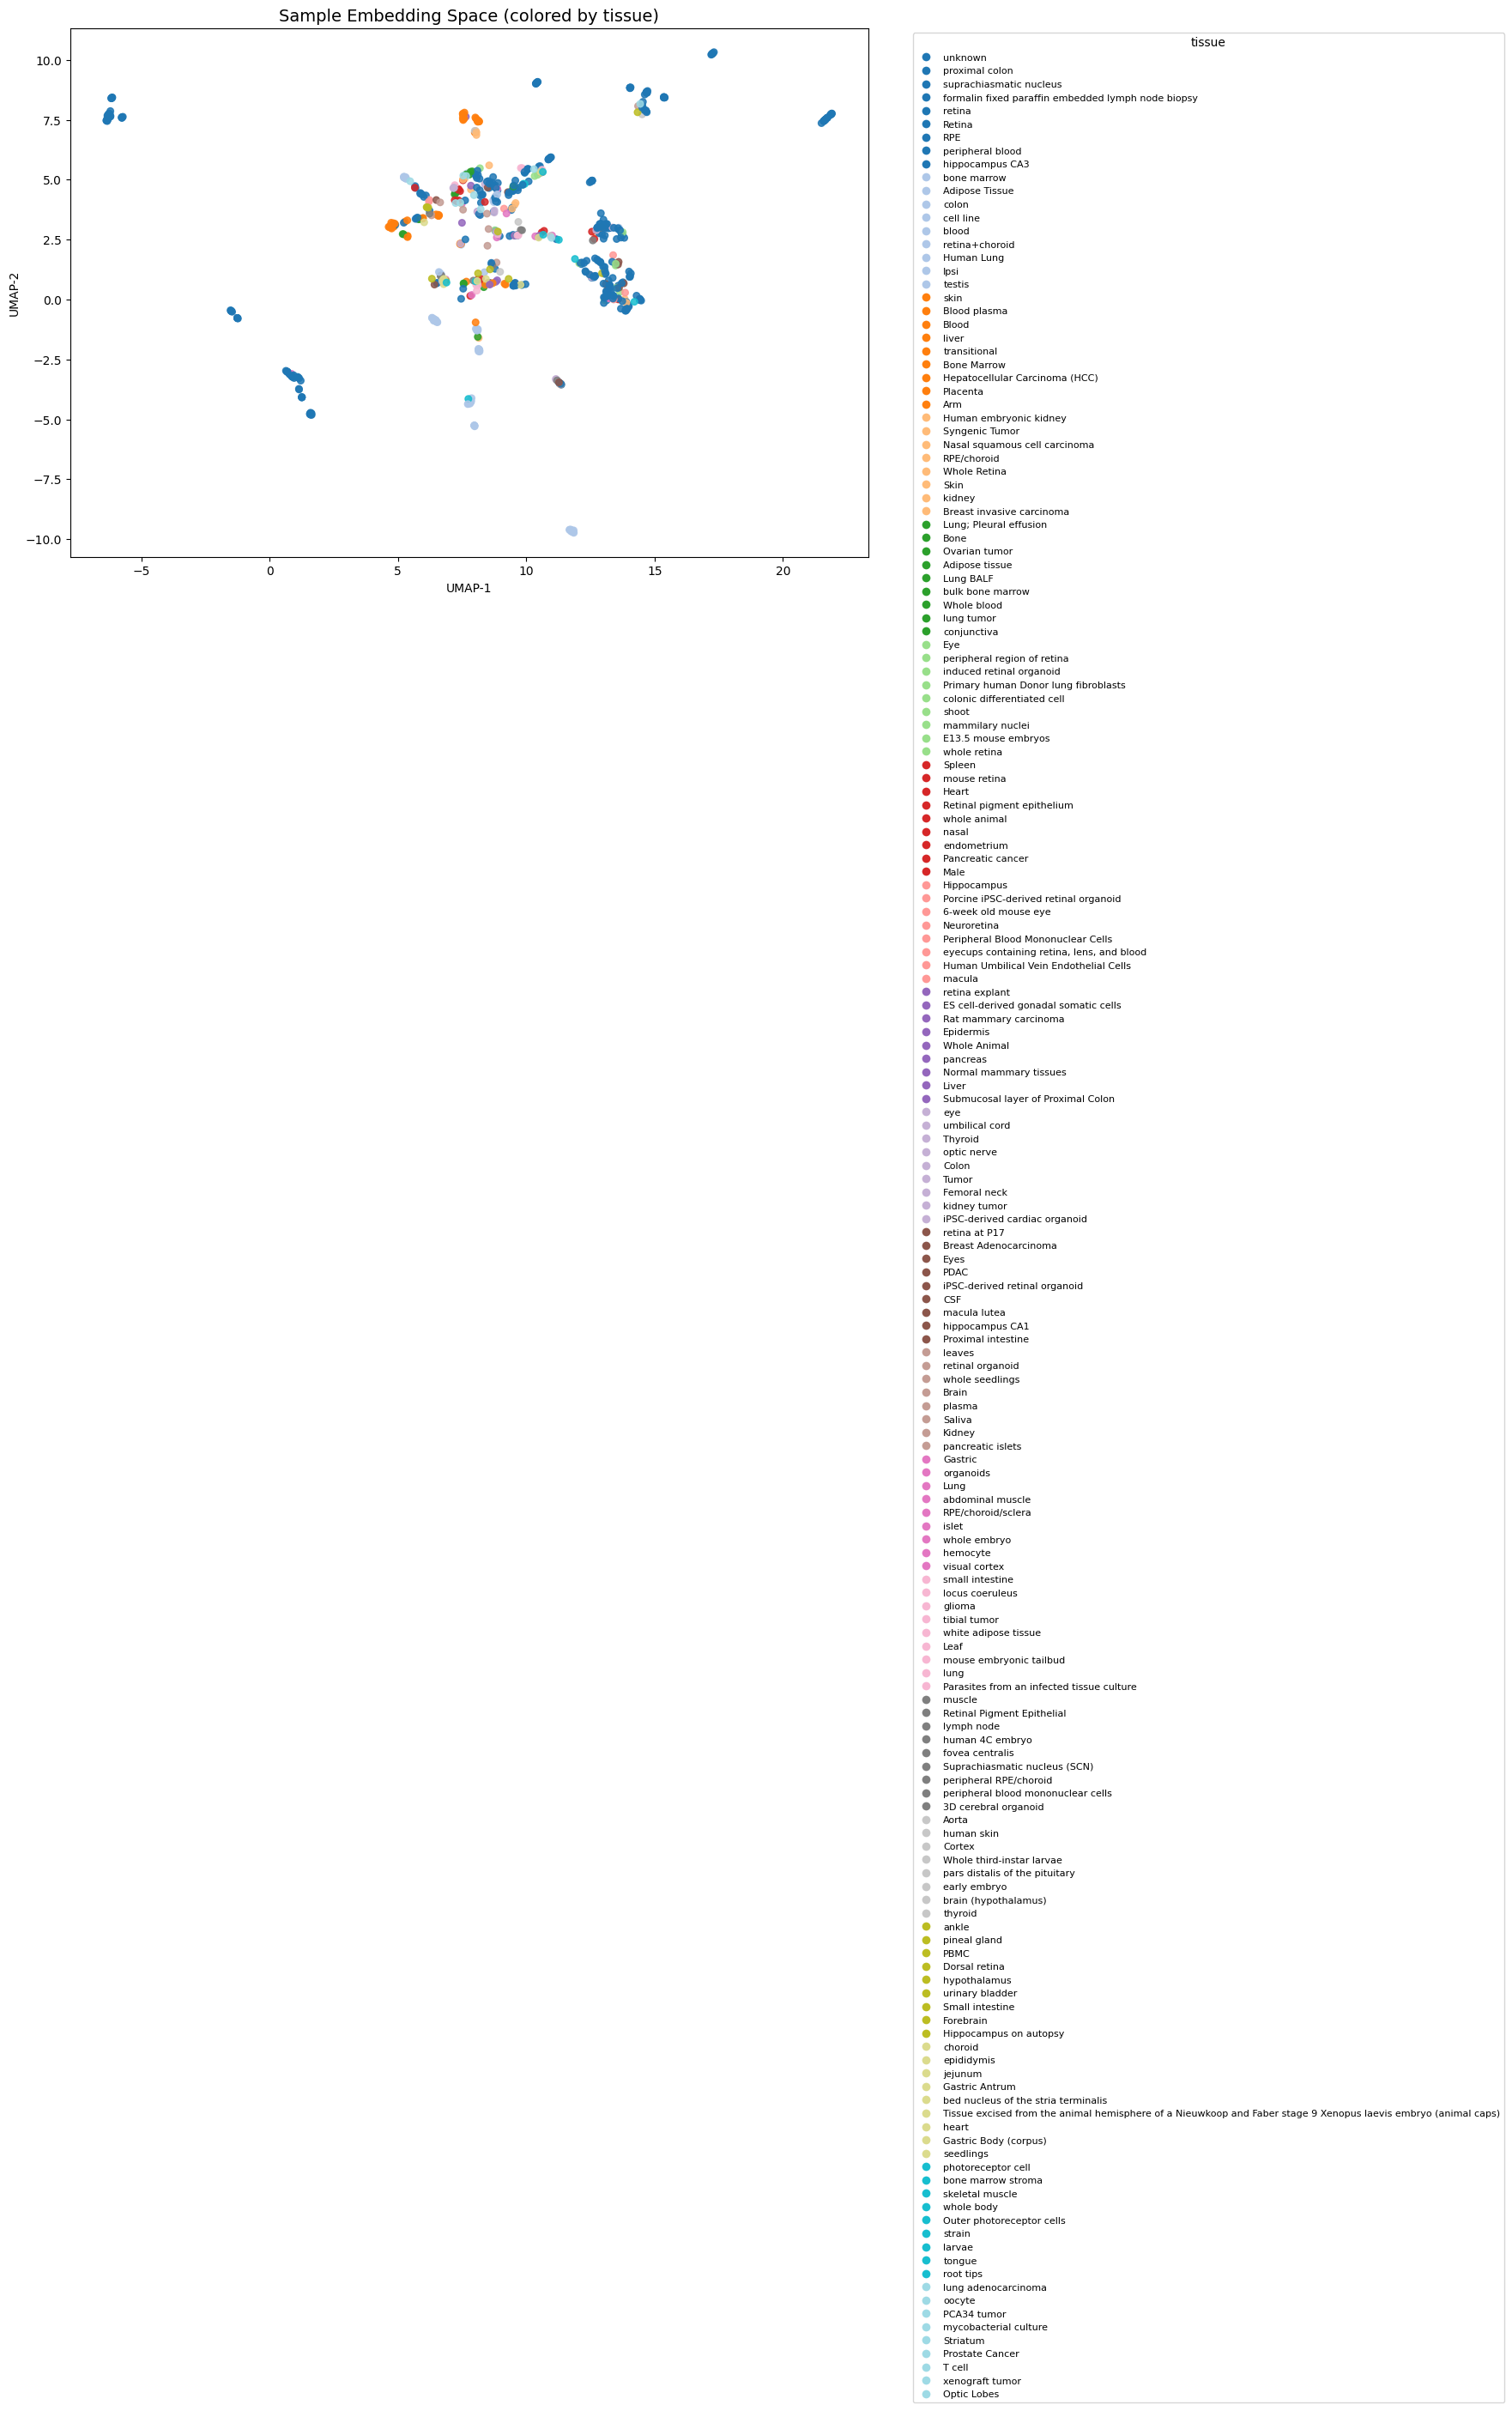

Plot complete: Sample Embedding Space (colored by tissue)

Fetching vectors from: geo_sample_collection
Vectors fetched       : (772, 768)
Unique labels         : 9
Labels found          : ['Control_Dermis_Inflammation', 'Cutaneous lichen planus', 'Diffuse Large B cell Lymphoma', 'Late_HS_Dermis_Deep_Inflammation', 'Late_HS_Dermis_Eccrine gland', 'Lung cancer', 'control', 'idiopathic pulmonary fibrosis', 'unknown']

Running PCA to 50 components...
Running UMAP...


d:\GEO-LLM\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Maruf\AppData\Local\Temp\ipykernel_12112\1372194493.py:164: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_codes))


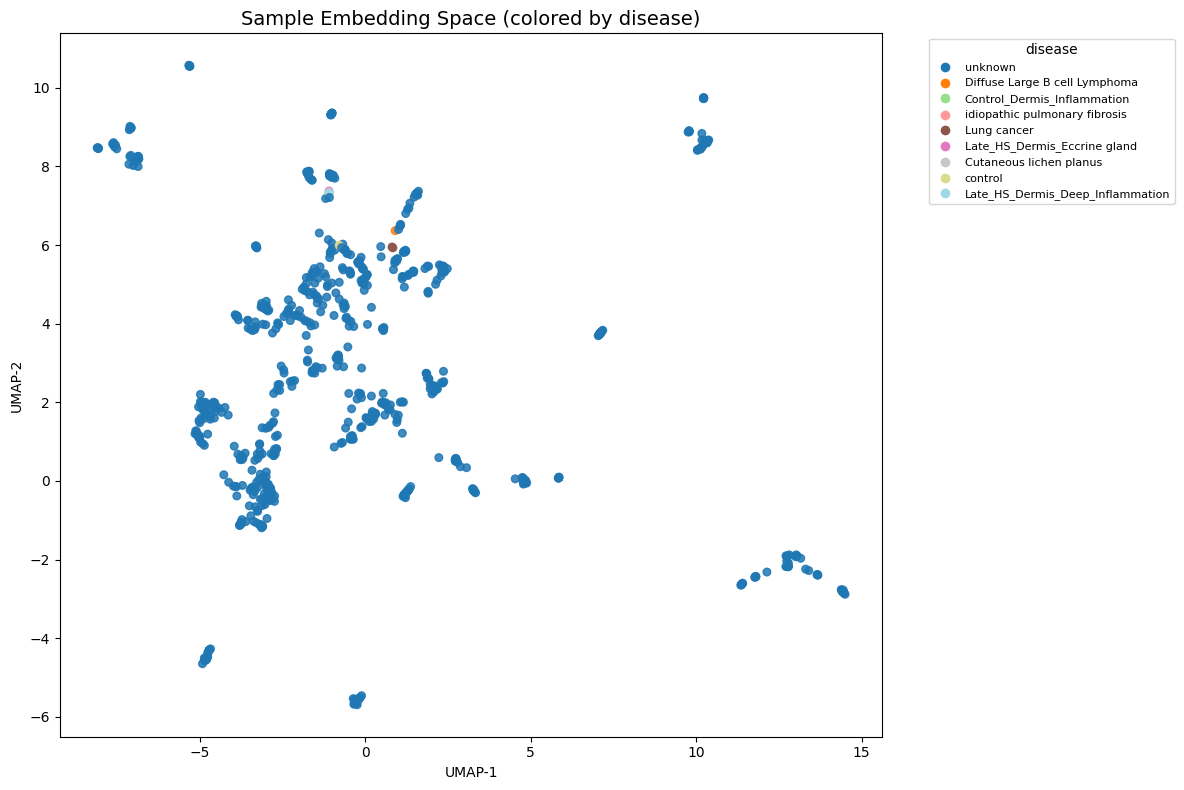

Plot complete: Sample Embedding Space (colored by disease)



In [16]:
# ============================================================
# Cell 13 — Embedding Space Visualization (UMAP)
# ============================================================
# Fetches dense vectors from Qdrant and projects them into
# 2D space using PCA + UMAP for visual inspection.
#
# Useful for verifying:
#   - Are similar studies/samples clustering together?
#   - Is there separation by organism, tissue, assay type?
#   - Are embeddings spread well or collapsed into one blob?
#
# Note on named vectors:
#   Collections now use named vectors {"dense": [...], "sparse": ...}
#   So we must extract p.vector["dense"] not p.vector directly.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
from sklearn.decomposition import PCA


def fetch_dense_vectors_and_labels(
    collection_name : str,
    label_field     : str = None,
    limit           : int = 1000
):
    """
    Fetch dense vectors and metadata labels from a collection.

    Args:
        collection_name : Which Qdrant collection to fetch from.
        label_field     : Payload field to use as color label.
                          If None, tries tissue → assay_type → organism.
        limit           : Maximum number of points to fetch.

    Returns:
        vectors : np.array of shape (n_points, 768)
        labels  : np.array of string labels for coloring
    """

    points, _ = qdrant_client.scroll(
        collection_name = collection_name,
        limit           = limit,
        with_payload    = True,
        with_vectors    = True
    )

    vectors = []
    labels  = []

    for point in points:

        # Extract dense vector from named vector dict
        # Old code used p.vector directly — now it is a dict
        point_vectors = point.vector

        if isinstance(point_vectors, dict):
            dense_vector = point_vectors.get("dense", [])
        else:
            # Fallback for flat vector (should not happen)
            dense_vector = point_vectors

        if not dense_vector:
            continue

        vectors.append(dense_vector)

        # Choose label field for coloring
        payload = point.payload

        if label_field:
            label = payload.get(label_field) or "unknown"
        else:
            # Auto-select first non-empty field
            label = (
                payload.get("tissue")      or
                payload.get("assay_type")  or
                payload.get("organism")    or
                "unknown"
            )

        labels.append(str(label))

    return np.array(vectors), np.array(labels)


def plot_umap_projection(
    collection_name : str,
    title           : str  = "UMAP Projection",
    label_field     : str  = None,
    limit           : int  = 1000,
    n_neighbors     : int  = 15,
    min_dist        : float = 0.1
):
    """
    Fetch embeddings from Qdrant and plot 2D UMAP projection.

    Process:
        1. Fetch dense vectors + labels from Qdrant
        2. Reduce to 50 dims with PCA (UMAP stability)
        3. Project to 2D with UMAP
        4. Plot scatter colored by label field

    Args:
        collection_name : Qdrant collection to visualize.
        title           : Plot title.
        label_field     : Payload field to use for coloring.
                          None = auto-select tissue/assay/organism.
        limit           : Max points to fetch.
        n_neighbors     : UMAP neighborhood size.
        min_dist        : UMAP minimum distance between points.
    """

    print(f"Fetching vectors from: {collection_name}")

    vectors, labels = fetch_dense_vectors_and_labels(
        collection_name = collection_name,
        label_field     = label_field,
        limit           = limit
    )

    print(f"Vectors fetched       : {vectors.shape}")
    print(f"Unique labels         : {len(set(labels))}")
    print(f"Labels found          : {sorted(set(labels))}\n")

    # Step 1 — PCA to reduce dimensions before UMAP
    # PCA first improves UMAP stability and speed
    n_pca_components = min(50, vectors.shape[0] - 1, vectors.shape[1])

    print(f"Running PCA to {n_pca_components} components...")
    pca_reducer  = PCA(n_components=n_pca_components)
    vectors_pca  = pca_reducer.fit_transform(vectors)

    # Step 2 — UMAP projection to 2D
    print(f"Running UMAP...")
    umap_reducer = umap.UMAP(
        n_neighbors = n_neighbors,
        min_dist    = min_dist,
        metric      = "cosine",
        random_state = 42
    )
    vectors_2d = umap_reducer.fit_transform(vectors_pca)

    # Step 3 — Plot
    label_codes, label_names = pd.factorize(labels)

    plt.figure(figsize=(12, 8))

    scatter = plt.scatter(
        vectors_2d[:, 0],
        vectors_2d[:, 1],
        c     = label_codes,
        cmap  = "tab20",
        s     = 30,
        alpha = 0.85
    )

    # Add legend with actual label names
    unique_codes  = np.unique(label_codes)
    legend_handles = []

    cmap = plt.cm.get_cmap("tab20", len(unique_codes))

    for code in unique_codes:
        handle = plt.Line2D(
            [0], [0],
            marker     = "o",
            color      = "w",
            markerfacecolor = cmap(code),
            markersize = 8,
            label      = label_names[code]
        )
        legend_handles.append(handle)

    plt.legend(
        handles   = legend_handles,
        bbox_to_anchor = (1.05, 1),
        loc       = "upper left",
        fontsize  = 8,
        title     = label_field or "tissue / assay / organism"
    )

    plt.title(title, fontsize=14)
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.tight_layout()
    plt.show()

    print(f"Plot complete: {title}\n")


# ============================================================
# Run Visualizations
# ============================================================

# Study collection — color by tissue
plot_umap_projection(
    collection_name = STUDY_COLLECTION,
    title           = "Study Chunk Embedding Space (colored by tissue)",
    label_field     = "tissue"
)

# Study collection — color by organism
plot_umap_projection(
    collection_name = STUDY_COLLECTION,
    title           = "Study Chunk Embedding Space (colored by organism)",
    label_field     = "organism"
)

# Sample collection — color by tissue
plot_umap_projection(
    collection_name = SAMPLE_COLLECTION,
    title           = "Sample Embedding Space (colored by tissue)",
    label_field     = "tissue",
    limit           = 772
)

# Sample collection — color by disease
plot_umap_projection(
    collection_name = SAMPLE_COLLECTION,
    title           = "Sample Embedding Space (colored by disease)",
    label_field     = "disease",
    limit           = 772
)

## Manual Retrieval Test

In [17]:
# ============================================================
# Cell 14 — Manual Retrieval Test (Dense + Filter)
# ============================================================
# Tests Qdrant retrieval directly using named dense vectors.
# Verifies that:
#   - Dense vector search works with new named vector schema
#   - Payload filter (organism) correctly restricts results
#   - Sample retrieval by top GSE IDs works correctly
#
# This is a manual sanity check before the full RAG pipeline.
# ============================================================

from qdrant_client.models import Filter, FieldCondition, MatchValue, MatchAny


# ── Test Query ─────────────────────────────────────────────
test_query = "single cell RNA sequencing human blood disease"

print(f"Query: {test_query}\n")

# ── Generate dense query vector ────────────────────────────
query_dense_vector = dense_embedder.encode(
    test_query,
    normalize_embeddings = True
).tolist()


# ============================================================
# Study Retrieval — Dense Search with Organism Filter
# ============================================================

print("=" * 55)
print("Study Retrieval (dense + organism filter)")
print("=" * 55)

study_results = qdrant_client.query_points(
    collection_name = STUDY_COLLECTION,
    query           = query_dense_vector,
    using           = "dense",              # named vector key
    query_filter    = Filter(
        must = [
            FieldCondition(
                key   = "organism",
                match = MatchValue(value="Homo sapiens")
            )
        ]
    ),
    limit           = 5,
    with_payload    = True
).points

top_gse_ids = []

for result in study_results:
    payload = result.payload
    gse_id  = payload.get("gse_id", "")

    if gse_id and gse_id not in top_gse_ids:
        top_gse_ids.append(gse_id)

    print(f"Score    : {round(result.score, 4)}")
    print(f"GSE ID   : {gse_id}")
    print(f"Field    : {payload.get('field')}")
    print(f"Parent   : {payload.get('parent_id')}")
    print(f"Child    : {payload.get('child_index')}")
    print(f"Organism : {payload.get('organism')}")
    print(f"Tissue   : {payload.get('tissue')}")
    print(f"Assay    : {payload.get('assay_type')}")
    print(f"Preview  : {payload.get('text', '')[:100]}...")
    print("-" * 55)

print(f"\nTop GSE IDs: {top_gse_ids}\n")


# ============================================================
# Sample Retrieval — Restricted to Top GSE IDs
# ============================================================

print("=" * 55)
print("Sample Retrieval (restricted to top GSEs)")
print("=" * 55)

if not top_gse_ids:
    print("No GSE IDs retrieved — skipping sample search.")
else:
    sample_results = qdrant_client.query_points(
        collection_name = SAMPLE_COLLECTION,
        query           = query_dense_vector,
        using           = "dense",              # named vector key
        query_filter    = Filter(
            must = [
                FieldCondition(
                    key   = "gse_id",
                    match = MatchAny(any=top_gse_ids)
                )
            ]
        ),
        limit           = 5,
        with_payload    = True
    ).points

    for result in sample_results:
        payload = result.payload

        print(f"Score     : {round(result.score, 4)}")
        print(f"GSE       : {payload.get('gse_id')}")
        print(f"GSM       : {payload.get('gsm_id')}")
        print(f"Organism  : {payload.get('organism')}")
        print(f"Tissue    : {payload.get('tissue')}")
        print(f"Disease   : {payload.get('disease')}")
        print(f"Genotype  : {payload.get('genotype')}")
        print(f"Cell Line : {payload.get('cell_line')}")
        print(f"Cell Type : {payload.get('cell_type')}")
        print(f"SRA URL   : {payload.get('sra_url')}")
        print("-" * 55)

Query: single cell RNA sequencing human blood disease

Study Retrieval (dense + organism filter)
Score    : 0.7351
GSE ID   : GSE294652
Field    : title
Parent   : GSE294652_title
Child    : 0
Organism : Homo sapiens
Tissue   : human CAR-T cells
Assay    : Expression profiling by high throughput sequencing
Preview  : Single-cell RNA sequencing data from human CAR-T cell samples...
-------------------------------------------------------
Score    : 0.6801
GSE ID   : GSE273146
Field    : overall_design
Parent   : GSE273146_overall_design
Child    : 0
Organism : Homo sapiens
Tissue   : liver
Assay    : Expression profiling by high throughput sequencing
Preview  : single-cell RNA sequencing 3' (scRNA-seq)...
-------------------------------------------------------
Score    : 0.6778
GSE ID   : GSE298634
Field    : overall_design
Parent   : GSE298634_overall_design
Child    : 0
Organism : Homo sapiens
Tissue   : 
Assay    : Expression profiling by high throughput sequencing
Preview  : mRNA-seq

## RESOLVER

In [18]:
# ============================================================
# Cell 15 — Organism Resolver (NCBI Taxonomy Only)
# ============================================================
# Resolves organism names from user queries into canonical
# scientific names using NCBI Taxonomy database.
#
# Why organism only:
#   - Users type organisms imprecisely ("mouse", "human")
#   - GEO metadata stores scientific names ("Mus musculus")
#   - Exact payload match needs canonical scientific name
#   - NCBI Taxonomy is 100% accurate for this purpose
#   - Other fields (tissue, disease) are handled by semantic
#     retrieval — no ontology resolution needed for them
#
# Design decisions:
#   - NCBI Taxonomy only — no EBI OLS
#   - SQLite cache — no re-fetching on notebook restart
#   - Retry + exponential backoff — handles network hiccups
#   - Uses "organism" field from LLM parsed filters directly
#   - esummary endpoint — reliable JSON (efetch returns XML)
# ============================================================

import sqlite3
import requests
import json
import time
from datetime import datetime
from typing import Optional


# ============================================================
# SQLite Cache
# ============================================================

class OrganismCache:
    """
    SQLite-backed cache for resolved organism names.

    After the first NCBI lookup of any organism term,
    the canonical scientific name is stored locally.
    Every future lookup is an instant local read.

    Cache persists across notebook restarts — terms
    resolved in a previous session are never re-fetched.
    """

    def __init__(self, database_path: str):
        """
        Initialize cache. Creates database file and table
        if they do not already exist.

        Args:
            database_path: Path to SQLite .db file.
        """

        self.database_path = database_path
        self._create_table_if_not_exists()


    def _create_table_if_not_exists(self):
        """Create cache table on first run only."""

        with sqlite3.connect(self.database_path) as conn:
            conn.execute("""
                CREATE TABLE IF NOT EXISTS organism_cache (
                    term          TEXT PRIMARY KEY,
                    resolved_json TEXT NOT NULL,
                    created_at    TEXT NOT NULL
                )
            """)
            conn.commit()


    def get(self, term: str) -> Optional[dict]:
        """
        Look up a term in the local cache.

        Args:
            term: Raw organism term (lowercased before lookup).

        Returns:
            Resolved concept dict if cached, None if cache miss.
        """

        normalized = term.strip().lower()

        with sqlite3.connect(self.database_path) as conn:
            cursor = conn.execute(
                "SELECT resolved_json FROM organism_cache WHERE term = ?",
                (normalized,)
            )
            row = cursor.fetchone()

        return json.loads(row[0]) if row else None


    def set(self, term: str, resolved: dict):
        """
        Save a resolved organism to the local cache.

        Args:
            term    : Raw term string (will be lowercased).
            resolved: Resolved concept dict to store.
        """

        normalized = term.strip().lower()
        timestamp  = datetime.now().isoformat()

        with sqlite3.connect(self.database_path) as conn:
            conn.execute("""
                INSERT OR REPLACE INTO organism_cache
                    (term, resolved_json, created_at)
                VALUES (?, ?, ?)
            """,
            (normalized, json.dumps(resolved), timestamp))
            conn.commit()


    def get_all_cached_terms(self) -> list[str]:
        """Return list of all terms currently in the cache."""

        with sqlite3.connect(self.database_path) as conn:
            cursor = conn.execute(
                "SELECT term FROM organism_cache ORDER BY term"
            )
            return [row[0] for row in cursor.fetchall()]


    def get_size(self) -> int:
        """Return number of terms currently cached."""

        with sqlite3.connect(self.database_path) as conn:
            cursor = conn.execute(
                "SELECT COUNT(*) FROM organism_cache"
            )
            return cursor.fetchone()[0]


# ============================================================
# NCBI Taxonomy Resolver
# ============================================================

class OrganismResolver:
    """
    Resolves organism names to canonical scientific names
    using NCBI Taxonomy via esummary (JSON endpoint).

    Handles all organism name formats:
        "mouse"              → Mus musculus
        "human"              → Homo sapiens
        "Mus musculus"       → Mus musculus  (already canonical)
        "norway rat"         → Rattus norvegicus
        "fruit fly"          → Drosophila melanogaster
        "african clawed frog"→ Xenopus laevis

    Retry logic:
        Each NCBI API call is retried up to MAX_RETRIES times
        with exponential backoff. This prevents a temporary
        network timeout from being cached as "unresolved."
    """

    # NCBI Entrez API endpoints
    NCBI_ESEARCH_URL  = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"
    NCBI_ESUMMARY_URL = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi"

    # Retry configuration
    MAX_RETRIES        = 3      # number of retry attempts
    RETRY_BASE_DELAY   = 1.0   # seconds — doubles each retry (1s, 2s, 4s)
    REQUEST_TIMEOUT    = 8      # seconds per request


    def __init__(self, cache_database_path: str):
        """
        Initialize resolver with a persistent SQLite cache.

        Args:
            cache_database_path: Path to SQLite cache file.
                                 Reused across notebook restarts.
        """

        self.cache = OrganismCache(cache_database_path)

        print(f"OrganismResolver initialized.")
        print(f"Cache path   : {cache_database_path}")
        print(f"Cached terms : {self.cache.get_size()}")

        if self.cache.get_size() > 0:
            print(f"Known terms  : {self.cache.get_all_cached_terms()}")


    def resolve_organism(self, organism_term: str) -> dict:
        """
        Resolve a single organism term to its canonical name.

        Resolution flow:
            1. Check SQLite cache (instant local read)
            2. Call NCBI Taxonomy esearch → get taxonomy ID
            3. Call NCBI Taxonomy esummary → get scientific name
            4. Save to cache and return
            5. If all retries fail → return fallback (term as-is)

        Args:
            organism_term: Raw organism name from LLM filter.
                           e.g. "mouse", "human", "Mus musculus"

        Returns:
            Dict with canonical name and metadata:
            {
                "canonical_name" : "Mus musculus",
                "taxonomy_id"    : "10090",
                "common_name"    : "house mouse",
                "ontology_id"    : "NCBITaxon:10090",
                "source"         : "ncbi_taxonomy"
            }
            On failure:
            {
                "canonical_name" : original_term,
                "taxonomy_id"    : None,
                "common_name"    : "",
                "ontology_id"    : None,
                "source"         : "unresolved"
            }
        """

        if not organism_term or not organism_term.strip():
            return self._build_fallback(organism_term or "")

        print(f"  Resolving organism: '{organism_term}'")

        # ── Step 1: Check cache first ──────────────────────
        cached = self.cache.get(organism_term)

        if cached:
            source = cached.get("source", "cache")
            name   = cached.get("canonical_name", organism_term)
            print(f"    → [{source}] {name} (cached)")
            return cached

        # ── Step 2: Query NCBI Taxonomy ────────────────────
        taxonomy_id = self._search_ncbi_taxonomy(organism_term)

        if not taxonomy_id:
            print(f"    → [unresolved] '{organism_term}' not found in NCBI Taxonomy")
            fallback = self._build_fallback(organism_term)
            self.cache.set(organism_term, fallback)
            return fallback

        # ── Step 3: Fetch full record via esummary ─────────
        resolved = self._fetch_ncbi_summary(taxonomy_id, organism_term)

        if not resolved:
            print(f"    → [unresolved] could not fetch summary for ID {taxonomy_id}")
            fallback = self._build_fallback(organism_term)
            self.cache.set(organism_term, fallback)
            return fallback

        # ── Step 4: Cache and return ───────────────────────
        print(f"    → [ncbi] {resolved['canonical_name']} (NCBITaxon:{taxonomy_id})")
        self.cache.set(organism_term, resolved)
        return resolved


    def resolve_from_filters(self, filters: dict) -> Optional[dict]:
        """
        Extract and resolve the organism field from LLM filters.

        The LLM query understanding step (Cell 16) returns a
        filters dict. This method extracts the "organism" field
        and resolves it. Returns None if no organism in filters.

        Args:
            filters: Dict of filters from LLM query understanding.
                     e.g. {"organism": "mouse", "tissue": "blood"}

        Returns:
            Resolved organism dict or None if organism not in filters.
        """

        organism_term = filters.get("organism", "")

        if not organism_term:
            return None

        return self.resolve_organism(organism_term)


    def _search_ncbi_taxonomy(self, term: str) -> Optional[str]:
        """
        Search NCBI Taxonomy for a term and return taxonomy ID.

        Uses esearch endpoint with retry + exponential backoff.

        Args:
            term: Organism name to search for.

        Returns:
            Taxonomy ID string or None if not found.
        """

        for attempt in range(1, self.MAX_RETRIES + 1):

            try:
                response = requests.get(
                    self.NCBI_ESEARCH_URL,
                    params = {
                        "db"      : "taxonomy",
                        "term"    : term,
                        "retmode" : "json",
                        "retmax"  : 1
                    },
                    timeout = self.REQUEST_TIMEOUT
                )

                if response.status_code != 200:
                    raise ValueError(
                        f"HTTP {response.status_code} from NCBI esearch"
                    )

                data    = response.json()
                id_list = data.get("esearchresult", {}).get("idlist", [])

                if id_list:
                    return id_list[0]

                # Term not found in taxonomy — no point retrying
                return None

            except Exception as error:

                wait_seconds = self.RETRY_BASE_DELAY * (2 ** (attempt - 1))

                print(
                    f"    [ncbi esearch attempt {attempt}/{self.MAX_RETRIES}]"
                    f" {error} — retrying in {wait_seconds:.1f}s"
                )

                if attempt < self.MAX_RETRIES:
                    time.sleep(wait_seconds)

        return None


    def _fetch_ncbi_summary(
        self,
        taxonomy_id   : str,
        original_term : str
    ) -> Optional[dict]:
        """
        Fetch canonical name and metadata from NCBI esummary.

        Uses esummary (not efetch) because esummary reliably
        returns JSON. efetch returns XML which caused errors.

        esummary response structure:
        {
            "result": {
                "uids": ["10090"],
                "10090": {
                    "scientificname": "Mus musculus",
                    "commonname"    : "house mouse",
                    ...
                }
            }
        }

        Args:
            taxonomy_id  : NCBI Taxonomy ID to fetch.
            original_term: Original search term (for fallback).

        Returns:
            Resolved concept dict or None if fetch fails.
        """

        for attempt in range(1, self.MAX_RETRIES + 1):

            try:
                response = requests.get(
                    self.NCBI_ESUMMARY_URL,
                    params = {
                        "db"      : "taxonomy",
                        "id"      : taxonomy_id,
                        "retmode" : "json"
                    },
                    timeout = self.REQUEST_TIMEOUT
                )

                if response.status_code != 200:
                    raise ValueError(
                        f"HTTP {response.status_code} from NCBI esummary"
                    )

                data          = response.json()
                result_block  = data.get("result", {})
                taxon_info    = result_block.get(taxonomy_id, {})

                # taxon_info is a dict with scientificname etc.
                # If it is an int or unexpected type, handle gracefully
                if not isinstance(taxon_info, dict):
                    return None

                canonical_name = taxon_info.get("scientificname", "")

                if not canonical_name:
                    return None

                common_name = taxon_info.get("commonname", "")

                return {
                    "canonical_name" : canonical_name,
                    "taxonomy_id"    : taxonomy_id,
                    "common_name"    : common_name,
                    "ontology_id"    : f"NCBITaxon:{taxonomy_id}",
                    "source"         : "ncbi_taxonomy"
                }

            except Exception as error:

                wait_seconds = self.RETRY_BASE_DELAY * (2 ** (attempt - 1))

                print(
                    f"    [ncbi esummary attempt {attempt}/{self.MAX_RETRIES}]"
                    f" {error} — retrying in {wait_seconds:.1f}s"
                )

                if attempt < self.MAX_RETRIES:
                    time.sleep(wait_seconds)

        return None


    def _build_fallback(self, term: str) -> dict:
        """
        Build a fallback result when NCBI resolution fails.

        Fallback keeps the original term as canonical_name.
        Semantic retrieval will still handle it via embedding.

        Args:
            term: Original organism term.

        Returns:
            Fallback concept dict.
        """

        return {
            "canonical_name" : term,
            "taxonomy_id"    : None,
            "common_name"    : "",
            "ontology_id"    : None,
            "source"         : "unresolved"
        }


# ============================================================
# Initialize Resolver
# ============================================================
# Cache persists across restarts — no clearing needed.
# If cache already has terms from a previous run, they
# are reused immediately without any API calls.

organism_resolver = OrganismResolver(
    cache_database_path = ONTOLOGY_CACHE_DB
)


# ============================================================
# Pre-Warm Cache With Common GEO Organism Names
# ============================================================
# Resolves common organism names before any user query.
# After this, all these organisms are served from local
# cache instantly — zero API calls in production.

common_organisms = [
    # Common names
    "human", "mouse", "rat", "zebrafish",
    "fruit fly", "worm", "yeast", "pig",
    "rabbit", "chicken", "macaque", "hamster",
    # Scientific names (already canonical but good to cache)
    "Homo sapiens", "Mus musculus", "Rattus norvegicus",
    "Danio rerio", "Drosophila melanogaster",
    "Caenorhabditis elegans", "Saccharomyces cerevisiae",
    "Sus scrofa", "Gallus gallus", "Oryctolagus cuniculus",
    "Macaca mulatta", "Xenopus laevis",
    # Variants users commonly type
    "homo sapiens", "mus musculus", "rattus norvegicus",
]

print("\n--- Pre-warming organism cache ---")

for organism in common_organisms:
    organism_resolver.resolve_organism(organism)

print(f"\nCache size after pre-warming: {organism_resolver.cache.get_size()} terms")
print(f"Cached terms: {organism_resolver.cache.get_all_cached_terms()}")


# ============================================================
# Verification Test
# ============================================================

print("\n--- Verification Test ---\n")

test_organisms = [
    "human",
    "mouse",
    "Homo sapiens",
    "Mus musculus",
    "rat",
    "zebrafish",
    "fruit fly",
]

print("Resolution results:")
print("-" * 55)

for term in test_organisms:
    result = organism_resolver.resolve_organism(term)
    print(f"Input          : {term}")
    print(f"Canonical name : {result['canonical_name']}")
    print(f"Taxonomy ID    : {result['taxonomy_id']}")
    print(f"Common name    : {result['common_name']}")
    print(f"Ontology ID    : {result['ontology_id']}")
    print(f"Source         : {result['source']}")
    print("-" * 55)

OrganismResolver initialized.
Cache path   : cache\ontology_cache.db
Cached terms : 24
Known terms  : ['caenorhabditis elegans', 'chicken', 'danio rerio', 'drosophila melanogaster', 'fruit fly', 'gallus gallus', 'hamster', 'homo sapiens', 'human', 'macaca mulatta', 'macaque', 'mouse', 'mus musculus', 'oryctolagus cuniculus', 'pig', 'rabbit', 'rat', 'rattus norvegicus', 'saccharomyces cerevisiae', 'sus scrofa', 'worm', 'xenopus laevis', 'yeast', 'zebrafish']

--- Pre-warming organism cache ---
  Resolving organism: 'human'
    → [ncbi_taxonomy] Homo sapiens (cached)
  Resolving organism: 'mouse'
    → [ncbi_taxonomy] Mus musculus (cached)
  Resolving organism: 'rat'
    → [ncbi_taxonomy] Rattus norvegicus (cached)
  Resolving organism: 'zebrafish'
    → [ncbi_taxonomy] Danio rerio (cached)
  Resolving organism: 'fruit fly'
    → [ncbi_taxonomy] Drosophila gunungcola (cached)
  Resolving organism: 'worm'
    → [unresolved] worm (cached)
  Resolving organism: 'yeast'
    → [unresolved] ye

## RETRIEVAL PHASE

In [19]:
# ============================================================
# Cell 16 — Merged LLM Query Understanding
# ============================================================
# Single LLM call that extracts everything needed from the
# user query in one shot.
# New approach:
#   - One LLM call returns everything
#   - No vocabulary matching — ontology resolution handles it
#   - Simpler confidence based on filter count only
#   - Organism resolved via Cell 15 (OrganismResolver)
#
# Output structure:
#   {
#     "intent"               : "find | compare | explain | ...",
#     "operations"           : ["find", "compare"],
#     "query_type"           : "SEMANTIC | METADATA | ...",
#     "filters"              : {"organism": "mouse", "tissue": "blood"},
#     "concepts"             : ["PBMC", "single-cell", "diabetes"],
#     "semantic_focus_fields": ["title", "study_summary"],
#     "logical_operator"     : "AND | OR | NOT | null",
#     "resolved_organism"    : {...}  ← added after LLM call
#     "strategy"             : "HARD_FILTER | SOFT_BOOST | SEMANTIC_ONLY"
#     "confidence"           : 0.0 - 1.0
#   }
# ============================================================

import json
import re
from typing import Optional


# ============================================================
# Valid Values for Validation
# ============================================================

VALID_INTENTS = {
    "find", "compare", "explain", "identify",
    "list", "rank", "summarize", "describe"
}

VALID_QUERY_TYPES = {
    "SEMANTIC",
    "METADATA",
    "MULTI_CONSTRAINT",
    "STUDY_DESIGN",
    "EXPERIMENTAL_PROTOCOL",
    "DATA_PROCESSING",
    "MODALITY",
    "PLATFORM"
}

VALID_LOGICAL_OPERATORS = {"AND", "OR", "NOT", None}

# Metadata fields the LLM is allowed to extract filters for.
# These map directly to Qdrant payload field names.
ALLOWED_FILTER_FIELDS = [
    "organism",
    "tissue",
    "disease",
    "assay_type",
    "library_strategy",
    "library_source",
    "library_selection",
    "molecule",
    "instrument_model",
    "genotype",
    "cell_line",
    "cell_type",
    "status",
]

# Fields the LLM can suggest as semantic focus fields.
# These map to the "field" payload key in Qdrant study chunks.
ALLOWED_FOCUS_FIELDS = [
    "title",
    "study_summary",
    "overall_design",
    "data_processing",
    "protocol_extraction_protocol",
    "protocol_growth_protocol",
    "protocol_treatment_protocol",
]


# ============================================================
# JSON Parser — Safe Extraction from LLM Response
# ============================================================

def extract_json_from_llm_response(response_text: str) -> Optional[dict]:
    """
    Safely extract a JSON object from an LLM response string.

    LLMs sometimes wrap JSON in markdown code blocks or add
    extra text before/after. This handles all common formats.

    Args:
        response_text: Raw string response from the LLM.

    Returns:
        Parsed dict if successful, None if parsing fails.
    """

    if not response_text:
        return None

    text = response_text.strip()

    # Attempt 1 — direct JSON parse (clean response)
    try:
        return json.loads(text)
    except Exception:
        pass

    # Attempt 2 — extract from markdown code block
    # e.g. ```json\n{...}\n```
    code_block_match = re.search(
        r"```(?:json)?\s*(\{.*?\})\s*```",
        text,
        flags = re.DOTALL
    )
    if code_block_match:
        try:
            return json.loads(code_block_match.group(1))
        except Exception:
            pass

    # Attempt 3 — find first { } block in response
    brace_match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if brace_match:
        try:
            return json.loads(brace_match.group(0))
        except Exception:
            pass

    return None


# ============================================================
# LLM Prompt Builder
# ============================================================

def build_query_understanding_prompt(query: str) -> str:
    """
    Build the prompt for merged LLM query understanding.

    The prompt instructs the LLM to extract all query
    components in a single structured JSON response.

    Args:
        query: Raw user query string.

    Returns:
        Full prompt string to send to the LLM.
    """

    allowed_fields_text   = ", ".join(ALLOWED_FILTER_FIELDS)
    allowed_focus_text    = ", ".join(ALLOWED_FOCUS_FIELDS)
    valid_query_types_text = ", ".join(sorted(VALID_QUERY_TYPES))

    prompt = f"""You are a biomedical dataset query interpreter for GEO (Gene Expression Omnibus).
Your task is to analyze the user query and extract structured retrieval information.
Return ONLY a valid JSON object. No explanation, no markdown, no extra text.

JSON schema to return:
{{
    "intent": "<one of: find | compare | explain | identify | list | rank | summarize | describe>",
    "operations": ["<list of operations the user wants>"],
    "query_type": "<one of: {valid_query_types_text}>",
    "filters": {{
        "<field>": "<value>"
    }},
    "concepts": ["<list of key biomedical concepts>"],
    "semantic_focus_fields": ["<list of GEO fields most relevant>"],
    "logical_operator": "<AND | OR | NOT | null>"
}}

=== RULES FOR EACH FIELD ===

intent:
  Primary goal: "find" for discovery, "compare" for comparison,
  "explain" for mechanisms, "summarize" for overview.

operations:
  All actions implied: ["find", "filter"] or ["compare", "identify"] etc.

query_type:
  SEMANTIC            — general biological question, no specific metadata
  METADATA            — mainly about metadata fields
  MULTI_CONSTRAINT    — multiple specific biological constraints
  STUDY_DESIGN        — experimental design or comparisons
  EXPERIMENTAL_PROTOCOL — lab procedures, treatments, cell culture
  DATA_PROCESSING     — computational analysis, alignment, software
  MODALITY            — sequencing technology or assay type
  PLATFORM            — specific sequencing platform or instrument

filters:
  Allowed fields: {allowed_fields_text}

  ORGANISM RULE:
    Extract when user mentions any species name (common or scientific).
    Always extract the raw term — the system resolves it to canonical
    scientific name separately.
    Examples: "human" → organism: "human"
              "mouse" → organism: "mouse"
              "Homo sapiens" → organism: "Homo sapiens"

  TISSUE RULE:
    Extract when user mentions a tissue, organ, or anatomical location.
    Use the term as stated — do not expand or normalize.
    Examples: "retina", "peripheral blood", "bone marrow", "liver"

  DISEASE RULE — READ CAREFULLY:
    Extract ONLY when the user mentions a SPECIFIC named medical condition.
    The value must be an actual disease name, NOT a generic word.

    VALID examples (real disease names):
      "diabetes"          → disease: "diabetes"
      "AMD"               → DO NOT extract as disease — add to concepts instead
      "age-related macular degeneration" → disease: "age-related macular degeneration"
      "preeclampsia"      → disease: "preeclampsia"
      "breast cancer"     → disease: "breast cancer"
      "Parkinson's disease" → disease: "Parkinson's disease"

    INVALID — DO NOT extract these as disease:
      "disease"           → generic word, not a disease name — omit entirely
      "condition"         → generic word — omit entirely
      "case"              → generic word — omit entirely
      "disorder"          → generic word — omit entirely
      "control vs disease" → "disease" here is generic — omit disease filter
      "sick"              → generic — omit

    For disease acronyms (AMD, ALS, PD, MS, IBD, AD):
      Do NOT extract as a filter — Qdrant metadata rarely stores acronyms.
      Instead add the EXPANDED form to concepts list so semantic retrieval
      finds it in study_summary text.
      Example: "AMD datasets" → concepts: ["age-related macular degeneration",
                                            "AMD", "macular degeneration"]
                              → NO disease filter

  LIBRARY_STRATEGY RULE — READ CAREFULLY:
    GEO stores library_strategy using SRA standard values.
    You MUST normalize user terms to GEO/SRA standard values.

    Normalization table (user term → GEO stored value):
      "RNA-seq", "RNA sequencing", "bulk RNA-seq",
      "transcriptomics", "gene expression sequencing"
                                    → "RNA-Seq"

      "scRNA-seq", "single-cell RNA-seq", "single cell RNA sequencing",
      "snRNA-seq", "single nucleus RNA-seq", "10x RNA-seq",
      "single-cell transcriptomics"
                                    → "RNA-Seq"
      NOTE: scRNA-seq is stored as RNA-Seq in GEO. The single-cell
      specificity lives in library_source field. Always normalize to
      "RNA-Seq" and add "single-cell" to concepts for semantic retrieval.

      "ATAC-seq", "chromatin accessibility", "open chromatin"
                                    → "ATAC-seq"

      "ChIP-seq", "chromatin immunoprecipitation"
                                    → "ChIP-Seq"

      "WGBS", "whole genome bisulfite", "methylation sequencing"
                                    → "Bisulfite-Seq"

      "Hi-C", "3D genome", "chromatin conformation"
                                    → "Hi-C"

      "WGS", "whole genome sequencing"
                                    → "WGS"

      "WES", "whole exome sequencing", "exome sequencing"
                                    → "WXS"

      "spatial transcriptomics", "Visium", "spatial RNA-seq"
                                    → "RNA-Seq"
      NOTE: add "spatial transcriptomics" to concepts for semantic retrieval.

      "microarray", "gene chip", "expression array"
                                    → DO NOT extract as library_strategy
      NOTE: microarray is a platform type, not an SRA library strategy.
      Add "microarray" to concepts instead.

  INSTRUMENT_MODEL RULE:
    Extract when user mentions a SPECIFIC sequencing instrument.
    DO NOT extract platform/chemistry names as instrument_model.

    VALID (actual instrument names):
      "NovaSeq 6000"     → instrument_model: "Illumina NovaSeq 6000"
      "HiSeq 2000"       → instrument_model: "Illumina HiSeq 2000"
      "NextSeq 500"      → instrument_model: "Illumina NextSeq 500"
      "PacBio Sequel"    → instrument_model: "PacBio Sequel"

    INVALID — add to concepts instead, NOT instrument_model:
      "10x Chromium"     → NOT an instrument — add to concepts
      "10x Genomics"     → NOT an instrument — add to concepts
      "Illumina"         → too vague — add to concepts
      "Oxford Nanopore"  → add to concepts unless specific model named

  GENERAL FILTER RULE:
    If a field is not clearly stated in the query, DO NOT invent it.
    Never extract null, empty string, or placeholder values.
    When uncertain whether a term fits a filter field, add it to
    concepts instead — semantic retrieval will handle it.

concepts:
  Key biomedical terms for semantic retrieval.
  Include: disease names, cell types, biological processes,
  gene names, pathway names, experimental conditions, acronyms.
  Always expand disease acronyms here even if not extracted as filter.
  Examples: ["PBMC", "age-related macular degeneration", "AMD",
             "photoreceptor", "CRISPR knockout", "autophagy"]

semantic_focus_fields:
  GEO text fields most relevant to this query.
  Allowed: {allowed_focus_text}
  - title                        : study topic or research goal
  - study_summary                : biological mechanisms or disease
  - overall_design               : experimental comparisons or design
  - data_processing              : computational pipeline or software
  - protocol_extraction_protocol : sample preparation or RNA extraction
  - protocol_growth_protocol     : cell culture or growth conditions
  - protocol_treatment_protocol  : treatments or experimental conditions
  Include 2-3 fields typically.

logical_operator:
  AND  — all filters must match (default for multi-constraint)
  OR   — any filter can match
  NOT  — exclude results matching filters
  null — single filter or no filters
User Query:
\"\"\"{query}\"\"\"
"""

    return prompt.strip()


# ============================================================
# Query Understanding — Main Function
# ============================================================

def analyze_query(
    query        : str,
    groq_client,
    session_memory : list = None
) -> dict:
    """
    Analyze a user query using a single merged LLM call.

    Extracts intent, operations, filters, concepts, and
    semantic focus fields in one Groq API call.
    Then resolves the organism filter via OrganismResolver.
    Then computes strategy based on what was extracted.

    Args:
        query          : Raw user query string.
        groq_client    : Initialized Groq client from Cell 1.
        session_memory : Previous conversation turns (optional).
                         Used later for session memory feature.

    Returns:
        Dict containing all query understanding output:
        {
            "intent"               : str,
            "operations"           : list,
            "query_type"           : str,
            "filters"              : dict,
            "concepts"             : list,
            "semantic_focus_fields": list,
            "logical_operator"     : str or None,
            "resolved_organism"    : dict or None,
            "strategy"             : str,
            "confidence"           : float,
            "raw_query"            : str
        }
    """

    # ── Build prompt ───────────────────────────────────────
    prompt = build_query_understanding_prompt(query)

    # ── Call LLM ───────────────────────────────────────────
    try:
        llm_response = groq_client.chat.completions.create(
            model    = GROQ_QUERY_MODEL,
            messages = [{"role": "user", "content": prompt}],
            temperature = 0,
            max_tokens  = 1500,
            reasoning_effort = "low",
        )
        response_text = llm_response.choices[0].message.content.strip()

    except Exception as error:
        print(f"  [llm error] {error}")
        return _build_fallback_query_info(query)

    # ── Parse JSON from LLM response ───────────────────────
    parsed = extract_json_from_llm_response(response_text)

    if not isinstance(parsed, dict):
        print(f"  [parse error] Could not extract JSON from LLM response")
        print(f"  Raw response: {response_text[:200]}")
        return _build_fallback_query_info(query)

    # ── Extract and validate each field ────────────────────

    # intent
    intent = str(parsed.get("intent", "find")).lower()
    if intent not in VALID_INTENTS:
        intent = "find"

    # operations
    operations = parsed.get("operations", [])
    if not isinstance(operations, list):
        operations = [str(operations)]

    # query_type
    query_type = str(parsed.get("query_type", "SEMANTIC")).upper()
    if query_type not in VALID_QUERY_TYPES:
        query_type = "SEMANTIC"

    # filters — only keep allowed fields with non-empty values
    raw_filters = parsed.get("filters", {})
    if not isinstance(raw_filters, dict):
        raw_filters = {}

    filters = {
        field: value
        for field, value in raw_filters.items()
        if field in ALLOWED_FILTER_FIELDS
        and value
        and str(value).strip()
    }

    # concepts
    concepts = parsed.get("concepts", [])
    if not isinstance(concepts, list):
        concepts = []
    concepts = [str(c).strip() for c in concepts if c]

    # semantic_focus_fields — only keep allowed field names
    focus_fields = parsed.get("semantic_focus_fields", [])
    if not isinstance(focus_fields, list):
        focus_fields = []

    semantic_focus_fields = [
        field for field in focus_fields
        if field in ALLOWED_FOCUS_FIELDS
    ]

    # If LLM returned none, default to title + study_summary
    if not semantic_focus_fields:
        semantic_focus_fields = ["title", "study_summary"]

    # logical_operator
    logical_operator = parsed.get("logical_operator", None)
    if logical_operator not in VALID_LOGICAL_OPERATORS:
        logical_operator = "AND" if len(filters) > 1 else None

    # ── Organism Resolution via Cell 15 ────────────────────
    # If LLM extracted an organism filter, resolve it to
    # canonical scientific name via OrganismResolver.
    resolved_organism = None
    organism_term     = filters.get("organism", "")

    if organism_term:
        resolved_organism = organism_resolver.resolve_organism(organism_term)

        # Replace raw organism value with canonical name
        # so exact payload match works against GEO metadata
        if resolved_organism and resolved_organism.get("source") != "unresolved":
            filters["organism"] = resolved_organism["canonical_name"]

    # ── Compute Strategy ───────────────────────────────────
    # Strategy determines how filters are applied in retrieval.
    # Based on number of filters extracted and query type.
    strategy   = _decide_strategy(filters, query_type)
    confidence = _compute_confidence(filters, parsed)

    # ── Build final query info dict ────────────────────────
    query_info = {
        "raw_query"            : query,
        "intent"               : intent,
        "operations"           : operations,
        "query_type"           : query_type,
        "filters"              : filters,
        "concepts"             : concepts,
        "semantic_focus_fields": semantic_focus_fields,
        "logical_operator"     : logical_operator,
        "resolved_organism"    : resolved_organism,
        "strategy"             : strategy,
        "confidence"           : confidence,
    }

    return query_info


# ============================================================
# Strategy Decision
# ============================================================

def _decide_strategy(filters: dict, query_type: str) -> str:
    """
    Decide retrieval strategy based on extracted filters.

    HARD_FILTER   : 2+ filters extracted → use Qdrant must filter
    SOFT_BOOST    : 1 filter extracted   → boost matching chunks
    SEMANTIC_ONLY : 0 filters            → pure semantic retrieval

    Args:
        filters   : Validated filters dict from LLM.
        query_type: Query type string from LLM.

    Returns:
        Strategy string.
    """

    filter_count = len(filters)

    if filter_count >= 2:
        return "HARD_FILTER"

    if filter_count == 1:
        return "SOFT_BOOST"

    return "SEMANTIC_ONLY"


# ============================================================
# Confidence Score
# ============================================================

def _compute_confidence(filters: dict, parsed: dict) -> float:
    """
    Compute a simple confidence score for the query parse.

    Based on:
        - Were any filters extracted?
        - Were concepts extracted?
        - Were focus fields identified?

    Args:
        filters: Validated filters dict.
        parsed : Raw parsed dict from LLM.

    Returns:
        Confidence float between 0.0 and 1.0.
    """

    score = 0.0

    # Filters present — main signal of parse quality
    filter_count = len(filters)
    if filter_count >= 3:
        score += 0.5
    elif filter_count == 2:
        score += 0.4
    elif filter_count == 1:
        score += 0.25

    # Concepts present
    concepts = parsed.get("concepts", [])
    if isinstance(concepts, list) and len(concepts) >= 2:
        score += 0.3
    elif isinstance(concepts, list) and len(concepts) == 1:
        score += 0.15

    # Focus fields identified
    focus = parsed.get("semantic_focus_fields", [])
    if isinstance(focus, list) and len(focus) >= 1:
        score += 0.2

    return round(min(score, 1.0), 2)


# ============================================================
# Fallback Query Info
# ============================================================

def _build_fallback_query_info(query: str) -> dict:
    """
    Build a minimal query info dict when LLM call fails.

    Falls back to pure semantic retrieval with no filters.

    Args:
        query: Original user query string.

    Returns:
        Minimal query info dict for semantic-only retrieval.
    """

    return {
        "raw_query"            : query,
        "intent"               : "find",
        "operations"           : ["find"],
        "query_type"           : "SEMANTIC",
        "filters"              : {},
        "concepts"             : [],
        "semantic_focus_fields": ["title", "study_summary"],
        "logical_operator"     : None,
        "resolved_organism"    : None,
        "strategy"             : "SEMANTIC_ONLY",
        "confidence"           : 0.0,
    }


# ============================================================
# Quick Test
# ============================================================

print("--- analyze_query() Test ---\n")

test_queries = [
    "Find mouse (Mus musculus) retina scRNA-seq datasets generated using 10x Chromium.",
    "mouse retinal pigment epithelium RNA sequencing CRISPR knockout",
    "How does RANKL affect osteoclast differentiation in bone marrow macrophages",
    "scRNA-seq datasets comparing control vs disease in Homo sapiens peripheral blood",
    "find retina scRNA-seq datasets that provide a gene-by-cell count matrix",
    "Control-1 vs Disease-1 comparisons in human blood samples with single-cell RNA-seq",
    "How many transcription factor chipsed data have?"
]

for query in test_queries:

    print(f"Query: {query}")
    print("-" * 60)

    result = analyze_query(
        query        = query,
        groq_client  = groq_client,
        session_memory = []
    )

    print(f"Intent               : {result['intent']}")
    print(f"Operations           : {result['operations']}")
    print(f"Query type           : {result['query_type']}")
    print(f"Strategy             : {result['strategy']}")
    print(f"Confidence           : {result['confidence']}")
    print(f"Filters              : {result['filters']}")
    print(f"Concepts             : {result['concepts']}")
    print(f"Semantic focus fields: {result['semantic_focus_fields']}")
    print(f"Logical operator     : {result['logical_operator']}")

    if result['resolved_organism']:
        org = result['resolved_organism']
        print(f"Resolved organism    : {org['canonical_name']} ({org['ontology_id']})")

    print("=" * 60)
    print()

--- analyze_query() Test ---

Query: Find mouse (Mus musculus) retina scRNA-seq datasets generated using 10x Chromium.
------------------------------------------------------------
  Resolving organism: 'mouse'
    → [ncbi_taxonomy] Mus musculus (cached)
Intent               : find
Operations           : ['find', 'filter']
Query type           : MULTI_CONSTRAINT
Strategy             : HARD_FILTER
Confidence           : 1.0
Filters              : {'organism': 'Mus musculus', 'tissue': 'retina', 'library_strategy': 'RNA-Seq'}
Concepts             : ['single-cell', '10x Chromium']
Semantic focus fields: ['title', 'study_summary', 'overall_design']
Logical operator     : AND
Resolved organism    : Mus musculus (NCBITaxon:10090)

Query: mouse retinal pigment epithelium RNA sequencing CRISPR knockout
------------------------------------------------------------
  Resolving organism: 'mouse'
    → [ncbi_taxonomy] Mus musculus (cached)
Intent               : find
Operations           : ['find', 

In [ ]:
# ============================================================
# Cell 17 — Hybrid Search (Dense + Sparse)
# ============================================================
# Performs hybrid retrieval from a Qdrant collection using
# both dense vectors (semantic) and sparse vectors (keyword).
#
# FIXES IN THIS VERSION 
#
#   1. build_qdrant_filter() now uses MatchText instead of
#      MatchValue. This depends on the ingestion-side fix
#      already applied: content fields (organism, tissue,
#      library_strategy, disease, etc.) are now indexed with
#      TextIndexParams(tokenizer=WORD, lowercase=True) instead
#      of KEYWORD. MatchText does case-insensitive, token-level
#      "contains all query words" matching — NOT exact string
#      equality. This fixes the silent filter failures caused
#      by casing mismatches (e.g. query "peripheral blood" vs
#      stored "Peripheral blood"), at the cost of being
#      slightly broader (e.g. "blood" now also matches "cord
#      blood", "blood plasma"). That's an acceptable trade-off
#      for RAG recall, and is the whole point of this change.
#
#   2. hybrid_search_collection() now falls back to an
#      unfiltered dense search if the filtered dense search
#      returns zero results. This is the fix for the "hard
#      filter drops everything, sparse silently masks it"
#      problem observed earlier — filters were failing due to
#      the same casing mismatch (fixed by #1), but if a filter
#      genuinely matches nothing (e.g. a typo'd tissue name),
#      we still want SOME results back rather than none.
#
#   3. apply_boosts() is generalized to reward ANY matching
#      filter field against the payload, not just organism.
#      Organism keeps its own boost (it's canonically resolved
#      via NCBI, so it deserves the strongest signal); other
#      filter fields get a smaller boost for exact/text match.
#
#   4. A warning is now printed when all dense scores in a
#      result set are 0.0 — this was silently happening before
#      and made the "filter matched nothing" case invisible;
#      it's what actually revealed the bug in the first place.
# ============================================================

import math
from typing import Optional
from qdrant_client.models import (
    Filter,
    FieldCondition,
    MatchValue,
    MatchAny,
    MatchText,
)


# ============================================================
# Score Normalization
# ============================================================

def normalize_scores_minmax(scores: list[float]) -> list[float]:
    """
    Normalize a list of scores to [0, 1] using min-max scaling.

    When all scores are identical (e.g. all zero from sparse
    when no keyword match exists, OR all zero from dense when
    a filter matched nothing), returns 0.5 for all to avoid
    dividing by zero and to give neutral weight.

    Args:
        scores: List of raw scores to normalize.

    Returns:
        List of normalized scores in [0, 1].
    """

    if not scores:
        return []

    min_score = min(scores)
    max_score = max(scores)

    if math.isclose(min_score, max_score):
        return [0.5] * len(scores)

    return [
        (score - min_score) / (max_score - min_score)
        for score in scores
    ]


# ============================================================
# Qdrant Filter Builder
# ============================================================

def build_qdrant_filter(
    filters          : dict,
    logical_operator : str
) -> Optional[Filter]:
    """
    Build a Qdrant Filter object from extracted query filters.

    Uses MatchText (not MatchValue) for every field. This
    requires those payload fields to be indexed with
    TextIndexParams(tokenizer=WORD, lowercase=True) on the
    ingestion side — see the ingestion pipeline fix notes.

    MatchText semantics: matches if ALL tokens in the filter
    value appear as tokens in the payload value, case-insensitive.
    This is "contains all words", not exact equality — e.g.
    filter "peripheral blood" matches payload "Peripheral blood
    mononuclear cell" too, not just an exact string.

    Supports AND (must), OR (should), NOT (must_not) logic
    based on the logical_operator from query understanding.

    Args:
        filters          : Dict of field -> value pairs from LLM.
                           e.g. {"organism": "Homo sapiens", "tissue": "blood"}
        logical_operator : "AND" | "OR" | "NOT" | None

    Returns:
        Qdrant Filter object or None if no filters provided.
    """

    if not filters:
        return None

    conditions = [
        FieldCondition(
            key   = field,
            match = MatchText(text=str(value))
        )
        for field, value in filters.items()
        if value and str(value).strip()
    ]

    if not conditions:
        return None

    if logical_operator == "OR":
        return Filter(should=conditions)

    if logical_operator == "NOT":
        return Filter(must_not=conditions)

    return Filter(must=conditions)


# ============================================================
# Per-Field Filter Pruning (fixes the "blunt fallback" problem)
# ============================================================
# Previously, hybrid_search_collection() had an all-or-nothing
# fallback: if the combined AND filter matched 0 results, it
# dropped the ENTIRE filter (organism included), even if only
# one field (e.g. a bad LLM-extracted "disease": "disease") was
# the actual problem. This caused a rat study to leak into a
# human-only query — organism, a perfectly valid filter, got
# dropped along with the broken disease filter.
#
# This function tests each filter field INDIVIDUALLY via a
# cheap Qdrant count() call (no vector search, no payload fetch
# — just an index lookup) BEFORE building the combined filter.
# Any field that matches 0 points on its own is dropped, since
# keeping it in an AND filter would guarantee 0 combined results
# regardless of how valid the other fields are. Fields that do
# match something are kept, so a good "organism" filter survives
# even when a bad "disease" filter next to it wouldn't.

def prune_invalid_filters(
    filters         : dict,
    collection_name : str
) -> dict:
    """
    Test each filter field individually and drop fields that
    match zero points on their own.

    Args:
        filters         : Dict of field -> value pairs from Cell 16
                          query understanding, e.g.
                          {"organism": "Homo sapiens", "disease": "disease"}.
        collection_name : Qdrant collection to validate against.

    Returns:
        A new dict containing only the fields that matched at
        least one point individually. Fields that matched
        nothing are dropped and logged.
    """

    if not filters:
        return {}

    valid_filters = {}

    for field, value in filters.items():

        if not value or not str(value).strip():
            continue

        single_field_filter = Filter(
            must = [FieldCondition(key=field, match=MatchText(text=str(value)))]
        )

        try:
            count_result = qdrant_client.count(
                collection_name = collection_name,
                count_filter    = single_field_filter,
                exact           = False,   # approximate count is fine and faster
            )
            match_count = count_result.count
        except Exception as error:
            # If the field isn't indexed as text (e.g. a KEYWORD
            # identity field slipped into filters), count() will
            # error. Treat that as "can't validate, drop it" rather
            # than crashing the whole pipeline.
            print(f"  [filter validation error] '{field}': {error} — dropping this field")
            continue

        if match_count > 0:
            valid_filters[field] = value
        else:
            print(
                f"  [filter pruned] '{field}': '{value}' matched 0 points "
                f"individually — dropping only this field, keeping the rest"
            )

    return valid_filters




def get_payload_value(payload: dict, field: str) -> Optional[str]:
    """
    Safely extract a value from a Qdrant point payload.

    Handles both flat payload and nested metadata dict
    for backward compatibility.

    Args:
        payload: Qdrant point payload dict.
        field  : Field name to extract.

    Returns:
        Field value as string or None if not found.
    """

    if not payload:
        return None

    value = payload.get(field)
    if value not in (None, "", []):
        return str(value)

    nested_metadata = payload.get("metadata")
    if isinstance(nested_metadata, dict):
        value = nested_metadata.get(field)
        if value not in (None, "", []):
            return str(value)

    return None


def _text_values_match(filter_value: str, payload_value: str) -> bool:
    """
    Loose token-overlap check used for post-retrieval boosting,
    mirroring MatchText's "contains all words" semantics used
    at query time (see build_qdrant_filter). Kept intentionally
    simple — this is a boost signal, not a filter, so it doesn't
    need to be perfectly precise.

    Args:
        filter_value  : Value extracted from the user query.
        payload_value : Value stored on the chunk's payload.

    Returns:
        True if every word in filter_value appears in payload_value.
    """
    filter_tokens  = set(filter_value.lower().split())
    payload_tokens = set(payload_value.lower().split())
    return filter_tokens.issubset(payload_tokens)


# ============================================================
# Post-Retrieval Boost Application
# ============================================================

def apply_boosts(
    hits                  : list[dict],
    resolved_organism     : Optional[dict],
    semantic_focus_fields : list[str],
    filters               : Optional[dict] = None
) -> list[dict]:
    """
    Apply score boosts to retrieved chunks after hybrid merge.

    Three types of boosts:
        1. Exact organism match (+EXACT_PAYLOAD_MATCH_BOOST):
           Chunk's organism payload matches the NCBI-resolved
           canonical organism name. This gets the strongest
           boost because organism is canonically grounded —
           we can trust it's correct.

        2. Other filter field match (+FIELD_MATCH_BOOST):
           Any other extracted filter (tissue, library_strategy,
           disease, etc.) whose value's words all appear in the
           corresponding payload field. Smaller boost than
           organism because these aren't canonically resolved —
           just a text overlap signal, not a verified match.

        3. Semantic focus field match (+FIELD_FOCUS_BOOST):
           Chunk's "field" payload (e.g. "study_summary") is
           one of the LLM's suggested semantic_focus_fields.

    Args:
        hits                 : List of retrieved chunk dicts.
        resolved_organism    : Resolved organism dict from Cell 15.
                               None if no organism in query.
        semantic_focus_fields: List of focus field names from Cell 16.
        filters              : Full filters dict from Cell 16 query
                               understanding. Used to apply boost #2
                               for every non-organism field. Optional
                               for backward compatibility — omitting
                               it just skips boost #2.

    Returns:
        List of hits with updated final_score, sorted descending.
    """

    if not hits:
        return hits

    canonical_organism = None
    if resolved_organism and resolved_organism.get("source") != "unresolved":
        canonical_organism = resolved_organism.get("canonical_name", "").lower()

    filters = filters or {}

    for hit in hits:

        payload = hit.get("payload", {}) or {}

        # boost_breakdown records WHICH boost fired and how much
        # it contributed, so the final_score is traceable instead
        # of a single opaque summed number.
        boost_breakdown = {}

        # ── Boost 1: Exact organism payload match ──────────
        if canonical_organism:
            chunk_organism = get_payload_value(payload, "organism")
            if chunk_organism and chunk_organism.lower() == canonical_organism:
                boost_breakdown["organism"] = EXACT_PAYLOAD_MATCH_BOOST

        # ── Boost 2: Other filter fields (generalized) ─────
        for field, value in filters.items():
            if field == "organism" or not value:
                continue

            chunk_value = get_payload_value(payload, field)
            if chunk_value and _text_values_match(str(value), chunk_value):
                boost_breakdown[field] = FIELD_MATCH_BOOST

        # ── Boost 3: Semantic focus field match ─────────────
        if semantic_focus_fields:
            chunk_field = payload.get("field", "")
            if chunk_field and chunk_field in semantic_focus_fields:
                boost_breakdown["focus_field"] = FIELD_FOCUS_BOOST

        hit["boost_breakdown"] = boost_breakdown
        hit["final_score"] = float(hit.get("final_score", 0.0)) + sum(boost_breakdown.values())

    hits.sort(key=lambda h: h["final_score"], reverse=True)

    return hits


# ============================================================
# Core Hybrid Search Function
# ============================================================

def hybrid_search_collection(
    collection_name       : str,
    query_text            : str,
    query_dense_vector    : list[float],
    query_sparse_vector,
    top_k                 : int,
    qdrant_filter         : Optional[Filter] = None
) -> list[dict]:
    """
    Perform hybrid search on a Qdrant collection using both
    dense and sparse vectors.

    Process:
        1. Dense vector search (semantic similarity), filtered
        2. If filtered dense search returns 0 results, retry
           dense search WITHOUT the filter (soft fallback) —
           see module docstring, fix #2
        3. Sparse vector search (keyword matching), unfiltered
        4. Union of both result ID sets
        5. Fetch full payloads for all union IDs
        6. Min-max normalize both score lists (warns if dense
           scores are all zero — fix #4)
        7. Merge: final = ALPHA_DENSE * dense + ALPHA_SPARSE * sparse
        8. Sort by final score descending
        9. Return top_k results

    Args:
        collection_name    : Qdrant collection to search.
        query_text         : Raw query string (used for logging only).
        query_dense_vector : Dense embedding of the query (768 dims).
        query_sparse_vector: SPLADE sparse vector of the query.
        top_k              : Number of results to return.
        qdrant_filter      : Optional Qdrant Filter for hard filtering.
                             Applied to dense search first; dropped
                             automatically if it matches nothing.

    Returns:
        List of result dicts sorted by final_score descending:
        [
            {
                "id"             : point UUID,
                "final_score"    : merged normalized score,
                "dense_score"    : raw dense cosine score,
                "sparse_score"   : raw sparse score,
                "payload"        : full Qdrant payload dict,
                "filter_dropped" : True if the hard filter had to
                                    be dropped due to zero matches
            },
            ...
        ]
    """

    # ── Step 1: Dense vector search (filtered) ─────────────
    dense_results = qdrant_client.query_points(
        collection_name = collection_name,
        query           = query_dense_vector,
        using           = "dense",
        query_filter    = qdrant_filter,
        limit           = top_k,
        with_payload    = True
    ).points

    filter_dropped = False

    # ── Step 2: Soft fallback if filter matched nothing ────
    if qdrant_filter is not None and len(dense_results) == 0:
        print(
            f"  [filter fallback] '{query_text}': hard filter matched 0 "
            f"results in dense search — retrying without filter"
        )
        dense_results = qdrant_client.query_points(
            collection_name = collection_name,
            query           = query_dense_vector,
            using           = "dense",
            query_filter    = None,
            limit           = top_k,
            with_payload    = True
        ).points
        filter_dropped = True

    dense_score_map = {
        str(point.id): float(point.score)
        for point in dense_results
    }
    payload_map = {
        str(point.id): point.payload
        for point in dense_results
    }

    # ── Step 3: Sparse vector search (always unfiltered) ───
    sparse_results = qdrant_client.query_points(
        collection_name = collection_name,
        query           = query_sparse_vector,
        using           = "sparse",
        limit           = top_k,
        with_payload    = True
    ).points

    sparse_score_map = {
        str(point.id): float(point.score)
        for point in sparse_results
    }

    for point in sparse_results:
        point_id = str(point.id)
        if point_id not in payload_map:
            payload_map[point_id] = point.payload

    # ── Step 4: Union of both result ID sets ───────────────
    all_point_ids = list(
        set(dense_score_map.keys()) | set(sparse_score_map.keys())
    )

    if not all_point_ids:
        return []

    # ── Step 5/6: Build + normalize score lists ────────────
    dense_scores  = [dense_score_map.get(pid,  0.0) for pid in all_point_ids]
    sparse_scores = [sparse_score_map.get(pid, 0.0) for pid in all_point_ids]

    if dense_scores and max(dense_scores) == 0.0:
        print(
            f"  [warning] '{query_text}': all dense scores are 0 — "
            f"dense search returned nothing usable, relying on sparse only"
        )

    dense_scores_normalized  = normalize_scores_minmax(dense_scores)
    sparse_scores_normalized = normalize_scores_minmax(sparse_scores)

    # ── Step 7: Merge scores ───────────────────────────────
    results = []

    for index, point_id in enumerate(all_point_ids):

        dense_norm  = dense_scores_normalized[index]
        sparse_norm = sparse_scores_normalized[index]

        final_score = (
            ALPHA_DENSE  * dense_norm +
            ALPHA_SPARSE * sparse_norm
        )

        results.append({
            "id"             : point_id,
            "final_score"    : float(final_score),
            "dense_score"    : dense_score_map.get(point_id,  0.0),
            "sparse_score"   : sparse_score_map.get(point_id, 0.0),
            "dense_norm"     : dense_norm,
            "sparse_norm"    : sparse_norm,
            "payload"        : payload_map.get(point_id, {}),
            "filter_dropped" : filter_dropped,
        })

    # ── Step 8: Sort ────────────────────────────────────────
    results.sort(key=lambda r: r["final_score"], reverse=True)

    # ── Step 9: Return top_k ───────────────────────────────
    return results[:top_k]



'\nprint("--- hybrid_search_collection() Test ---\n")\n\ntest_query      = "single cell RNA-seq human peripheral blood disease comparison"\ntest_query_info = analyze_query(\n    query       = test_query,\n    groq_client = groq_client\n)\n\nprint(f"Query           : {test_query}")\nprint(f"Strategy        : {test_query_info[\'strategy\']}")\nprint(f"Filters         : {test_query_info[\'filters\']}")\nprint(f"Focus fields    : {test_query_info[\'semantic_focus_fields\']}")\nprint()\n\ndense_vector = dense_embedder.encode(\n    test_query,\n    normalize_embeddings = True\n).tolist()\n\nsparse_vector = generate_sparse_vector(test_query)\n\nqdrant_filter = None\nif test_query_info["strategy"] == "HARD_FILTER":\n    qdrant_filter = build_qdrant_filter(\n        filters          = test_query_info["filters"],\n        logical_operator = test_query_info["logical_operator"]\n    )\n    print(f"Qdrant filter applied: {qdrant_filter is not None}")\n\nstudy_hits = hybrid_search_collection(\n    c

In [ ]:
# ============================================================
# Cell 18 — RAG Node (Full Pipeline Orchestrator)
# ============================================================
# ============================================================
# Score Normalization for Display
# ============================================================
# Cross-encoder scores are raw, UNBOUNDED logits — they can be
# negative (e.g. -4.1 for an irrelevant match) or exceed 1.0
# for a strong match. They are correct for RANKING (sorting),
# but showing a raw logit like "1.9599" as a "relevance score"
# to a human or letting an LLM narrate it as if it's a
# percentage is misleading in a production UI.
#
# sigmoid(logit) maps any real number to (0, 1) and is the
# standard, principled interpretation for cross-encoders
# trained with BCE/sigmoid loss (e.g. MS MARCO MiniLM
# cross-encoders) — it approximates a calibrated relevance
# probability. Ranking order is unaffected since sigmoid is
# monotonic; this only affects what gets DISPLAYED.



from typing import Any
import math
from qdrant_client.models import Filter, FieldCondition, MatchAny


def sigmoid(x: float) -> float:
    """Map a raw logit to (0, 1) for human-readable display."""
    try:
        return 1.0 / (1.0 + math.exp(-x))
    except OverflowError:
        return 0.0 if x < 0 else 1.0


# ============================================================
# Neighbor Chunk Fetcher
# ============================================================

def fetch_neighbor_chunks(
    parent_id   : str,
    child_index : int,
    collection  : str,
    window      : int = NEIGHBOR_WINDOW
) -> list[dict]:
    """
    Fetch neighboring child chunks around a retrieved chunk.

    Args:
        parent_id  : Parent ID of the retrieved chunk.
        child_index: Child index of the retrieved chunk.
        collection : Qdrant collection name to fetch from.
        window     : How many neighbors to fetch on each side.

    Returns:
        List of payload dicts for the neighbor chunks,
        sorted by child_index ascending.
    """

    if window <= 0:
        return []

    neighbor_indexes = list(range(
        max(0, child_index - window),
        child_index + window + 1
    ))
    neighbor_indexes = [idx for idx in neighbor_indexes if idx != child_index]

    if not neighbor_indexes:
        return []

    neighbor_chunks = []

    for neighbor_index in neighbor_indexes:

        neighbor_results = qdrant_client.scroll(
            collection_name = collection,
            scroll_filter   = Filter(
                must = [
                    FieldCondition(key="parent_id",   match=MatchValue(value=parent_id)),
                    FieldCondition(key="child_index", match=MatchValue(value=neighbor_index)),
                ]
            ),
            limit        = 1,
            with_payload = True,
            with_vectors = False
        )

        points = neighbor_results[0]

        if points:
            neighbor_chunks.append(points[0].payload)

    neighbor_chunks.sort(key=lambda p: p.get("child_index", 0))

    return neighbor_chunks


# ============================================================
# Parent-Child Aggregation
# ============================================================

def aggregate_children_by_parent(
    reranked_children     : list[dict],
    study_collection      : str,
    semantic_focus_fields : list[str]
) -> list[dict]:
    """
    Group reranked child chunks by GSE study and build
    structured evidence blocks.

    Args:
        reranked_children    : Top-K children after cross-encoder
                               reranking, each with cross_encoder_score.
        study_collection     : Qdrant study collection name.
        semantic_focus_fields: Focus fields from query understanding.

    Returns:
        List of structured study evidence dicts, ordered by
        the highest cross-encoder score within each study.
    """

    if not reranked_children:
        return []

    gse_children_map = {}

    for child in reranked_children:
        payload = child.get("payload", {}) or {}
        gse_id  = payload.get("gse_id", "")
        if not gse_id:
            continue
        gse_children_map.setdefault(gse_id, []).append(child)

    aggregated_studies = []

    for gse_id, children in gse_children_map.items():

        children.sort(key=lambda c: c.get("cross_encoder_score", 0.0), reverse=True)

        top_score   = children[0].get("cross_encoder_score", 0.0)
        top_payload = children[0].get("payload", {}) or {}

        study_metadata = {
            "organism"         : top_payload.get("organism",         ""),
            "tissue"           : top_payload.get("tissue",           ""),
            "assay_type"       : top_payload.get("assay_type",       ""),
            "library_strategy" : top_payload.get("library_strategy", ""),
            "library_source"   : top_payload.get("library_source",   ""),
            "instrument_model" : top_payload.get("instrument_model", ""),
            "bioproject_url"   : top_payload.get("bioproject_url",   ""),
        }

        best_child_per_field = {}

        for child in children:
            payload     = child.get("payload", {}) or {}
            field_name  = payload.get("field", "unknown")
            child_score = child.get("cross_encoder_score", 0.0)

            if field_name not in best_child_per_field:
                best_child_per_field[field_name] = child
            elif child_score > best_child_per_field[field_name].get("cross_encoder_score", 0.0):
                best_child_per_field[field_name] = child

        field_texts = {}

        for field_name, best_child in best_child_per_field.items():

            payload     = best_child.get("payload", {}) or {}
            parent_id   = payload.get("parent_id", "")
            child_index = payload.get("child_index", 0)
            core_text   = payload.get("text", "")

            if NEIGHBOR_WINDOW > 0 and parent_id:

                neighbors = fetch_neighbor_chunks(
                    parent_id=parent_id, child_index=child_index,
                    collection=study_collection, window=NEIGHBOR_WINDOW
                )

                if neighbors:
                    all_texts = []
                    for neighbor in neighbors:
                        if neighbor.get("child_index", 0) < child_index:
                            all_texts.append(neighbor.get("text", ""))
                    all_texts.append(core_text)
                    for neighbor in neighbors:
                        if neighbor.get("child_index", 0) > child_index:
                            all_texts.append(neighbor.get("text", ""))
                    field_texts[field_name] = " ".join(t for t in all_texts if t)
                else:
                    field_texts[field_name] = core_text
            else:
                field_texts[field_name] = core_text

        aggregated_studies.append({
            "gse_id"          : gse_id,
            "top_score"       : top_score,               # raw cross-encoder logit — internal ranking only
            "relevance_score" : sigmoid(top_score),       # 0-1, safe to show to users/LLM
            "fields"          : field_texts,
            "metadata"        : study_metadata,
        })

    aggregated_studies.sort(key=lambda s: s["top_score"], reverse=True)

    return aggregated_studies


# ============================================================
# RAG Node — Main Orchestrator
# ============================================================

def rag_node(state: GeoState) -> dict:
    """
    Full RAG pipeline orchestrator.

    Args:
        state: Current GeoState with at least "messages" set.

    Returns:
        Dict with updated state fields:
        {
            "query_info"       : query understanding output,
            "retrieved_context": raw hybrid search results,
            "reranked_context" : aggregated study evidence,
            "sample_context"   : independently retrieved sample
                                 hits (NEW — not gated by
                                 top_gse_ids anymore),
            "top_gse_ids"      : ordered list of top GSE IDs,
            "dropped_filters"  : filters pruned during retrieval
                                 because they matched 0 points
                                 (NEW),
            "session_memory"   : unchanged (updated later)
        }
    """

    # ── Step 1: Extract last user message ──────────────────
    user_query = ""

    for message in reversed(state["messages"]):
        message_type = getattr(message, "type", None)
        class_name   = message.__class__.__name__
        if message_type == "human" or class_name == "HumanMessage":
            user_query = message.content
            break

    if not user_query:
        print("  [rag_node] No user message found in state.")
        return {
            "query_info"       : {},
            "retrieved_context": [],
            "reranked_context" : [],
            "sample_context"   : [],
            "top_gse_ids"      : [],
            "dropped_filters"  : {},
        }

    print(f"\n{'='*60}")
    print(f"RAG Node — Query: {user_query[:80]}")
    print(f"{'='*60}")

    # ── Step 2: LLM Query Understanding ────────────────────
    query_info = analyze_query(
        query          = user_query,
        groq_client    = groq_client,
        session_memory = state.get("session_memory", [])
    )

    print(f"Intent         : {query_info['intent']}")
    print(f"Query type     : {query_info['query_type']}")
    print(f"Strategy       : {query_info['strategy']}")
    print(f"Filters        : {query_info['filters']}")
    print(f"Focus fields   : {query_info['semantic_focus_fields']}")
    print(f"Confidence     : {query_info['confidence']}")

    if query_info.get("resolved_organism"):
        org = query_info["resolved_organism"]
        print(f"Organism       : {org['canonical_name']} ({org['ontology_id']})")

    # ── Step 3: Generate query vectors ─────────────────────
    dense_query_vector  = dense_embedder.encode(
        user_query, normalize_embeddings=True
    ).tolist()

    sparse_query_vector = generate_sparse_vector(user_query)

    # ── Step 4: Build Qdrant filter (study side) ───────────
    # Filters are validated per-field against STUDY_COLLECTION
    # BEFORE being combined, so one bad field (e.g. a
    # mis-extracted "disease") can't drag down valid ones
    # (e.g. "organism") via the old all-or-nothing fallback.
    study_qdrant_filter = None
    dropped_filters      = {}

    if query_info["strategy"] == "HARD_FILTER" and query_info["filters"]:

        validated_study_filters = prune_invalid_filters(
            filters         = query_info["filters"],
            collection_name = STUDY_COLLECTION
        )

        dropped_filters = {
            field: value
            for field, value in query_info["filters"].items()
            if field not in validated_study_filters
        }

        if validated_study_filters:
            study_qdrant_filter = build_qdrant_filter(
                filters          = validated_study_filters,
                logical_operator = query_info["logical_operator"]
            )

    # ── Step 5: Hybrid study retrieval ─────────────────────
    print(f"\nRetrieving study chunks (top_k={TOP_K_STUDY_RETRIEVAL})...")

    study_hits = hybrid_search_collection(
        collection_name     = STUDY_COLLECTION,
        query_text          = user_query,
        query_dense_vector  = dense_query_vector,
        query_sparse_vector = sparse_query_vector,
        top_k               = TOP_K_STUDY_RETRIEVAL,
        qdrant_filter       = study_qdrant_filter
    )

    print(f"Study chunks retrieved : {len(study_hits)}")

    # ── Step 6: Apply boosts ───────────────────────────────
    study_hits = apply_boosts(
        hits                  = study_hits,
        resolved_organism     = query_info.get("resolved_organism"),
        semantic_focus_fields = query_info["semantic_focus_fields"],
        filters               = query_info["filters"]
    )

    # ── Step 7: Gate by similarity threshold ───────────────
    study_hits = [hit for hit in study_hits if hit["dense_score"] >= SIM_THRESHOLD]

    print(f"After threshold gate   : {len(study_hits)} chunks")

    # ── Step 8: Cross-encoder reranking ────────────────────
    print(f"Cross-encoder reranking {len(study_hits)} chunks...")

    if study_hits:

        rerank_pairs = [
            (user_query, hit["payload"].get("text", ""))
            for hit in study_hits
        ]

        cross_encoder_scores = cross_encoder.predict(rerank_pairs)

        for hit, score in zip(study_hits, cross_encoder_scores):
            hit["cross_encoder_score"] = float(score)

        study_hits.sort(key=lambda h: h["cross_encoder_score"], reverse=True)
        study_hits = study_hits[:TOP_K_AFTER_RERANK]

        print(f"After reranking        : {len(study_hits)} chunks kept")
        print(f"Top cross-encoder score: {round(study_hits[0]['cross_encoder_score'], 4)}")

    # ── Step 9: Parent-child aggregation ───────────────────
    print(f"Aggregating by parent study...")

    reranked_context = aggregate_children_by_parent(
        reranked_children     = study_hits,
        study_collection      = STUDY_COLLECTION,
        semantic_focus_fields = query_info["semantic_focus_fields"]
    )

    top_gse_ids = [study["gse_id"] for study in reranked_context]

    print(f"Studies aggregated     : {len(reranked_context)}")
    print(f"Top GSE IDs            : {top_gse_ids[:5]}")

    # ── Step 10: Sample retrieval — INDEPENDENT of study ───
    # Filters are re-validated against SAMPLE_COLLECTION
    # specifically (match counts can differ from the study
    # collection), and retrieval is NOT restricted to
    # top_gse_ids. A study whose sample metadata matches
    # well but whose title/summary text scored low in study
    # reranking can now still contribute sample evidence.
    print(f"\nRetrieving samples (top_k={TOP_K_SAMPLE_RETRIEVAL}, independent of study results)...")

    sample_qdrant_filter   = None
    sample_dropped_filters = {}

    if query_info["strategy"] == "HARD_FILTER" and query_info["filters"]:

        validated_sample_filters = prune_invalid_filters(
            filters         = query_info["filters"],
            collection_name = SAMPLE_COLLECTION
        )

        sample_dropped_filters = {
            field: value
            for field, value in query_info["filters"].items()
            if field not in validated_sample_filters
        }

        if validated_sample_filters:
            sample_qdrant_filter = build_qdrant_filter(
                filters          = validated_sample_filters,
                logical_operator = query_info["logical_operator"]
            )

    sample_hits = hybrid_search_collection(
        collection_name     = SAMPLE_COLLECTION,
        query_text          = user_query,
        query_dense_vector  = dense_query_vector,
        query_sparse_vector = sparse_query_vector,
        top_k               = TOP_K_SAMPLE_RETRIEVAL,
        qdrant_filter       = sample_qdrant_filter
    )

    sample_hits = apply_boosts(
        hits                  = sample_hits,
        resolved_organism     = query_info.get("resolved_organism"),
        semantic_focus_fields = [],   # samples have no "field" like study chunks do
        filters               = query_info["filters"]
    )

    sample_hits = [hit for hit in sample_hits if hit["dense_score"] >= SIM_THRESHOLD]

    print(f"Sample chunks retrieved: {len(sample_hits)}")

    # ── Step: Sample Cross-encoder reranking ────────────────────
    if sample_hits:
        sample_rerank_pairs = [
            (user_query, hit["payload"].get("text", ""))
            for hit in sample_hits
        ]
        sample_cross_scores = cross_encoder.predict(sample_rerank_pairs)

        for hit, score in zip(sample_hits, sample_cross_scores):
            hit["cross_encoder_score"] = float(score)

        sample_hits.sort(key=lambda h: h["cross_encoder_score"], reverse=True)
        sample_hits = sample_hits[:TOP_K_SAMPLE_AFTER_RERANK]   



    # Merge dropped-filter info from both sides (informational —
    # a field dropped on either side is worth surfacing to the user)
    for field, value in sample_dropped_filters.items():
        dropped_filters.setdefault(field, value)

    # ── Step 11: Pack raw retrieved context (logging) ──────
    retrieved_context = []

    for hit in study_hits:
        payload = hit.get("payload", {}) or {}
        retrieved_context.append({
            "source"               : "study",
            "gse_id"               : payload.get("gse_id",         ""),
            "gsm_id"               : "",
            "field"                : payload.get("field",           ""),
            "parent_id"            : payload.get("parent_id",       ""),
            "child_index"          : payload.get("child_index",     0),
            "organism"             : payload.get("organism",        ""),
            "tissue"               : payload.get("tissue",          ""),
            "assay_type"           : payload.get("assay_type",      ""),
            "library_strategy"     : payload.get("library_strategy",""),
            "bioproject_url"       : payload.get("bioproject_url",  ""),
            "dense_score"          : hit.get("dense_score",         0.0),
            "sparse_score"         : hit.get("sparse_score",        0.0),
            "final_score"          : hit.get("final_score",         0.0),
            "cross_encoder_score"  : hit.get("cross_encoder_score", 0.0),
            "boost_breakdown"      : hit.get("boost_breakdown",     {}),
            "text"                 : payload.get("text",            "")[:300],
        })

    for hit in sample_hits:
        payload = hit.get("payload", {}) or {}
        retrieved_context.append({
            "source"               : "sample",
            "gse_id"               : payload.get("gse_id",    ""),
            "gsm_id"               : payload.get("gsm_id",    ""),
            "field"                : "",
            "parent_id"            : payload.get("parent_id", ""),
            "child_index"          : 0,
            "organism"             : payload.get("organism",   ""),
            "tissue"               : payload.get("tissue",     ""),
            "assay_type"           : payload.get("assay_type", ""),
            "library_strategy"     : payload.get("library_strategy", ""),
            "bioproject_url"       : "",
            "biosample_url"        : payload.get("biosample_url", ""),
            "sra_url"              : payload.get("sra_url",    ""),
            "dense_score"          : hit.get("dense_score",    0.0),
            "sparse_score"         : hit.get("sparse_score",   0.0),
            "final_score"          : hit.get("final_score",    0.0),
            "cross_encoder_score"  : 0.0,
            "boost_breakdown"      : hit.get("boost_breakdown", {}),
            "text"                 : payload.get("text",       "")[:300],
        })

    print(f"\nTotal retrieved context: {len(retrieved_context)} chunks")
    print(f"  Study chunks : {len(study_hits)}")
    print(f"  Sample chunks: {len(sample_hits)}")

    if dropped_filters:
        print(f"Dropped filters (0 matches): {dropped_filters}")

    return {
        "query_info"       : query_info,
        "retrieved_context": retrieved_context,
        "reranked_context" : reranked_context,
        "sample_context"   : sample_hits,
        "top_gse_ids"      : top_gse_ids,
        "dropped_filters"  : dropped_filters,
    }



'\nprint("--- rag_node() Test ---\n")\n\nfrom langchain_core.messages import HumanMessage\n\ntest_state = GeoState(\n    messages         = [HumanMessage(content="single cell RNA-seq datasets from human peripheral blood comparing control vs disease")],\n    query_info       = {},\n    retrieved_context= [],\n    reranked_context = [],\n    sample_context   = [],\n    top_gse_ids      = [],\n    dropped_filters  = {},\n    session_memory   = [],\n)\n\nrag_output = rag_node(test_state)\n\nprint(f"\n{\'=\'*60}")\nprint(f"RAG Node Output Summary")\nprint(f"{\'=\'*60}")\nprint(f"Query type      : {rag_output[\'query_info\'].get(\'query_type\')}")\nprint(f"Strategy        : {rag_output[\'query_info\'].get(\'strategy\')}")\nprint(f"Top GSE IDs     : {rag_output[\'top_gse_ids\']}")\nprint(f"Studies in ctx  : {len(rag_output[\'reranked_context\'])}")\nprint(f"Sample hits     : {len(rag_output[\'sample_context\'])}")\nprint(f"Total chunks    : {len(rag_output[\'retrieved_context\'])}")\nprint(f"

In [ ]:
# ============================================================
# Cell 19 — Answer Generator
# ============================================================
# FIX IN THIS VERSION
#
#   Sample-level evidence (sample_context from Cell 18) is now
#   included in the prompt. Previously, hybrid_search_collection()
#   retrieved sample chunks in Cell 18 but generate_answer()
#   never read them — reranked_context (study-only) was the sole
#   evidence source. This meant the entire sample retrieval step
#   was computed but had zero effect on the final answer. Now a
#   "Sample-Level Evidence" section is built from sample_context
#   and appended to the prompt, so specific GSM-level details
#   (tissue, disease, genotype per sample) can actually inform
#   the generated answer, not just study-level title/summary text.
# ============================================================


# ============================================================
# Context Formatter — Study Level
# ============================================================

def format_reranked_context_for_llm(
    reranked_context : list[dict],
    max_studies      : int = 5
) -> str:
    """
    Format aggregated study evidence into structured text
    for the LLM answer generation prompt.

    Args:
        reranked_context: List of aggregated study dicts
                          from aggregate_children_by_parent().
        max_studies     : Maximum number of studies to include.

    Returns:
        Formatted evidence string for the LLM prompt.
    """

    if not reranked_context:
        return "No relevant datasets were retrieved."

    evidence_lines = []

    for study_index, study in enumerate(reranked_context[:max_studies], 1):

        gse_id           = study.get("gse_id",          "")
        relevance_score  = study.get("relevance_score", 0.0)   # 0-1, sigmoid-normalized
        metadata         = study.get("metadata",        {})
        fields           = study.get("fields",          {})

        geo_link = (
            f"https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={gse_id}"
            if gse_id else ""
        )

        evidence_lines.append(f"--- Study {study_index}: {gse_id} ---")
        evidence_lines.append(f"GEO Link        : {geo_link}")
        evidence_lines.append(f"Relevance       : {round(relevance_score * 100, 1)}% "
                               f"(model confidence this study matches the query)")
        evidence_lines.append(f"Organism        : {metadata.get('organism',         '')}")
        evidence_lines.append(f"Tissue          : {metadata.get('tissue',           '')}")
        evidence_lines.append(f"Assay type      : {metadata.get('assay_type',       '')}")
        evidence_lines.append(f"Library strategy: {metadata.get('library_strategy', '')}")
        evidence_lines.append(f"Instrument      : {metadata.get('instrument_model', '')}")
        evidence_lines.append(f"BioProject      : {metadata.get('bioproject_url',   '')}")
        evidence_lines.append("")

        printed_fields = set()

        focus_field_order = [
            "title",
            "study_summary",
            "overall_design",
            "protocol_extraction_protocol",
            "protocol_growth_protocol",
            "protocol_treatment_protocol",
            "data_processing",
        ]

        for field_name in focus_field_order:
            if field_name in fields:
                evidence_lines.append(f"[{field_name}]:")
                evidence_lines.append(fields[field_name])
                evidence_lines.append("")
                printed_fields.add(field_name)

        for field_name, field_text in fields.items():
            if field_name not in printed_fields:
                evidence_lines.append(f"[{field_name}]:")
                evidence_lines.append(field_text)
                evidence_lines.append("")

        evidence_lines.append("=" * 60)
        evidence_lines.append("")

    return "\n".join(evidence_lines)


# ============================================================
# Context Formatter — Sample Level (NEW)
# ============================================================

def format_sample_context_for_llm(
    sample_context : list[dict],
    max_samples    : int = 15
) -> str:
    """
    Format independently-retrieved sample (GSM) hits into
    structured text for the LLM prompt.

    This is separate from study-level evidence — samples carry
    finer-grained metadata (specific tissue, disease, genotype,
    cell line per individual sample) that study-level title/
    summary text often doesn't capture. Grouped by parent GSE
    so the LLM can see which samples belong to which study.

    Args:
        sample_context: List of sample hit dicts from Cell 18's
                        independent sample retrieval
                        (state["sample_context"]).
        max_samples   : Maximum number of samples to include,
                        to keep the prompt within a reasonable
                        token budget.

    Returns:
        Formatted sample evidence string, or an explanatory
        string if no samples were retrieved.
    """

    if not sample_context:
        return "No sample-level (GSM) evidence was retrieved for this query."

    # Group by parent study so related samples are shown together
    samples_by_gse: dict[str, list[dict]] = {}

    for hit in sample_context[:max_samples]:
        payload = hit.get("payload", {}) or {}
        gse_id  = payload.get("gse_id", "unknown")
        samples_by_gse.setdefault(gse_id, []).append(hit)

    lines = []

    for gse_id, hits in samples_by_gse.items():

        lines.append(f"--- Samples from {gse_id} ---")

        for hit in hits:
            payload = hit.get("payload", {}) or {}

            gsm_id      = payload.get("gsm_id",     "")
            title       = payload.get("title",      "")
            tissue      = payload.get("tissue",     "")
            disease     = payload.get("disease",    "")
            genotype    = payload.get("genotype",   "")
            cell_line   = payload.get("cell_line",  "")
            cell_type   = payload.get("cell_type",  "")

            detail_parts = [
                f"GSM: {gsm_id}",
                f"Title: {title}" if title else None,
                f"Tissue: {tissue}" if tissue else None,
                f"Disease: {disease}" if disease else None,
                f"Genotype: {genotype}" if genotype else None,
                f"Cell line: {cell_line}" if cell_line else None,
                f"Cell type: {cell_type}" if cell_type else None,
            ]
            detail_parts = [p for p in detail_parts if p]

            lines.append("  " + " | ".join(detail_parts))

        lines.append("")

    return "\n".join(lines)


# ============================================================
# Dropped Filter Formatter
# ============================================================

def format_dropped_filters(dropped_filters: dict) -> str:
    """
    Format dropped filters into a human-readable string
    for inclusion in the LLM prompt limitations section.

    Args:
        dropped_filters: Dict of field -> value for filters
                         that were pruned because they matched
                         0 points in the collection.

    Returns:
        Formatted string describing dropped constraints,
        or empty string if nothing was dropped.
    """

    if not dropped_filters:
        return ""

    lines = ["The following query constraints were not found in the dataset collection:"]

    for field, value in dropped_filters.items():
        lines.append(f"  - {field}: '{value}' (no matching datasets found)")

    lines.append(
        "Results shown are the closest available matches "
        "for the remaining constraints."
    )

    return "\n".join(lines)


# ============================================================
# Answer Generator
# ============================================================

def generate_answer(
    query            : str,
    query_info       : dict,
    reranked_context : list[dict],
    sample_context   : list[dict] = None,
    dropped_filters  : dict = None
) -> str:
    """
    Generate a structured scientific answer using Groq LLM.

    Args:
        query           : Original user query string.
        query_info      : Query understanding output from Cell 16.
        reranked_context: Aggregated study evidence from Cell 18.
        sample_context  : Independently-retrieved sample (GSM)
                          hits from Cell 18. NEW — previously
                          retrieved but never used here.
        dropped_filters : Filters that were pruned during retrieval.

    Returns:
        Generated answer string from the LLM.
    """

    if not reranked_context and not sample_context:
        return (
            "No relevant datasets were found for your query. "
            "This may be because the requested biological condition, "
            "tissue, or assay type is not present in the current dataset collection."
        )

    evidence_block        = format_reranked_context_for_llm(reranked_context)
    sample_evidence_block = format_sample_context_for_llm(sample_context or [])
    dropped_filters_text  = format_dropped_filters(dropped_filters or {})

    intent         = query_info.get("intent",                "find")
    operations     = query_info.get("operations",            [])
    query_type     = query_info.get("query_type",            "SEMANTIC")
    concepts       = query_info.get("concepts",              [])

    top_relevance = reranked_context[0].get("relevance_score", 0.0) if reranked_context else 0.0
    confidence_note = ""
    if top_relevance < 0.5:
        confidence_note = (
            "NOTE: The relevance scores for retrieved datasets are low "
            f"(top match confidence: {round(top_relevance * 100, 1)}%). "
            "The retrieved datasets may only partially match the query. "
            "Acknowledge this uncertainty clearly in your answer."
        )

    prompt = f"""<role>
    You are GeoLLM, an expert biomedical research assistant specialized in
    GEO (Gene Expression Omnibus) dataset discovery. You help researchers
    find, evaluate, and understand genomics datasets through precise,
    evidence-grounded answers.
    </role>
    
    <task>
    Answer the researcher's query below using ONLY the retrieved evidence
    provided. Your answer must be:
      - Directly responsive to what was asked
      - Grounded strictly in the evidence (no hallucination)
      - Concise and precise 
      - Written in fluent scientific English
      - Free of headers, bullet points, or section labels
    </task>
    
    <query>
    {query}
    </query>
    
    <query_context>
    Intent    : {intent}
    Operations: {", ".join(operations)}
    Query type: {query_type}
    Concepts  : {", ".join(concepts)}
    </query_context>
    
    {f'''<unmatched_constraints>
    {dropped_filters_text}
    The following constraints were searched but not found in the collection.
    Acknowledge this honestly in your answer without over-emphasizing it.
    </unmatched_constraints>''' if dropped_filters_text else ""}
    
    {f'''<confidence_note>
    {confidence_note}
    </confidence_note>''' if confidence_note else ""}
    
    <retrieved_evidence>
    <study_evidence>
    {evidence_block}
    </study_evidence>
    
    <sample_evidence>
    {sample_evidence_block}
    </sample_evidence>
    </retrieved_evidence>
    
    <generation_instructions>
    Step 1 — UNDERSTAND: Identify exactly what the researcher needs.
      Is it a list of datasets? A count? A specific experimental detail?
      A comparison? Match your answer format to what was asked.
    
    Step 2 — SYNTHESIZE: Read all evidence chunks carefully.
      Identify which GSE IDs are most relevant. Cross-reference study-level
      text with sample-level metadata for specificity. Note what is present
      and what is absent.
    
    Step 3 — GENERATE your answer following these rules:
    
      ALWAYS:
      - Mention relevant GSE IDs inline naturally ("GSE296973 contains...")
      - State the organism, tissue, and assay type when relevant to the query
      - Note the experimental comparison if present in the evidence
      - If multiple studies match, synthesize them ("Three studies examine...")
      - If evidence is partial, say exactly what IS found and what is NOT
      - Close with one sentence about missing information ONLY if meaningful
    
      NEVER:
      - Invent GSE IDs, GSM IDs, sample counts, or experimental details
      - Use section headers or numbered lists
      - Copy-paste raw evidence text verbatim
      - Speculate beyond what the evidence supports
      - Use vague phrases like "some studies" or "it appears" —
        be specific or state the evidence is insufficient
      - Include GEO URLs (the frontend renders these separately)
    
    Step 4 — VERIFY: Before finalizing, confirm every factual claim
      in your answer appears explicitly in the retrieved evidence above.
      If a claim cannot be verified, remove it.
    </generation_instructions>
    """

    response = groq_client.chat.completions.create(
        model    = GROQ_ANSWER_MODEL,
        messages = [{"role": "user", "content": prompt}],
        temperature = 0.1,
        max_tokens  = 1800,
    )

    return response.choices[0].message.content.strip()


'\nprint("--- generate_answer() Test ---\n")\n\ntest_query          = "single cell RNA-seq datasets from human peripheral blood comparing control vs disease"\ntest_query_info     = rag_output["query_info"]\ntest_reranked_ctx   = rag_output["reranked_context"]\ntest_sample_ctx      = rag_output.get("sample_context", [])\ntest_dropped        = rag_output.get("dropped_filters", {})\n\nprint(f"Query           : {test_query}")\nprint(f"Studies in ctx  : {len(test_reranked_ctx)}")\nprint(f"Samples in ctx  : {len(test_sample_ctx)}")\nprint(f"Dropped filters : {test_dropped}")\nprint(f"\nGenerating answer...\n")\n\nanswer = generate_answer(\n    query            = test_query,\n    query_info       = test_query_info,\n    reranked_context = test_reranked_ctx,\n    sample_context   = test_sample_ctx,\n    dropped_filters  = test_dropped\n)\n\nprint(answer)\n\n'

In [25]:
# ============================================================
# Cell 20 — Test Runner
# ============================================================
# Clean end-to-end test cell.
# Run this cell for every new query.
#
# Wires together:
#   - GeoState initialization
#   - rag_node() — full retrieval pipeline
#   - generate_answer() — LLM answer generation
#   - Clean summary printout
#
# To test a new query: change test_query and re-run.
# ============================================================

from langchain_core.messages import HumanMessage


def run_geollm_query(query: str) -> dict:
    """
    Run a complete GeoLLM query end to end.

    Takes a natural language query, runs the full pipeline,
    prints a clean summary, and returns all outputs.

    Args:
        query: Natural language biomedical query string.

    Returns:
        Dict containing:
        {
            "query"            : original query,
            "query_info"       : LLM query understanding output,
            "reranked_context" : aggregated study evidence,
            "sample_context"   : sample-level hits,
            "top_gse_ids"      : top study IDs,
            "dropped_filters"  : pruned filters,
            "answer"           : generated answer string
        }
    """

    # ── Initialize state ───────────────────────────────────
    state = GeoState(
        messages          = [HumanMessage(content=query)],
        query_info        = {},
        retrieved_context = [],
        reranked_context  = [],
        sample_context    = [],
        top_gse_ids       = [],
        dropped_filters   = {},
        session_memory    = [],
    )

    # ── Run RAG pipeline ───────────────────────────────────
    rag_output = rag_node(state)

    # ── Generate answer ────────────────────────────────────
    answer = generate_answer(
        query            = query,
        query_info       = rag_output["query_info"],
        reranked_context = rag_output["reranked_context"],
        sample_context   = rag_output.get("sample_context",  []),
        dropped_filters  = rag_output.get("dropped_filters", {})
    )

    # ── Print clean summary ────────────────────────────────
    print("\n" + "=" * 60)
    print("GEOLLM QUERY RESULT")
    print("=" * 60)

    print(f"\nQuery          : {query}")
    print(f"Intent         : {rag_output['query_info'].get('intent')}")
    print(f"Query type     : {rag_output['query_info'].get('query_type')}")
    print(f"Strategy       : {rag_output['query_info'].get('strategy')}")
    print(f"Filters used   : {rag_output['query_info'].get('filters')}")

    if rag_output.get("dropped_filters"):
        print(f"Dropped filters: {rag_output['dropped_filters']}")

    if rag_output["query_info"].get("resolved_organism"):
        org = rag_output["query_info"]["resolved_organism"]
        print(f"Organism       : {org['canonical_name']} ({org['ontology_id']})")

    print(f"\nTop GSE IDs    : {rag_output['top_gse_ids']}")
    print(f"Studies found  : {len(rag_output['reranked_context'])}")
    print(f"Samples found  : {len(rag_output.get('sample_context', []))}")

    if rag_output["reranked_context"]:
        print(f"\nStudy scores:")
        for study in rag_output["reranked_context"]:
            print(
                f"  {study['gse_id']} | "
                f"score={round(study['top_score'], 4)} | "
                f"tissue={study['metadata']['tissue']} | "
                f"organism={study['metadata']['organism']}"
            )

    print("\n" + "-" * 60)
    print("GENERATED ANSWER")
    print("-" * 60)
    print(answer)
    print("=" * 60)

    return {
    "query"             : query,
    "query_info"        : rag_output["query_info"],
    "retrieved_context" : rag_output["retrieved_context"],   
    "reranked_context"  : rag_output["reranked_context"],
    "sample_context"    : rag_output.get("sample_context",  []),
    "top_gse_ids"       : rag_output["top_gse_ids"],
    "dropped_filters"   : rag_output.get("dropped_filters", {}),
    "answer"            : answer,
}


# ============================================================
# Run Test Queries
# ============================================================

# Test 1 — Multi-constraint with organism + tissue + assay
result_1 = run_geollm_query(
    "Find me human retina datasets where differential gene is expressed in normal vs diseased conditions?"
)

print("\n\n")



RAG Node — Query: Find me human retina datasets where differential gene is expressed in normal vs 
  Resolving organism: 'human'
    → [ncbi_taxonomy] Homo sapiens (cached)
Intent         : find
Query type     : MULTI_CONSTRAINT
Strategy       : HARD_FILTER
Filters        : {'organism': 'Homo sapiens', 'tissue': 'retina'}
Focus fields   : ['title', 'overall_design', 'study_summary']
Confidence     : 0.9
Organism       : Homo sapiens (NCBITaxon:9606)

Retrieving study chunks (top_k=250)...
Study chunks retrieved : 250
After threshold gate   : 244 chunks
Cross-encoder reranking 244 chunks...
After reranking        : 30 chunks kept
Top cross-encoder score: -0.4169
Aggregating by parent study...
Studies aggregated     : 19
Top GSE IDs            : ['GSE196235', 'GSE226108', 'GSE160306', 'GSE160308', 'GSE144300']

Retrieving samples (top_k=50, independent of study results)...
Sample chunks retrieved: 50

Total retrieved context: 40 chunks
  Study chunks : 30
  Sample chunks: 10

GEOLLM QUE

In [ ]:
# ============================================================
# Cell 21 — Evaluation Record Generator
# ============================================================
# Builds one structured JSON record per query run, containing
# everything needed for retrieval metrics (MRR, Precision@K,
# Recall@K, nDCG@K) and answer-quality metrics (Faithfulness,
# Answer Relevancy, Contextual Relevancy/Precision/Recall,
# Constraint Adherence).
#
# Usage:
#   record = build_eval_record(
#       query_id   = "q001",              # your own stable ID
#       query      = test_query,
#       rag_output = rag_output,          # dict from rag_node()
#       answer     = answer               # string from generate_answer()
#   )
#   save_eval_record(record, path="results/eval_dataset.jsonl")
# ============================================================

import json
import os


def build_eval_record(
    query_id   : str,
    query      : str,
    rag_output : dict,
    answer     : str
) -> dict:
    """
    Assemble one evaluation-ready record from a single
    run_geollm_query() call's outputs.
    """

    query_info      = rag_output.get("query_info",       {})
    reranked_context= rag_output.get("reranked_context", [])
    sample_context  = rag_output.get("sample_context",   [])
    dropped_filters = rag_output.get("dropped_filters",  {})

    # ── Sample evidence split: what the LLM saw vs raw retrieval ──
    sample_evidence = []

    for hit in sample_context:
        payload = hit.get("payload", {}) or {}

        sample_evidence.append({
            "gse_id": payload.get("gse_id", ""),
            "gsm_id": payload.get("gsm_id", ""),
            # Exactly the fields format_sample_context_for_llm() prints —
            # this is the only sample evidence the LLM actually read.
            "shown_to_llm": {
                "title"    : payload.get("title",    ""),
                "tissue"   : payload.get("tissue",   ""),
                "disease"  : payload.get("disease",  ""),
                "genotype" : payload.get("genotype", ""),
                "cell_line": payload.get("cell_line",""),
                "cell_type": payload.get("cell_type",""),
            },
            # Not shown to the LLM — retrieval-quality metrics only.
            "retrieval_raw": {
                "text"               : payload.get("text", ""),
                "dense_score"        : hit.get("dense_score",         0.0),
                "sparse_score"       : hit.get("sparse_score",        0.0),
                "final_score"        : hit.get("final_score",         0.0),
                "cross_encoder_score": hit.get("cross_encoder_score", 0.0),
            },
        })

    # ── Merged, deduped GSE ranking (study + sample) ───────────────
    # score per GSE = max(study top_score, best sample cross_encoder_score)
    merged_scores = {}   # gse_id -> {"score": float, "source": set}

    for study in reranked_context:
        gse_id = study.get("gse_id", "")
        if not gse_id:
            continue
        score = study.get("top_score", 0.0)
        entry = merged_scores.setdefault(gse_id, {"score": score, "source": set()})
        entry["score"] = max(entry["score"], score)
        entry["source"].add("study")

    for item in sample_evidence:
        gse_id = item["gse_id"]
        if not gse_id:
            continue
        score = item["retrieval_raw"]["cross_encoder_score"]
        entry = merged_scores.setdefault(gse_id, {"score": score, "source": set()})
        entry["score"] = max(entry["score"], score)
        entry["source"].add("sample")

    ranked_gse_ids = [
        {
            "gse_id"      : gse_id,
            "merged_score": data["score"],
            "source"      : "both" if len(data["source"]) > 1 else next(iter(data["source"])),
        }
        for gse_id, data in merged_scores.items()
    ]
    ranked_gse_ids.sort(key=lambda x: x["merged_score"], reverse=True)
    for rank, item in enumerate(ranked_gse_ids, 1):
        item["rank"] = rank

    # ── Assemble final record ───────────────────────────────────────
    record = {
        "query_id"        : query_id,
        "query"           : query,
        "query_info"      : {
            "intent"                : query_info.get("intent", ""),
            "query_type"            : query_info.get("query_type", ""),
            "strategy"              : query_info.get("strategy", ""),
            "filters"               : query_info.get("filters", {}),
            "dropped_filters"       : dropped_filters,
            "semantic_focus_fields" : query_info.get("semantic_focus_fields", []),
            "confidence"            : query_info.get("confidence", None),
            "resolved_organism"     : query_info.get("resolved_organism", None),
        },
        "study_evidence"  : reranked_context,   # full: gse_id, top_score, relevance_score, metadata, fields
        "sample_evidence" : sample_evidence,
        "ranked_gse_ids"  : ranked_gse_ids,      # merged study+sample ranking for MRR/P@K/R@K/nDCG@K
        "answer"          : answer,
    }

    return record


def save_eval_record(record: dict, path: str = "results/eval_dataset.jsonl") -> None:
    """
    Append one record as a line to a JSONL file (one JSON
    object per line — easiest format to grow across many
    query runs without re-reading/re-writing the whole file).
    """
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

    print(f"Saved eval record for query_id='{record['query_id']}' → {path}")



record = build_eval_record(
    query_id   = "q001",
    query      = result_1["query"],
    rag_output = result_1,     # dict returned by run_geollm_query()
    answer     = result_1["answer"]
)

save_eval_record(record, path="results/q001.jsonl")

print(json.dumps(record, indent=2, ensure_ascii=False))
